In [17]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))


import os

CPU_THREADS = max(1, (os.cpu_count() or 2) - 1)

tf.config.threading.set_intra_op_parallelism_threads(CPU_THREADS)
tf.config.threading.set_inter_op_parallelism_threads(2)

print("Available logical CPUs:", os.cpu_count())
print("TensorFlow intra-op threads:", CPU_THREADS)



TensorFlow version: 2.21.0
Built with CUDA: False
Visible GPUs: []
Available logical CPUs: 16
TensorFlow intra-op threads: 15


# 0. Local project configuration

This notebook is executed locally in Visual Studio Code. All paths are defined relative to the notebook's project directory, avoiding Google Colab and Google Drive dependencies.

The chronological split is fixed across all model experiments:

- **Training:** January-September 2024
- **Validation:** October 2024
- **Testing:** November-December 2024

All preprocessing transformations, including imputation, scaling and categorical encoding, are fitted using the training period only.


In [18]:
from pathlib import Path
import gc
import json
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# This should resolve to the folder containing the notebook.
PROJECT_DIR = Path.cwd().resolve()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
EXTERNAL_DIR = PROJECT_DIR / "data" / "external"
FIGURES_DIR = PROJECT_DIR / "figures"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [
    RAW_DIR,
    PROCESSED_DIR,
    EXTERNAL_DIR,
    FIGURES_DIR,
    MODELS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "[datarepository.kth.se](https://datarepository.kth.se/records/)"
    "f50j9-fkg32/files"
)

TARGET_LINES = {"176", "177"}

TRAIN_END = pd.Timestamp("2024-10-01")
VALIDATION_END = pd.Timestamp("2024-11-01")
TEST_START = pd.Timestamp("2024-11-01")

EXPECTED_SPLIT_COUNTS = (
    1_966_871,
    228_139,
    448_566,
)

TARGET_COLUMN = "target_next_arrival_delay_min"
RANDOM_SEED = 42

print("Project folder:", PROJECT_DIR)
print("Raw data folder:", RAW_DIR)
print("Processed data folder:", PROCESSED_DIR)
print("External data folder:", EXTERNAL_DIR)
print("Figures folder:", FIGURES_DIR)
print("Models folder:", MODELS_DIR)


Project folder: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project
Raw data folder: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\data\raw
Processed data folder: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\data\processed
External data folder: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\data\external
Figures folder: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\figures
Models folder: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\models


In [19]:
required_folders = [
    RAW_DIR,
    PROCESSED_DIR,
    EXTERNAL_DIR,
    FIGURES_DIR,
    MODELS_DIR,
]

folder_check = pd.DataFrame({
    "folder": [str(folder) for folder in required_folders],
    "exists": [folder.exists() for folder in required_folders],
})

display(folder_check)

assert folder_check["exists"].all(), (
    "One or more project folders could not be created."
)

print("All project folders are ready.")


,folder,exists
0,C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final...,True
1,C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final...,True
2,C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final...,True
3,C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final...,True
4,C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final...,True


All project folders are ready.


### Verify that all required packages are installed!

In [20]:

import importlib

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "pyarrow": "pyarrow",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "tensorflow": "tensorflow",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "openpyxl": "openpyxl",
    "requests": "requests",
    "tqdm": "tqdm",
    "joblib": "joblib",
}

package_status = []

for import_name, package_name in required_packages.items():
    try:
        module = importlib.import_module(import_name)
        version = getattr(module, "__version__", "installed")

        package_status.append({
            "package": package_name,
            "installed": True,
            "version": version,
        })
    except ImportError:
        package_status.append({
            "package": package_name,
            "installed": False,
            "version": None,
        })

package_status = pd.DataFrame(package_status)

display(package_status)

missing_packages = package_status.loc[
    ~package_status["installed"],
    "package",
].tolist()

print("Missing packages:", missing_packages)


,package,installed,version
0,numpy,True,2.0.1
1,pandas,True,3.0.5
2,pyarrow,True,25.0.1
3,scipy,True,1.16.0
4,scikit-learn,True,1.9.1
5,xgboost,True,3.2.0
6,tensorflow,True,2.21.0
7,matplotlib,True,3.11.2
8,seaborn,True,0.13.2
9,openpyxl,True,3.1.5


Missing packages: []


## Shared feature definitions and evaluation functions

Feature names, model metrics and event definitions are specified once and reused throughout the notebook. This prevents different model sections from silently using different feature lists or metric calculations.

Mean absolute error is the primary regression metric. Root mean squared error is also reported because it places greater weight on occasional large errors. Mean absolute percentage error is not used because observed delays can be zero or negative.

A delay-growth event is defined by converting the change to whole seconds and checking whether it exceeds 60 seconds. This ensures that all warning models use the same event definition.


In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

CATEGORICAL_FEATURES = [
    "LineNumber",
    "direction_id",
    "current_stop_key",
    "next_stop_key",
]

BASE_NUMERIC_FEATURES = [
    "current_arrival_delay_min",
    "current_departure_delay_min",
    "observed_dwell_min",
    "excess_dwell_min",
    "next_segment_distance_km",
    "stop_sequence",
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos",
    "month_sin",
    "month_cos",
    "is_weekend",
]

HISTORY_FEATURES = [
    "previous_arrival_delay_min",
    "delay_trend_min",
    "history_available",
]

WEATHER_FEATURES = [
    "wind_gust_ms",
    "solar_radiation_wm2",
    "rain_mm",
    "humidity_percent",
    "temperature_c",
    "air_pressure_hpa",
    "wind_speed_ms",
    "wind_direction_sin",
    "wind_direction_cos",
    "is_raining",
    "is_freezing",
    "rain_last_3h_mm",
    "temperature_change_3h_c",
    "wind_gust_excess_ms",
    "weather_missing_count",
    "weather_record_available",
]


def regression_metrics(y_true, y_pred):
    """Calculate regression metrics used throughout the notebook."""
    return {
        "MAE_min": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "RMSE_min": float(
            np.sqrt(
                mean_squared_error(y_true, y_pred)
            )
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        ),
    }


def result_row(model_name, split_name, y_true, y_pred):
    """Create one consistently formatted result row."""
    return {
        "Model": model_name,
        "Split": split_name,
        **regression_metrics(y_true, y_pred),
    }


def delay_growth_event(
    next_arrival_delay_min,
    current_departure_delay_min,
    threshold_seconds=60,
):
    """
    Return True when rounded delay growth exceeds the threshold.

    Rounding to whole seconds produces a deterministic label around
    the one-minute boundary.
    """
    growth_seconds = np.rint(
        (
            np.asarray(
                next_arrival_delay_min,
                dtype=np.float64,
            )
            - np.asarray(
                current_departure_delay_min,
                dtype=np.float64,
            )
        )
        * 60
    )

    return growth_seconds > threshold_seconds


print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Base numeric features:", len(BASE_NUMERIC_FEATURES))
print("History features:", len(HISTORY_FEATURES))
print("Weather features:", len(WEATHER_FEATURES))
print("Shared evaluation functions are ready.")


Categorical features: 4
Base numeric features: 13
History features: 3
Weather features: 16
Shared evaluation functions are ready.


# 1. Data collection

The primary dataset contains scheduled and observed vehicle arrival and departure events collected from SL GTFS-Realtime TripUpdates during 2024 and merged with the corresponding static GTFS schedules.

The initial validation is performed using January 2024. Only observations for bus routes 176 and 177 are retained. After validating the variables, temporal coverage and data quality, the same processing procedure is applied to all twelve months.

**Source:** KTH Data Repository  
**Dataset DOI:** [doi.org](https://doi.org/10.71775/kth.f50j9-fkg32)


## Data source and local file handling

The transit data were obtained from the KTH Data Repository:

**Dataset DOI:** [doi.org](https://doi.org/10.71775/kth.f50j9-fkg32)

The repository contains monthly 2024 GTFS-Realtime files and the associated static GTFS reference tables. Source files are downloaded manually and stored locally in `data/raw`.

Authentication tokens, temporary download links and raw data files are not published in the GitHub repository. The notebook verifies file availability before processing begins.


In [23]:
required_raw_files = [
    *[f"gtfs_rt_2024{month:02d}.csv.gz" for month in range(1, 13)],
    "routes.csv",
    "trips.csv",
    "stops.csv",
]

raw_file_check = pd.DataFrame({
    "file": required_raw_files,
    "exists": [(RAW_DIR / f).is_file() for f in required_raw_files],
    "size_MB": [
        round((RAW_DIR / f).stat().st_size / 1024**2, 1)
        if (RAW_DIR / f).is_file() else np.nan
        for f in required_raw_files
    ],
})

display(raw_file_check)

missing = raw_file_check.loc[~raw_file_check["exists"], "file"].tolist()
assert not missing, f"Still missing from {RAW_DIR}: {missing}"

print(f"All {len(required_raw_files)} raw files present.")
print(f"Total raw size: {raw_file_check['size_MB'].sum() / 1024:.2f} GB")


,file,exists,size_MB
0,gtfs_rt_202401.csv.gz,True,327.7
1,gtfs_rt_202402.csv.gz,True,306.3
2,gtfs_rt_202403.csv.gz,True,325.1
3,gtfs_rt_202404.csv.gz,True,319.0
4,gtfs_rt_202405.csv.gz,True,327.6
5,gtfs_rt_202406.csv.gz,True,301.7
6,gtfs_rt_202407.csv.gz,True,299.6
7,gtfs_rt_202408.csv.gz,True,316.4
8,gtfs_rt_202409.csv.gz,True,322.4
9,gtfs_rt_202410.csv.gz,True,333.7


All 15 raw files present.
Total raw size: 3.72 GB


In [24]:
# Inspect the raw schema

import gzip

january_file = RAW_DIR / "gtfs_rt_202401.csv.gz"

with gzip.open(january_file, mode="rt", encoding="utf-8-sig") as handle:
    raw_header = handle.readline()

raw_columns = [c.strip() for c in raw_header.strip().split(";")]

print("Raw columns:", len(raw_columns))
print(raw_columns[:25])

required_raw_columns = [
    "date", "LineNumber", "TransportMode", "route_id", "trip_id",
    "direction_id", "stop_sequence", "dist_traveled", "observed_stop_id",
    "scheduled_arrival_time_sfm", "observed_arrival_time_sfm",
    "observed_arrival_delay", "scheduled_departure_time_sfm",
    "observed_departure_time_sfm", "observed_departure_delay",
]

missing_raw = [c for c in required_raw_columns if c not in raw_columns]
print("\nMissing required columns:", missing_raw)
assert not missing_raw, "Raw schema differs from the expected schema."


Raw columns: 28
['date', 'LineNumber', 'LineID', 'route_id', 'TransportMode', 'direction_id', 'trip_id', 'VehicleID', 'shape_id', 'planned_departure_sfm', 'planned_departure_tripupdates_sfm', 'stop_sequence', 'dist_traveled', 'previous_stop_id', 'previous_StopAreaID', 'observed_stop_id', 'observed_StopAreaID', 'scheduled_arrival_time_sfm', 'observed_arrival_time_sfm', 'observed_arrival_delay', 'observed_arrival_uncertainty', 'scheduled_departure_time_sfm', 'observed_departure_time_sfm', 'observed_departure_delay', 'observed_departure_uncertainty']

Missing required columns: []


In [25]:
# Filter the data for January Month
JANUARY_OUTPUT = PROCESSED_DIR / "202401.parquet"

selected_chunks = []
total_rows = 0
selected_rows = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(
        january_file,
        sep=";",
        compression="gzip",
        chunksize=500_000,
        dtype={"LineNumber": "string"},
        low_memory=False,
    ),
    start=1,
):
    total_rows += len(chunk)

    chunk["LineNumber"] = chunk["LineNumber"].astype("string").str.strip()
    chunk["TransportMode"] = (
        chunk["TransportMode"].astype("string").str.strip().str.upper()
    )

    selected = chunk.loc[
        (chunk["TransportMode"] == "BUS")
        & chunk["LineNumber"].isin(TARGET_LINES)
    ].copy()

    if not selected.empty:
        selected_chunks.append(selected)
        selected_rows += len(selected)

    print(
        f"Chunk {chunk_number:02d}: "
        f"{len(chunk):,} examined, {len(selected):,} retained"
    )

assert selected_chunks, "No observations found for routes 176 and 177."

jan_176_177 = pd.concat(selected_chunks, ignore_index=True)
del selected_chunks
gc.collect()

print(f"\nExamine : {total_rows:,}")
print(f"Retained: {selected_rows:,}")
print(f"Columns : {jan_176_177.shape[1]}")


Chunk 01: 500,000 examined, 6,563 retained
Chunk 02: 500,000 examined, 8,035 retained
Chunk 03: 500,000 examined, 8,035 retained
Chunk 04: 500,000 examined, 8,035 retained
Chunk 05: 500,000 examined, 8,035 retained
Chunk 06: 500,000 examined, 0 retained
Chunk 07: 500,000 examined, 13,126 retained
Chunk 08: 500,000 examined, 8,035 retained
Chunk 09: 500,000 examined, 0 retained
Chunk 10: 500,000 examined, 8,035 retained
Chunk 11: 500,000 examined, 8,035 retained
Chunk 12: 500,000 examined, 8,035 retained
Chunk 13: 500,000 examined, 0 retained
Chunk 14: 500,000 examined, 8,035 retained
Chunk 15: 500,000 examined, 6,563 retained
Chunk 16: 500,000 examined, 6,563 retained
Chunk 17: 500,000 examined, 8,035 retained
Chunk 18: 500,000 examined, 8,035 retained
Chunk 19: 500,000 examined, 0 retained
Chunk 20: 500,000 examined, 8,035 retained
Chunk 21: 500,000 examined, 8,035 retained
Chunk 22: 500,000 examined, 8,035 retained
Chunk 23: 500,000 examined, 0 retained
Chunk 24: 500,000 examined, 6,

In [26]:
# Correct the date and save
raw_date = (
    jan_176_177["date"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
)

jan_176_177["date"] = pd.to_datetime(raw_date, format="%Y%m%d", errors="coerce")

invalid_dates = int(jan_176_177["date"].isna().sum())
print("Date range:", jan_176_177["date"].min(), "to", jan_176_177["date"].max())
print("Invalid dates:", invalid_dates)

assert invalid_dates == 0, "Some service dates could not be parsed."
assert jan_176_177["date"].dt.year.eq(2024).all(), "A parsed date is not in 2024."

unexpected = set(jan_176_177["LineNumber"].dropna().astype(str).unique()) - TARGET_LINES
assert not unexpected, f"Unexpected route numbers retained: {unexpected}"

jan_176_177.to_parquet(JANUARY_OUTPUT, index=False)

print("\nSaved:", JANUARY_OUTPUT)
print("Size :", round(JANUARY_OUTPUT.stat().st_size / 1024**2, 1), "MB")


Date range: 2024-01-01 00:00:00 to 2024-01-31 00:00:00
Invalid dates: 0

Saved: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\data\processed\202401.parquet
Size : 3.3 MB


# 3. Data quality assessment

Before cleaning the dataset, its completeness, matching quality, duplicate observations and delay distributions are examined. The January pilot is used to validate the pipeline on a single month before the same procedure is applied to all twelve months.

In [27]:
# Overview, missing values, duplicates and delay distributions
print("DATASET OVERVIEW")
print(f"Rows:              {len(jan_176_177):,}")
print(f"Columns:           {jan_176_177.shape[1]}")
print(f"Service days:      {jan_176_177['date'].nunique()}")
print(f"Unique trips:      {jan_176_177['trip_id'].nunique():,}")
print(f"Unique vehicles:   {jan_176_177['VehicleID'].nunique():,}")
print(f"Unique stops:      {jan_176_177['observed_stop_id'].nunique():,}")

important_columns = [
    "date", "LineNumber", "direction_id", "trip_id", "VehicleID",
    "stop_sequence", "dist_traveled", "previous_stop_id", "observed_stop_id",
    "scheduled_arrival_time_sfm", "observed_arrival_time_sfm",
    "observed_arrival_delay", "scheduled_departure_time_sfm",
    "observed_departure_time_sfm", "observed_departure_delay",
]

present_important = [c for c in important_columns if c in jan_176_177.columns]

missing_summary = pd.DataFrame({
    "missing_count": jan_176_177[present_important].isna().sum(),
    "missing_percent": (
        jan_176_177[present_important].isna().mean().mul(100).round(2)
    ),
}).sort_values("missing_percent", ascending=False)

print("\nMISSING VALUES")
display(missing_summary)

print("\nMATCHING FLAGS")
for column in [
    "tripupdates_and_gtfs_not_merged_within_service_id",
    "tripupdates_not_merged_with_stoptimes_or_trip",
]:
    if column not in jan_176_177.columns:
        print(f"\n{column}: column not present in this dataset")
        continue
    print(f"\n{column}:")
    display(
        jan_176_177[column]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="observations")
    )


DATASET OVERVIEW
Rows:              235,684
Columns:           28
Service days:      31
Unique trips:      441
Unique vehicles:   28
Unique stops:      103

MISSING VALUES


,missing_count,missing_percent
observed_departure_time_sfm,1199,0.51
observed_departure_delay,1199,0.51
observed_arrival_time_sfm,1186,0.50
observed_arrival_delay,1186,0.50
VehicleID,693,0.29
LineNumber,0,0.00
date,0,0.00
dist_traveled,0,0.00
stop_sequence,0,0.00
trip_id,0,0.00



MATCHING FLAGS

tripupdates_and_gtfs_not_merged_within_service_id:


,value,observations
0,f,235684



tripupdates_not_merged_with_stoptimes_or_trip:


,value,observations
0,f,235684


- Duplicates

In [28]:
# Two different questions, counted separately.
# Exact duplicates are identical rows.
# Duplicated trip-stop keys are the structural problem: two records claiming to
# be the same vehicle at the same stop of the same trip. That makes the forward
# shift which builds the target ambiguous, so it must be resolved before modelling.
trip_stop_key = [
    "date", "route_id", "trip_id", "direction_id",
    "stop_sequence", "observed_stop_id",
]
present_key = [c for c in trip_stop_key if c in jan_176_177.columns]

exact_duplicates = int(jan_176_177.duplicated().sum())
key_duplicates = int(jan_176_177.duplicated(subset=present_key, keep=False).sum())

print("DUPLICATE ASSESSMENT")
print(f"Exact duplicate rows:                 {exact_duplicates:,}")
print(f"Rows with duplicated trip-stop keys:  {key_duplicates:,}")

if key_duplicates:
    print("\nSample of duplicated trip-stop records:")
    display(
        jan_176_177.loc[
            jan_176_177.duplicated(subset=present_key, keep=False)
        ].sort_values(present_key).head(10)
    )
else:
    print("\nNo duplicated trip-stop keys. The target shift is unambiguous.")


DUPLICATE ASSESSMENT
Exact duplicate rows:                 0
Rows with duplicated trip-stop keys:  0

No duplicated trip-stop keys. The target shift is unambiguous.


- Delay distributions and extreme values

In [29]:
delay_columns = ["observed_arrival_delay", "observed_departure_delay"]
present_delay = [c for c in delay_columns if c in jan_176_177.columns]

print("DELAY DISTRIBUTIONS IN SECONDS")
display(
    jan_176_177[present_delay]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .round(2)
)

extreme_summary = pd.DataFrame({
    "below_minus_30_min": [(jan_176_177[c] < -1800).sum() for c in present_delay],
    "above_plus_30_min": [(jan_176_177[c] > 1800).sum() for c in present_delay],
}, index=present_delay)

print("\nEXTREME VALUES (counts, not removed)")
display(extreme_summary)

# Extreme delays are flagged, never silently dropped. They are genuine
# disruptions, and removing them would flatter every downstream metric while
# removing exactly the cases an operational warning system exists to catch.
print(
    "\nThese observations are retained. Their influence is examined through "
    "model diagnostics and sensitivity analysis in later sections."
)

# Delay in minutes, used by every figure and model section below.
jan_176_177["arrival_delay_min"] = jan_176_177["observed_arrival_delay"] / 60
jan_176_177["departure_delay_min"] = jan_176_177["observed_departure_delay"] / 60


DELAY DISTRIBUTIONS IN SECONDS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
observed_arrival_delay,234498.0,179.06,263.01,-1200.0,-262.0,-112.0,24.0,119.0,275.0,654.0,1084.0,5124.0
observed_departure_delay,234485.0,195.88,260.21,-1187.0,-206.0,-80.0,38.0,133.0,288.0,668.0,1098.0,5124.0



EXTREME VALUES (counts, not removed)


,below_minus_30_min,above_plus_30_min
observed_arrival_delay,0,392
observed_departure_delay,0,408



These observations are retained. Their influence is examined through model diagnostics and sensitivity analysis in later sections.


- Quality figures

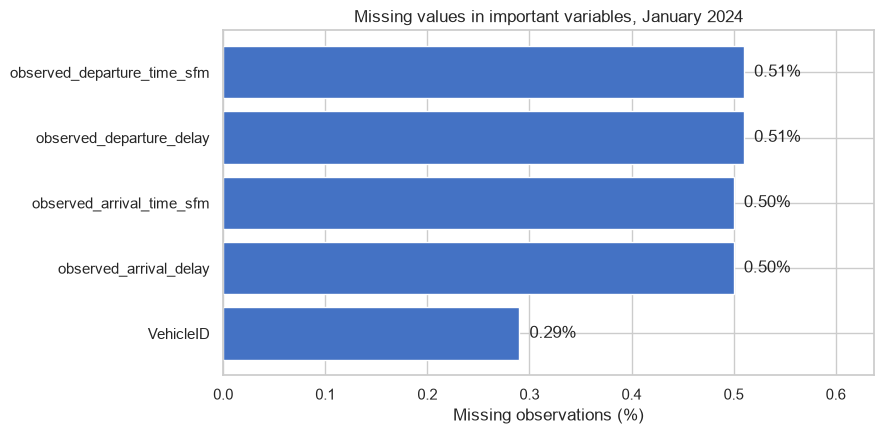

Figure saved: figure_missing_values_january.png


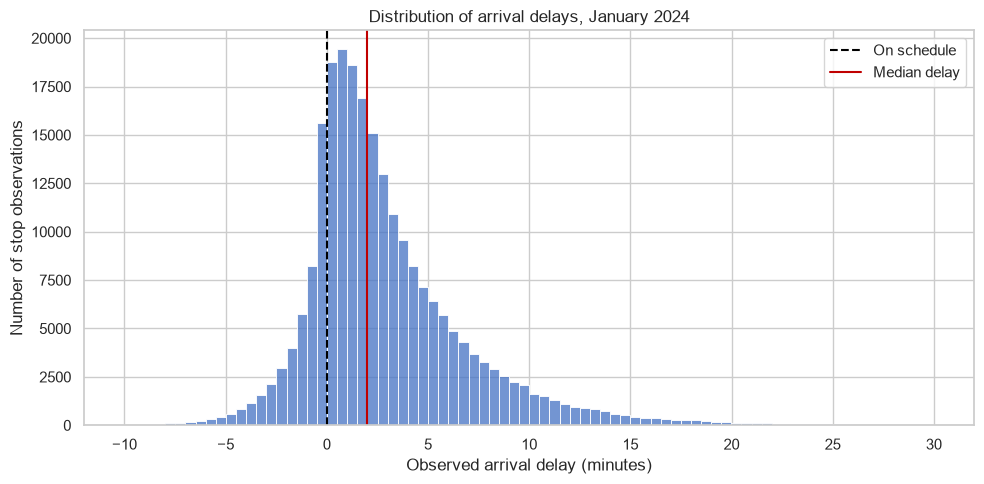


The displayed histogram contains 99.81% of non-missing observations.


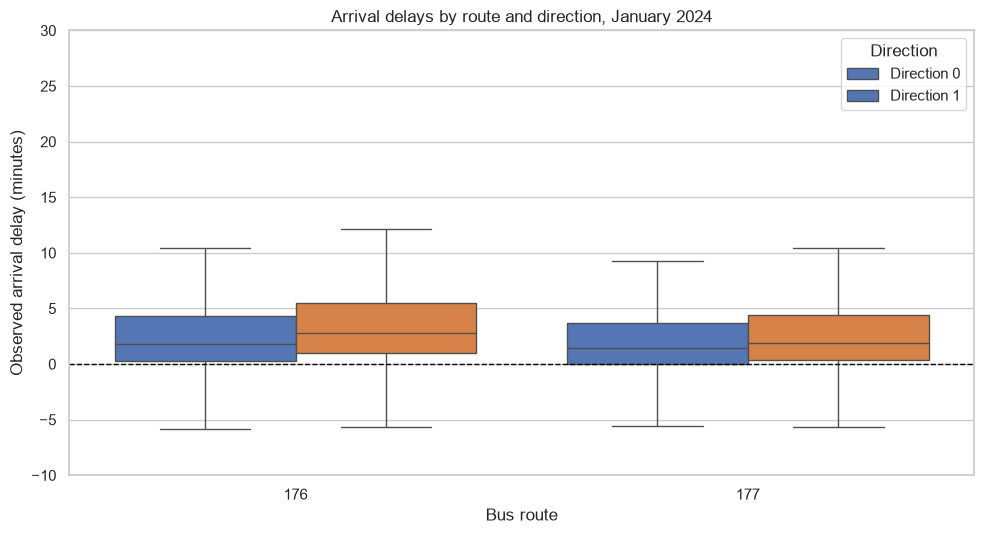

Figure saved: figure_delay_route_direction.png


In [30]:
# ---------------------------------------------------------------------------
# Figure: missing values in important variables
# ---------------------------------------------------------------------------
missing_plot = missing_summary[missing_summary["missing_percent"] > 0].sort_values(
    "missing_percent"
)

if len(missing_plot) == 0:
    print("No missing values in the important variables. Figure skipped.")
else:
    plt.figure(figsize=(9, 4.5))
    plt.barh(missing_plot.index, missing_plot["missing_percent"], color="#4472C4")

    for index, value in enumerate(missing_plot["missing_percent"]):
        plt.text(value + 0.01, index, f"{value:.2f}%", va="center")

    plt.xlabel("Missing observations (%)")
    plt.ylabel("")
    plt.title("Missing values in important variables, January 2024")
    plt.xlim(0, max(missing_plot["missing_percent"]) * 1.25)
    plt.tight_layout()

    missing_figure = FIGURES_DIR / "figure_missing_values_january.png"
    plt.savefig(missing_figure, dpi=300, bbox_inches="tight")
    plt.show()
    print("Figure saved:", missing_figure.name)

# ---------------------------------------------------------------------------
# Figure: arrival-delay distribution
# Display range is restricted to -10 to +30 minutes so the main distribution is
# visible. This affects only what is drawn — the analytical dataset is unchanged.
# ---------------------------------------------------------------------------
delay_for_plot = jan_176_177[
    jan_176_177["arrival_delay_min"].between(-10, 30)
].copy()

display_share = (
    len(delay_for_plot) / jan_176_177["arrival_delay_min"].notna().sum() * 100
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=delay_for_plot, x="arrival_delay_min", bins=80,
    color="#4472C4", edgecolor=None,
)
plt.axvline(0, color="black", linestyle="--", linewidth=1.5, label="On schedule")
plt.axvline(
    jan_176_177["arrival_delay_min"].median(),
    color="#C00000", linestyle="-", linewidth=1.5, label="Median delay",
)
plt.xlabel("Observed arrival delay (minutes)")
plt.ylabel("Number of stop observations")
plt.title("Distribution of arrival delays, January 2024")
plt.legend()
plt.tight_layout()

histogram_figure = FIGURES_DIR / "figure_arrival_delay_distribution.png"
plt.savefig(histogram_figure, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nThe displayed histogram contains {display_share:.2f}% of non-missing observations.")

# ---------------------------------------------------------------------------
# Figure: comparison by route and direction
# Outliers remain in the dataset but are hidden in this plot.
# ---------------------------------------------------------------------------
plt.figure(figsize=(10, 5.5))
sns.boxplot(
    data=jan_176_177, x="LineNumber", y="arrival_delay_min",
    hue="direction_id", showfliers=False, palette=["#4472C4", "#ED7D31"],
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.ylim(-10, 30)
plt.xlabel("Bus route")
plt.ylabel("Observed arrival delay (minutes)")
plt.title("Arrival delays by route and direction, January 2024")
plt.legend(title="Direction", labels=["Direction 0", "Direction 1"])
plt.tight_layout()

boxplot_figure = FIGURES_DIR / "figure_delay_route_direction.png"
plt.savefig(boxplot_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", boxplot_figure.name)


### Interpretation

### Initial data-quality findings

The January dataset demonstrates high overall quality. Approximately 99.5 per cent of observations contain an observed arrival delay, and all retained records were matched between GTFS and GTFS-Realtime. No exact duplicates or duplicated trip-stop keys were identified.

The median arrival delay is 119 seconds while the mean is 179 seconds. The higher mean indicates a **right-skewed distribution** caused by a limited number of severe delays. A small number of arrival observations exceed 30 minutes. These are not automatically removed, because they may represent genuine disruptions; their influence is examined later through model diagnostics and sensitivity analysis.

Because delay is right-skewed, later sections report the **median** to describe typical operations and the **95th percentile** to describe disrupted conditions and the reliability risk that passengers experience.


# 4. Processing the complete 2024 dataset

After validating January, the same chunk-based filtering procedure is applied consistently to all twelve months. Only observations for bus routes 176 and 177 are retained, and each filtered monthly dataset is written to Parquet so the year can be combined efficiently and the pipeline stays reproducible.

> **Memory note.** Each month is written to disk and released before the next begins. Twelve months are never held in memory together at this stage.


In [31]:
MONTHLY_PATTERN = "{month:02d}.parquet"

monthly_results = []

for month in range(1, 13):
    raw_path = RAW_DIR / f"gtfs_rt_2024{month:02d}.csv.gz"
    month_output = PROCESSED_DIR / MONTHLY_PATTERN.format(month=month)

    if not raw_path.is_file():
        print(f"Month {month:02d}: raw file missing, skipped")
        monthly_results.append({
            "month": month, "rows": 0,
            "examined": 0, "status": "missing raw file",
        })
        continue

    # Skip a month that has already been processed.
    if month_output.is_file():
        existing = len(pd.read_parquet(month_output, columns=["LineNumber"]))
        print(f"Month {month:02d}: already processed ({existing:,} rows)")
        monthly_results.append({
            "month": month, "rows": existing,
            "examined": existing, "status": "existing",
        })
        continue

    examined = 0
    retained = 0
    pieces = []

    for chunk in pd.read_csv(
        raw_path, sep=";", compression="gzip", chunksize=500_000,
        dtype={"LineNumber": "string"}, low_memory=False,
    ):
        examined += len(chunk)

        chunk["LineNumber"] = chunk["LineNumber"].astype("string").str.strip()
        chunk["TransportMode"] = (
            chunk["TransportMode"].astype("string").str.strip().str.upper()
        )

        selected = chunk.loc[
            (chunk["TransportMode"] == "BUS")
            & chunk["LineNumber"].isin(TARGET_LINES)
        ].copy()

        if not selected.empty:
            # The same YYYYMMDD correction validated on January, so every
            # month is processed identically.
            selected["date"] = pd.to_datetime(
                selected["date"].astype("string").str.replace(r"\.0$", "", regex=True),
                format="%Y%m%d", errors="coerce",
            )
            pieces.append(selected)
            retained += len(selected)

        # Release the chunk before reading the next one.
        del chunk, selected
        gc.collect()

    if not pieces:
        print(f"Month {month:02d}: no observations for routes 176 and 177")
        monthly_results.append({
            "month": month, "rows": 0,
            "examined": examined, "status": "no matches",
        })
        continue

    monthly = pd.concat(pieces, ignore_index=True)
    del pieces
    gc.collect()

    invalid = int(monthly["date"].isna().sum())
    if invalid:
        print(f"Month {month:02d}: dropping {invalid:,} rows with unparseable dates")
        monthly = monthly.loc[monthly["date"].notna()].reset_index(drop=True)

    monthly.to_parquet(month_output, index=False)

    size_mb = month_output.stat().st_size / 1024**2
    print(
        f"Month {month:02d}: {examined:,} examined, "
        f"{len(monthly):,} retained, saved {size_mb:.1f} MB"
    )

    monthly_results.append({
        "month": month, "rows": len(monthly),
        "examined": examined, "status": "processed",
    })

    # Release the month before moving to the next.
    del monthly
    gc.collect()

processing_summary = pd.DataFrame(monthly_results)

print("\nPROCESSING SUMMARY")
display(processing_summary)

total_retained = int(processing_summary["rows"].sum())
print(f"\nTotal filtered observations: {total_retained:,}")
print(f"Expected from the recorded run: 2,758,280")
print(f"Difference: {total_retained - 2_758_280:,}")


Month 01: 18,659,047 examined, 235,684 retained, saved 3.3 MB
Month 02: 17,687,762 examined, 219,840 retained, saved 3.0 MB
Month 03: 18,354,274 examined, 231,422 retained, saved 3.2 MB
Month 04: 18,168,030 examined, 224,131 retained, saved 3.2 MB
Month 05: 18,616,461 examined, 229,912 retained, saved 3.2 MB
Month 06: 16,997,406 examined, 219,184 retained, saved 3.2 MB
Month 07: 17,123,357 examined, 232,786 retained, saved 3.2 MB
Month 08: 17,747,633 examined, 231,367 retained, saved 3.4 MB
Month 09: 17,847,744 examined, 226,278 retained, saved 3.1 MB
Month 10: 18,782,011 examined, 236,349 retained, saved 3.3 MB
Month 11: 17,878,753 examined, 227,802 retained, saved 3.3 MB
Month 12: 17,450,236 examined, 243,525 retained, saved 3.5 MB

PROCESSING SUMMARY


,month,rows,examined,status
0,1,235684,18659047,processed
1,2,219840,17687762,processed
2,3,231422,18354274,processed
3,4,224131,18168030,processed
4,5,229912,18616461,processed
5,6,219184,16997406,processed
6,7,232786,17123357,processed
7,8,231367,17747633,processed
8,9,226278,17847744,processed
9,10,236349,18782011,processed



Total filtered observations: 2,758,280
Expected from the recorded run: 2,758,280
Difference: 0


- Verify the monthly files

In [32]:
monthly_files = sorted(PROCESSED_DIR.glob(MONTHLY_PATTERN.replace("{month:02d}", "??")))

print(f"Monthly files found: {len(monthly_files)}")
for path in monthly_files:
    size_mb = path.stat().st_size / 1024**2
    print(f"  {path.name:<20} {size_mb:>8.1f} MB")

if len(monthly_files) != 12:
    missing_months = [
        m for m in range(1, 13)
        if not (PROCESSED_DIR / MONTHLY_PATTERN.format(month=m)).is_file()
    ]
    raise ValueError(
        f"Expected 12 monthly files, found {len(monthly_files)}. "
        f"Missing months: {missing_months}"
    )

print("\nAll twelve monthly files are present.")


Monthly files found: 12
  01.parquet                3.3 MB
  02.parquet                3.0 MB
  03.parquet                3.2 MB
  04.parquet                3.2 MB
  05.parquet                3.2 MB
  06.parquet                3.2 MB
  07.parquet                3.2 MB
  08.parquet                3.4 MB
  09.parquet                3.1 MB
  10.parquet                3.3 MB
  11.parquet                3.3 MB
  12.parquet                3.5 MB

All twelve monthly files are present.


- Disk usage check

In [33]:
import shutil as _shutil

_, _, free_bytes = _shutil.disk_usage(PROJECT_DIR)
processed_bytes = sum(p.stat().st_size for p in PROCESSED_DIR.glob("*.parquet"))

print(f"Processed folder: {processed_bytes / 1024**3:.2f} GB")
print(f"Free disk space : {free_bytes / 1024**3:.1f} GB")

if free_bytes < 10 * 1024**3:
    print("\nWARNING: less than 10 GB free. The full-year combine step and the")
    print("sequence matrices need several GB. Free space before continuing.")


Processed folder: 0.04 GB
Free disk space : 305.7 GB


# 5. Full-year dataset and monthly patterns

The twelve filtered monthly files are combined into a single dataset. Temporal variables are created, including month, weekday and scheduled hour. Monthly data coverage and arrival-delay patterns are then examined to verify that the dataset covers the complete year and to identify seasonal variation.

- Combine the twelve monthly files
python

In [35]:
import calendar

monthly_files = sorted(
    PROCESSED_DIR.glob(MONTHLY_PATTERN.replace("{month:02d}", "??"))
)

print(f"Monthly files found: {len(monthly_files)}")

if len(monthly_files) != 12:
    raise ValueError(
        f"Expected 12 monthly files, found {len(monthly_files)}."
    )

yearly_parts = []

for path in monthly_files:
    part = pd.read_parquet(path)
    part["date"] = pd.to_datetime(part["date"], errors="coerce")
    yearly_parts.append(part)
    print(f"{path.name:<20} {len(part):>10,} rows")

full_2024 = pd.concat(yearly_parts, ignore_index=True)

# Release the monthly parts before building the derived columns.
del yearly_parts
gc.collect()

# Stable sort. Sequence windows in Section 20 index absolute row positions, and
# the saved prediction files are joined on row order, so a non-stable sort could
# permute equal-key rows and break that alignment.
full_2024 = full_2024.sort_values(
    ["date", "LineNumber", "direction_id", "trip_id", "stop_sequence"],
    kind="mergesort",
).reset_index(drop=True)

print(f"\nCombined: {len(full_2024):,} rows")
print(f"Expected:  2,758,280")
print(f"Difference: {len(full_2024) - 2_758_280:,}")


Monthly files found: 12
01.parquet              235,684 rows
02.parquet              219,840 rows
03.parquet              231,422 rows
04.parquet              224,131 rows
05.parquet              229,912 rows
06.parquet              219,184 rows
07.parquet              232,786 rows
08.parquet              231,367 rows
09.parquet              226,278 rows
10.parquet              236,349 rows
11.parquet              227,802 rows
12.parquet              243,525 rows

Combined: 2,758,280 rows
Expected:  2,758,280
Difference: 0


- Temporal variables

In [36]:
full_2024["month"] = full_2024["date"].dt.month
full_2024["weekday"] = full_2024["date"].dt.dayofweek
full_2024["is_weekend"] = (full_2024["weekday"] >= 5).astype(int)

# scheduled_arrival_time_sfm is seconds from midnight, so integer division by
# 3600 recovers the scheduled hour. The modulo keeps hour 24 as hour 0.
full_2024["scheduled_hour"] = (
    full_2024["scheduled_arrival_time_sfm"]
    .floordiv(3600)
    .mod(24)
    .astype("Int64")
)

full_2024["arrival_delay_min"] = full_2024["observed_arrival_delay"] / 60
full_2024["departure_delay_min"] = full_2024["observed_departure_delay"] / 60

print("FULL-YEAR DATASET")
print(f"Rows:         {len(full_2024):,}")
print(f"Service days: {full_2024['date'].nunique()}")
print(f"Date range:   {full_2024['date'].min().date()} to {full_2024['date'].max().date()}")

print("\nRoute share of observations (%):")
print(
    full_2024["LineNumber"].value_counts(normalize=True).mul(100).round(1).to_string()
)

print("\nTemporal variable ranges:")
for column in ["month", "weekday", "scheduled_hour"]:
    values = full_2024[column].dropna()
    print(
        f"  {column:<16} dtype={full_2024[column].dtype} "
        f"min={values.min()} max={values.max()}"
    )


FULL-YEAR DATASET
Rows:         2,758,280
Service days: 366
Date range:   2024-01-01 to 2024-12-31

Route share of observations (%):
LineNumber
176    54.6
177    45.4

Temporal variable ranges:
  month            dtype=int32 min=1 max=12
  weekday          dtype=int32 min=0 max=6
  scheduled_hour   dtype=Int64 min=0 max=23


- Service-date coverage audit

In [37]:
# 2024 is a leap year, so a complete year has 366 days. Any absent service date
# is reported rather than assumed away: the recorded run was missing one date,
# and the gap matters because the chronological split depends on the calendar.
expected_dates = pd.date_range("2024-01-01", "2024-12-31", freq="D")
present_dates = pd.DatetimeIndex(full_2024["date"].unique())

missing_dates = expected_dates.difference(present_dates)

print(f"Expected service dates: {len(expected_dates)}")
print(f"Present in dataset:     {len(present_dates)}")
print(f"Absent:                 {len(missing_dates)}")

if len(missing_dates):
    print("\nAbsent service dates:")
    for date in missing_dates:
        print(f"  {date.date()} ({date.day_name()})")
    print(
        "\nThis gap has not been traced to a cause. It is recorded here so the "
        "temporal coverage is not described as exhaustive."
    )
else:
    print("\nAll 366 service dates are represented.")


Expected service dates: 366
Present in dataset:     366
Absent:                 0

All 366 service dates are represented.


- Save the full-year dataset

In [38]:
full_2024_file = PROCESSED_DIR / "bus_176_177_2024_full.parquet"
full_2024.to_parquet(full_2024_file, index=False)

print("Saved:", full_2024_file.name)
print("Size :", round(full_2024_file.stat().st_size / 1024**2, 1), "MB")


Saved: bus_176_177_2024_full.parquet
Size : 41.8 MB


- Monthly coverage and delay variation

In [39]:
monthly_summary = (
    full_2024
    .groupby("month")
    .agg(
        observations=("LineNumber", "size"),
        available_arrival_delays=("observed_arrival_delay", "count"),
        mean_delay_min=("arrival_delay_min", "mean"),
        median_delay_min=("arrival_delay_min", "median"),
        p95_delay_min=("arrival_delay_min", lambda v: v.quantile(0.95)),
    )
    .reset_index()
)

monthly_summary["month_name"] = monthly_summary["month"].map(
    lambda m: calendar.month_abbr[m]
)

for column in ["mean_delay_min", "median_delay_min", "p95_delay_min"]:
    monthly_summary[column] = monthly_summary[column].round(2)

print("MONTHLY SUMMARY")
display(monthly_summary)


MONTHLY SUMMARY


,month,observations,available_arrival_delays,mean_delay_min,median_delay_min,p95_delay_min,month_name
0,1,235684,234498,2.98,1.98,10.90,Jan
1,2,219840,209597,1.85,1.35,7.53,Feb
2,3,231422,224998,2.34,1.37,7.73,Mar
3,4,224131,221922,1.78,1.23,6.88,Apr
4,5,229912,224756,2.99,1.72,11.40,May
5,6,219184,217159,3.01,1.62,10.68,Jun
6,7,232786,231689,1.66,1.07,6.75,Jul
7,8,231367,230367,2.94,1.80,11.02,Aug
8,9,226278,225515,2.59,1.67,9.62,Sep
9,10,236349,234463,3.98,1.98,15.92,Oct


- Visualisation:Monthly Coverage and Delay Variation

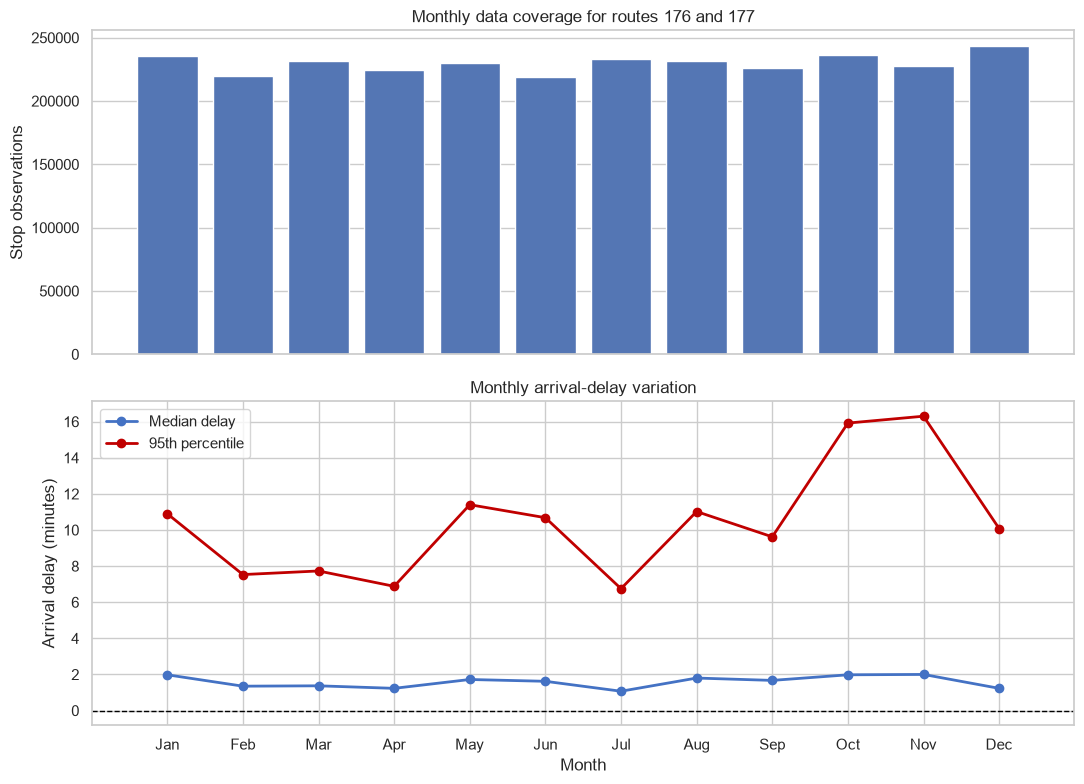

Figure saved: figure_monthly_coverage_and_delay.png

Largest 95th-percentile delay: Nov (16.30 min)
Smallest 95th-percentile delay: Jul (6.75 min)


In [40]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.barplot(
    data=monthly_summary, x="month_name", y="observations",
    color="#4472C4", ax=axes[0],
)
axes[0].set_title("Monthly data coverage for routes 176 and 177")
axes[0].set_xlabel("")
axes[0].set_ylabel("Stop observations")

axes[1].plot(
    monthly_summary["month_name"], monthly_summary["median_delay_min"],
    marker="o", linewidth=2, color="#4472C4", label="Median delay",
)
axes[1].plot(
    monthly_summary["month_name"], monthly_summary["p95_delay_min"],
    marker="o", linewidth=2, color="#C00000", label="95th percentile",
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Monthly arrival-delay variation")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Arrival delay (minutes)")
axes[1].legend()

plt.tight_layout()

monthly_figure = FIGURES_DIR / "figure_monthly_coverage_and_delay.png"
plt.savefig(monthly_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", monthly_figure.name)

peak_month = monthly_summary.loc[monthly_summary["p95_delay_min"].idxmax()]
low_month = monthly_summary.loc[monthly_summary["p95_delay_min"].idxmin()]
print(f"\nLargest 95th-percentile delay: {peak_month['month_name']} "
      f"({peak_month['p95_delay_min']:.2f} min)")
print(f"Smallest 95th-percentile delay: {low_month['month_name']} "
      f"({low_month['p95_delay_min']:.2f} min)")


### Interpretation of monthly variation (Section 5)

Monthly observation volumes are relatively stable, indicating consistent coverage throughout 2024. Delay conditions, however, vary substantially: **October and November show the highest mean and 95th-percentile delays, while July shows the lowest values.**

The monthly medians vary far less than the means and 95th percentiles. This indicates that seasonal differences are primarily driven by **severe disruption events** rather than by a uniform deterioration of all services. Model performance should therefore be evaluated separately across months and under both normal and disrupted operating conditions.


# 6. Full-year quality and dwell-time assessment

Before defining the final cleaning rules, the full-year dataset is examined for matching failures, duplicated trip-stop observations, missing arrival information and implausible dwell times.

**Dwell time** is the time between arrival at and departure from a stop. It is operationally relevant because it is where boarding happens — and because SL introduced boarding through all doors on these routes in 2025 specifically to reduce it. Since this dataset covers 2024, it represents a pre-implementation baseline.

- Matching flags and duplicates

In [41]:
print("MATCHING FLAGS FOR THE COMPLETE YEAR")
for column in [
    "tripupdates_and_gtfs_not_merged_within_service_id",
    "tripupdates_not_merged_with_stoptimes_or_trip",
]:
    if column not in full_2024.columns:
        print(f"\n{column}: not present in this dataset")
        continue
    print(f"\n{column}:")
    display(
        full_2024[column]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="observations")
    )

trip_stop_key = [
    "date", "route_id", "trip_id", "direction_id",
    "stop_sequence", "observed_stop_id",
]
present_key = [c for c in trip_stop_key if c in full_2024.columns]

exact_duplicates = int(full_2024.duplicated().sum())
key_duplicates = int(full_2024.duplicated(subset=present_key, keep=False).sum())

print("\nDUPLICATE ASSESSMENT")
print(f"Exact duplicate rows:                {exact_duplicates:,}")
print(f"Rows with duplicated trip-stop keys: {key_duplicates:,}")

if key_duplicates:
    print(
        "\nDuplicated trip-stop keys make the forward shift which builds the "
        "target ambiguous. Resolve these before modelling."
    )
else:
    print("\nNo duplicated trip-stop keys. The target shift is unambiguous.")


MATCHING FLAGS FOR THE COMPLETE YEAR

tripupdates_and_gtfs_not_merged_within_service_id:


,value,observations
0,f,2758280



tripupdates_not_merged_with_stoptimes_or_trip:


,value,observations
0,f,2758280



DUPLICATE ASSESSMENT
Exact duplicate rows:                0
Rows with duplicated trip-stop keys: 0

No duplicated trip-stop keys. The target shift is unambiguous.


- Arrival availability by month

In [42]:
monthly_availability = (
    full_2024
    .groupby("month")
    .agg(
        observations=("LineNumber", "size"),
        available_arrivals=("observed_arrival_delay", "count"),
    )
    .reset_index()
)

monthly_availability["missing_percent"] = (
    100 * (1 - monthly_availability["available_arrivals"]
           / monthly_availability["observations"])
)

monthly_availability["month_name"] = monthly_availability["month"].map(
    lambda m: calendar.month_abbr[m]
)

print("ARRIVAL-DATA AVAILABILITY")
display(monthly_availability.round(2))

worst = monthly_availability.loc[monthly_availability["missing_percent"].idxmax()]
print(f"\nHighest missing rate: {worst['month_name']} "
      f"({worst['missing_percent']:.2f}%)")


ARRIVAL-DATA AVAILABILITY


,month,observations,available_arrivals,missing_percent,month_name
0,1,235684,234498,0.5,Jan
1,2,219840,209597,4.66,Feb
2,3,231422,224998,2.78,Mar
3,4,224131,221922,0.99,Apr
4,5,229912,224756,2.24,May
5,6,219184,217159,0.92,Jun
6,7,232786,231689,0.47,Jul
7,8,231367,230367,0.43,Aug
8,9,226278,225515,0.34,Sep
9,10,236349,234463,0.8,Oct



Highest missing rate: Feb (4.66%)


- Dwell-time variables

In [43]:
full_2024["observed_dwell_sec"] = (
    full_2024["observed_departure_time_sfm"]
    - full_2024["observed_arrival_time_sfm"]
)

full_2024["scheduled_dwell_sec"] = (
    full_2024["scheduled_departure_time_sfm"]
    - full_2024["scheduled_arrival_time_sfm"]
)

full_2024["excess_dwell_sec"] = (
    full_2024["observed_dwell_sec"] - full_2024["scheduled_dwell_sec"]
)

dwell_columns = ["observed_dwell_sec", "scheduled_dwell_sec", "excess_dwell_sec"]

print("DWELL-TIME DISTRIBUTIONS IN SECONDS")
display(
    full_2024[dwell_columns]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .round(2)
)

negative_dwell = int((full_2024["observed_dwell_sec"] < 0).sum())
long_dwell = int((full_2024["observed_dwell_sec"] > 600).sum())

print("\nPOTENTIALLY IMPLAUSIBLE DWELL TIMES")
print(f"Negative observed dwell:           {negative_dwell:,}")
print(f"Observed dwell above 10 minutes:   {long_dwell:,}")

print(
    "\nA negative dwell suggests inconsistent arrival and departure reporting "
    "for the same stop event. Values above ten minutes may represent terminal "
    "layovers or measurement artefacts rather than ordinary stop operations."
)


DWELL-TIME DISTRIBUTIONS IN SECONDS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
observed_dwell_sec,2715689.0,18.66,44.21,0.0,0.0,0.0,0.0,10.0,19.0,77.0,194.0,8540.0
scheduled_dwell_sec,2758280.0,0.52,6.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,120.0
excess_dwell_sec,2715689.0,18.16,43.35,-120.0,0.0,0.0,0.0,10.0,19.0,73.0,191.0,8540.0



POTENTIALLY IMPLAUSIBLE DWELL TIMES
Negative observed dwell:           0
Observed dwell above 10 minutes:   1,218

A negative dwell suggests inconsistent arrival and departure reporting for the same stop event. Values above ten minutes may represent terminal layovers or measurement artefacts rather than ordinary stop operations.


#### Visualisation: quality and dwell time

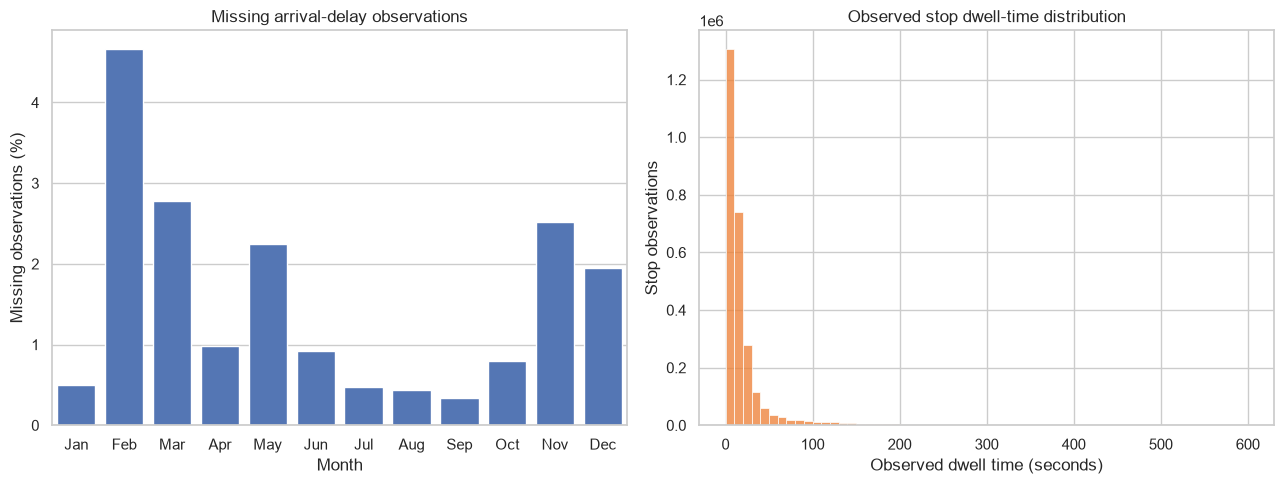

Figure saved: figure_full_year_quality_and_dwell.png

Displayed dwell values: 2,714,471 of 2,715,689 non-missing


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Monthly missing-arrival rate
sns.barplot(
    data=monthly_availability, x="month_name", y="missing_percent",
    color="#4472C4", ax=axes[0],
)
axes[0].set_title("Missing arrival-delay observations")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Missing observations (%)")

# Dwell distribution, restricted to 0-600 seconds so the main shape is visible.
dwell_for_plot = full_2024[full_2024["observed_dwell_sec"].between(0, 600)].copy()

sns.histplot(
    data=dwell_for_plot, x="observed_dwell_sec", bins=60,
    color="#ED7D31", edgecolor=None, ax=axes[1],
)
axes[1].set_title("Observed stop dwell-time distribution")
axes[1].set_xlabel("Observed dwell time (seconds)")
axes[1].set_ylabel("Stop observations")

plt.tight_layout()

quality_figure = FIGURES_DIR / "figure_full_year_quality_and_dwell.png"
plt.savefig(quality_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", quality_figure.name)

print(f"\nDisplayed dwell values: {len(dwell_for_plot):,} of "
      f"{int(full_2024['observed_dwell_sec'].notna().sum()):,} non-missing")


- Save the assessed full-year dataset

In [45]:
full_2024.to_parquet(full_2024_file, index=False)

print("Saved:", full_2024_file.name)
print("Size :", round(full_2024_file.stat().st_size / 1024**2, 1), "MB")

print("\nColumns now available for target construction:")
for name in sorted(full_2024.columns):
    print(" -", name)


Saved: bus_176_177_2024_full.parquet
Size : 47.3 MB

Columns now available for target construction:
 - LineID
 - LineNumber
 - TransportMode
 - VehicleID
 - arrival_delay_min
 - date
 - departure_delay_min
 - direction_id
 - dist_traveled
 - excess_dwell_sec
 - is_weekend
 - month
 - observed_StopAreaID
 - observed_arrival_delay
 - observed_arrival_time_sfm
 - observed_arrival_uncertainty
 - observed_departure_delay
 - observed_departure_time_sfm
 - observed_departure_uncertainty
 - observed_dwell_sec
 - observed_stop_id
 - planned_departure_sfm
 - planned_departure_tripupdates_sfm
 - previous_StopAreaID
 - previous_stop_id
 - route_id
 - scheduled_arrival_time_sfm
 - scheduled_departure_time_sfm
 - scheduled_dwell_sec
 - scheduled_hour
 - shape_id
 - stop_headsign
 - stop_sequence
 - trip_id
 - tripupdates_and_gtfs_not_merged_within_service_id
 - tripupdates_not_merged_with_stoptimes_or_trip
 - weekday


- Interpretation


### Full-year quality findings

All observations were matched between GTFS and GTFS-Realtime, and no duplicate trip-stop records were identified. Missing arrival observations vary by month and are most frequent in February, but remain limited overall.

Observed dwell times are **strongly right-skewed**. The median is around ten seconds and the 99th percentile is under 200 seconds, while a small number of observations exceed ten minutes. The original observations are preserved for diagnostic analysis. However, dwell times above ten minutes are **excluded from the primary prediction dataset** in Section 7, because they may represent terminal layovers, unusual disruptions or measurement errors rather than ordinary stop operations.

The dwell field is retained in the full-year table so that the exclusion can be revisited in a robustness check without reprocessing the raw data.


# 7. Construction of the next-stop prediction dataset

The prediction unit is a **bus departure from a current stop**. The target variable is the observed arrival delay at the next recorded stop. Information known at departure — current delay and dwell time — can therefore be used without introducing future-data leakage.

Rows without an observed next-stop arrival delay are excluded, because the target cannot be imputed.

## Prediction task

For a bus departing from stop *i*, the arrival delay at the immediately next stop is modelled as:

$$\hat{y}(i+1) = f(X_i)$$

where $X_i$ contains only quantities that exist at the moment of departure. Positive values denote late arrivals; negative values denote early arrivals.


- Build the target

In [46]:
group_columns = ["date", "route_id", "trip_id", "direction_id"]

# Stable sort so within-trip ordering is deterministic. The sequence models in
# Section 20 index absolute row positions, so a non-stable sort could permute
# equal-key rows and break the alignment between saved predictions.
full_2024 = full_2024.sort_values(
    group_columns + ["stop_sequence"], kind="mergesort"
).reset_index(drop=True)

trip_groups = full_2024.groupby(group_columns, sort=False)

# Forward shift: attributes of the NEXT recorded stop. This forms the label.
# Historical features in Section 10 use a BACKWARD shift — the two move in
# opposite directions on purpose, so inputs never contain the target.
full_2024["next_arrival_delay_sec"] = trip_groups["observed_arrival_delay"].shift(-1)
full_2024["next_stop_id"] = trip_groups["observed_stop_id"].shift(-1)
full_2024["next_stop_sequence"] = trip_groups["stop_sequence"].shift(-1)
full_2024["next_segment_distance_m"] = trip_groups["dist_traveled"].shift(-1)
full_2024["next_scheduled_arrival_sfm"] = trip_groups["scheduled_arrival_time_sfm"].shift(-1)

print("NEXT-STOP FIELDS CONSTRUCTED")
print(f"Rows with a next-stop arrival: {int(full_2024['next_arrival_delay_sec'].notna().sum()):,}")
print(f"Rows without (terminal stops): {int(full_2024['next_arrival_delay_sec'].isna().sum()):,}")

display(
    full_2024[[
        "LineNumber", "stop_sequence", "next_stop_sequence",
        "observed_arrival_delay", "next_arrival_delay_sec",
    ]].head(8)
)


NEXT-STOP FIELDS CONSTRUCTED
Rows with a next-stop arrival: 2,646,528
Rows without (terminal stops): 111,752


,LineNumber,stop_sequence,next_stop_sequence,observed_arrival_delay,next_arrival_delay_sec
0,176,1,2.0,25.0,54.0
1,176,2,3.0,54.0,53.0
2,176,3,4.0,53.0,70.0
3,176,4,5.0,70.0,104.0
4,176,5,6.0,104.0,93.0
5,176,6,7.0,93.0,87.0
6,176,7,8.0,87.0,74.0
7,176,8,9.0,74.0,31.0


- Cleaning conditions and sequential audit

In [47]:
# Each condition is stated explicitly so the filter is transparent and can be
# revisited. The audit below walks them in order, showing how many rows each
# one removes — a single "rows removed" total would hide where they went.
conditions = pd.DataFrame({
    # A target only exists if the shifted row is genuinely further along the
    # trip. Without this, a duplicate stop_sequence or an unsorted group would
    # pair a stop with itself.
    "valid_next_stop": full_2024["next_stop_sequence"] > full_2024["stop_sequence"],
    "current_arrival_available": full_2024["observed_arrival_delay"].notna(),
    "current_departure_available": full_2024["observed_departure_delay"].notna(),
    "next_arrival_available": full_2024["next_arrival_delay_sec"].notna(),
    "current_dwell_available": full_2024["observed_dwell_sec"].notna(),
    # Dwell above ten minutes may indicate a terminal layover or a measurement
    # artefact rather than ordinary stop operation. These rows are excluded from
    # the primary dataset but retained in the full-year table for robustness
    # diagnostics, so the rule can be revisited without reprocessing the raw data.
    "plausible_current_dwell": full_2024["observed_dwell_sec"].between(0, 600, inclusive="both"),
    "next_distance_available": full_2024["next_segment_distance_m"].notna(),
})

cleaning_steps = []
current_mask = pd.Series(True, index=full_2024.index)

cleaning_steps.append({
    "step": "All route observations",
    "remaining_rows": int(current_mask.sum()),
    "removed_here": 0,
})

for column in conditions.columns:
    before = int(current_mask.sum())
    current_mask &= conditions[column].fillna(False)
    after = int(current_mask.sum())
    cleaning_steps.append({
        "step": column,
        "remaining_rows": after,
        "removed_here": before - after,
    })

cleaning_summary = pd.DataFrame(cleaning_steps)

print("CLEANING SUMMARY")
display(cleaning_summary)

model_data = full_2024.loc[current_mask].copy()

print(f"\nRows retained: {len(model_data):,}")
print(f"Rows removed : {len(full_2024) - len(model_data):,}")
print(f"Retained     : {100 * len(model_data) / len(full_2024):.2f}%")
print("Expected from the recorded run: 2,643,576 (95.84%)")


CLEANING SUMMARY


,step,remaining_rows,removed_here
0,All route observations,2758280,0
1,valid_next_stop,2686659,71621
2,current_arrival_available,2644892,41767
3,current_departure_available,2644795,97
4,next_arrival_available,2644777,18
5,current_dwell_available,2644777,0
6,plausible_current_dwell,2643576,1201
7,next_distance_available,2643576,0



Rows retained: 2,643,576
Rows removed : 114,704
Retained     : 95.84%
Expected from the recorded run: 2,643,576 (95.84%)


- Target variable and severe-delay flag

In [48]:
model_data[TARGET_COLUMN] = model_data["next_arrival_delay_sec"] / 60

# Extreme delays are flagged, never silently dropped. They are genuine
# disruptions, and removing them would flatter every metric while removing
# exactly the cases an operational warning system exists to catch.
model_data["severe_next_stop_delay"] = (
    model_data[TARGET_COLUMN] > 30
).astype(int)

print("TARGET DISTRIBUTION IN MINUTES")
display(
    model_data[TARGET_COLUMN]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame("value")
    .round(2)
)

print(f"\nSevere next-stop delays above 30 min: "
      f"{int(model_data['severe_next_stop_delay'].sum()):,}")
print(f"Expected from the recorded run: 18,897")

print("\nOBSERVATIONS BY ROUTE")
display(
    model_data["LineNumber"]
    .value_counts()
    .rename_axis("route")
    .reset_index(name="observations")
)


TARGET DISTRIBUTION IN MINUTES


,value
count,2643576.00
mean,2.78
std,6.28
min,-25.73
1%,-4.62
5%,-2.23
25%,0.20
50%,1.62
75%,3.77
95%,10.32



Severe next-stop delays above 30 min: 18,897
Expected from the recorded run: 18,897

OBSERVATIONS BY ROUTE


,route,observations
0,176,1448682
1,177,1194894


- Save the modelling dataset

In [49]:
model_data_file = PROCESSED_DIR / "model_dataset_176_177_2024.parquet"
model_data.to_parquet(model_data_file, index=False)

print("Saved:", model_data_file.name)
print("Size :", round(model_data_file.stat().st_size / 1024**2, 1), "MB")


Saved: model_dataset_176_177_2024.parquet
Size : 60.0 MB


### Visualisation: rows retained through cleaning

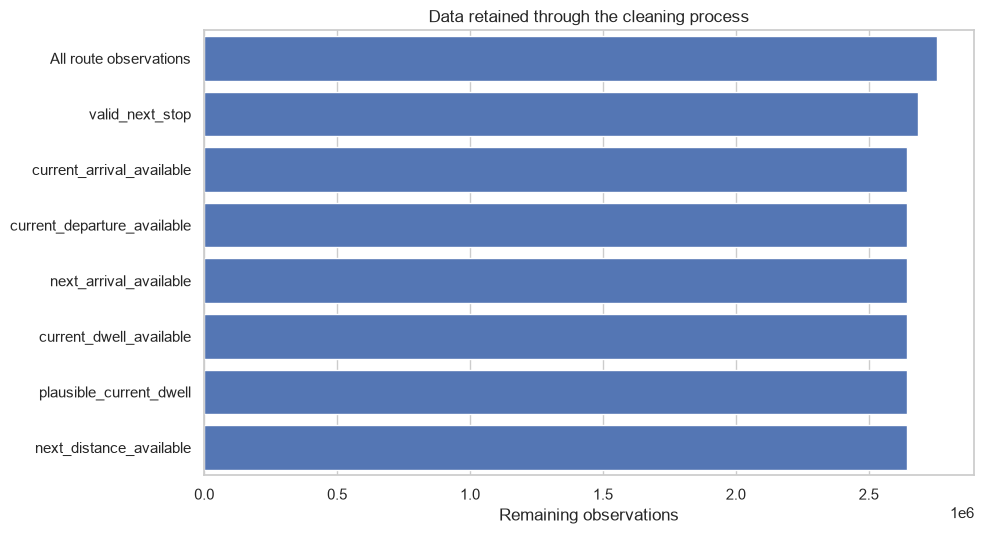

Figure saved: figure_prediction_data_cleaning.png

Removed at each step:


,step,removed_here
1,valid_next_stop,71621
2,current_arrival_available,41767
3,current_departure_available,97
4,next_arrival_available,18
6,plausible_current_dwell,1201


In [50]:
plot_summary = cleaning_summary.copy()

plt.figure(figsize=(10, 5.5))
sns.barplot(
    data=plot_summary, x="remaining_rows", y="step", color="#4472C4",
)
plt.xlabel("Remaining observations")
plt.ylabel("")
plt.title("Data retained through the cleaning process")
plt.xlim(0, len(full_2024) * 1.05)
plt.tight_layout()

cleaning_figure = FIGURES_DIR / "figure_prediction_data_cleaning.png"
plt.savefig(cleaning_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", cleaning_figure.name)
print("\nRemoved at each step:")
display(
    plot_summary[plot_summary["removed_here"] > 0][["step", "removed_here"]]
)


- Release the full-year table

In [51]:
# The full-year table has served its purpose: the modelling dataset is saved.
# Releasing it here frees several GB before feature engineering builds its own
# encoded matrices.
full_2024_size_gb = full_2024.memory_usage(deep=True).sum() / 1024**3

del full_2024, conditions, current_mask, trip_groups
gc.collect()

print(f"Released the full-year table (~{full_2024_size_gb:.2f} GB in memory).")
print("Remaining in scope: model_data, cleaning_summary, monthly_summary")


Released the full-year table (~0.94 GB in memory).
Remaining in scope: model_data, cleaning_summary, monthly_summary


### Interpretation of the cleaning process

The largest reduction occurs when terminal observations without a subsequent stop are removed. Additional reductions result mainly from missing real-time arrival or departure information. Only a small number of observations are excluded by the ten-minute dwell-time threshold.

Overall, **95.84 per cent of the original observations are retained**, indicating that the cleaning procedure preserves most of the available operational information.

The reduction from 2,758,280 route-filtered observations to 2,643,576 modelling examples is 114,704 rows, about 4.2 per cent. This should be read as a row-count audit, not as evidence that every removed record was an error: a terminal stop has no downstream arrival by definition, so its exclusion is structural rather than a data-quality defect.

Because the removed rows are concentrated at the end of trips, the cleaning procedure does not systematically remove difficult or disrupted operations. The severe-delay flag confirms this: 18,897 next-stop delays above thirty minutes remain in the modelling dataset.


# 8. Stop-level and spatial descriptive analysis

Static GTFS stop information is linked to the prediction dataset to provide stop names and geographical coordinates. Delay accumulation at a stop is measured as the difference between observed departure delay and observed arrival delay, in seconds.

- A **positive** value indicates the bus lost time while serving the stop.
- A **negative** value indicates partial delay recovery.

> **This measures delay gained during stop service** — not total lateness on arrival, and not delay gained while travelling to the next stop.

- Load stops and attach metadata

In [52]:
stops = pd.read_csv(RAW_DIR / "stops.csv", sep=None, engine="python", dtype="string")

print(f"Stop records: {len(stops):,}")
print("Columns:", stops.columns.tolist())

required_stop_columns = ["stop_id", "stop_name", "stop_lat", "stop_lon"]
missing_stop_columns = [c for c in required_stop_columns if c not in stops.columns]
assert not missing_stop_columns, f"Missing stop columns: {missing_stop_columns}"


def normalize_identifier(series):
    """Convert numeric GTFS identifiers to consistent strings.

    This is the fix for a real failure in an earlier version of the pipeline:
    long numeric stop identifiers were shifted inside a column that also held
    missing values, which forced a float conversion and lost precision. The
    next-stop match rate fell to 49.55% as a result. Routing through pandas'
    nullable Int64 and then to string preserves every digit exactly.
    """
    return (
        pd.to_numeric(series, errors="coerce")
        .astype("Int64")
        .astype("string")
    )


stops["stop_id_key"] = normalize_identifier(stops["stop_id"])
stops["stop_lat"] = pd.to_numeric(stops["stop_lat"], errors="coerce")
stops["stop_lon"] = pd.to_numeric(stops["stop_lon"], errors="coerce")

model_data["current_stop_key"] = normalize_identifier(model_data["observed_stop_id"])

# next_stop_id comes from the forward shift of observed_stop_id, so it must be
# normalised the same way — the shift itself is safe only because the source
# column was already exact strings at the point of shifting.
model_data["next_stop_key"] = normalize_identifier(model_data["next_stop_id"])

print("\nIdentifier dtypes:")
print("  current_stop_key:", model_data["current_stop_key"].dtype)
print("  next_stop_key:   ", model_data["next_stop_key"].dtype)


Stop records: 21,661
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'location_type', 'parent_station', 'platform_code']

Identifier dtypes:
  current_stop_key: string
  next_stop_key:    string



### Recompute the next-stop identifier as an exact string, then re-attach it. and - Join current and next stop information

In [71]:
group_columns = ["date", "route_id", "trip_id", "direction_id"]
record_key = group_columns + ["stop_sequence"]

# Clear anything left by earlier attempts at this fix.
stale = [
    "next_stop_key", "next_stop_name", "next_stop_lat", "next_stop_lon",
    "next_stop_key_exact", "current_stop_key_exact",
    "current_stop_key", "current_stop_name", "current_stop_lat", "current_stop_lon",
]
model_data = model_data.drop(columns=[c for c in stale if c in model_data.columns])

# ---------------------------------------------------------------------------
# 1. Current-stop metadata
# ---------------------------------------------------------------------------
model_data["current_stop_key"] = normalize_identifier(model_data["observed_stop_id"])

base_lookup = (
    stops[["stop_id_key", "stop_name", "stop_lat", "stop_lon"]]
    .dropna(subset=["stop_id_key"])
    .drop_duplicates(subset=["stop_id_key"])
)

model_data = model_data.merge(
    base_lookup.rename(columns={
        "stop_id_key": "current_stop_key",
        "stop_name": "current_stop_name",
        "stop_lat": "current_stop_lat",
        "stop_lon": "current_stop_lon",
    }),
    on="current_stop_key", how="left", validate="many_to_one",
)

# ---------------------------------------------------------------------------
# 2. Next-stop identifier, rebuilt as strings
# ---------------------------------------------------------------------------
# The forward shift in Section 7 ran while observed_stop_id was still numeric.
# Because that column holds missing values at terminal stops, pandas stored it
# as float64, and long GTFS identifiers cannot be represented exactly in
# float64 — the trailing digits were lost, dropping the match rate to 49.55%.
# The shift must operate on strings.

key_source = model_data[record_key + ["observed_stop_id"]].copy()
key_source["current_stop_key_exact"] = normalize_identifier(
    key_source["observed_stop_id"]
)

exact_lookup = (
    key_source
    .assign(
        next_stop_key_exact=lambda d: d
        .groupby(group_columns, sort=False)["current_stop_key_exact"]
        .shift(-1)
    )
    .loc[:, record_key + ["next_stop_key_exact"]]
    .drop_duplicates(record_key)
)

# model_data carries no next_stop_key_exact, so this merge cannot collide.
assert "next_stop_key_exact" not in model_data.columns

model_data = model_data.merge(
    exact_lookup, on=record_key, how="left", validate="one_to_one"
)

model_data = model_data.rename(columns={"next_stop_key_exact": "next_stop_key"})
model_data["next_stop_id"] = model_data["next_stop_key"].astype("string")

# ---------------------------------------------------------------------------
# 3. Next-stop metadata
# ---------------------------------------------------------------------------
model_data = model_data.merge(
    base_lookup.rename(columns={
        "stop_id_key": "next_stop_key",
        "stop_name": "next_stop_name",
        "stop_lat": "next_stop_lat",
        "stop_lon": "next_stop_lon",
    }),
    on="next_stop_key", how="left", validate="many_to_one",
)

# ---------------------------------------------------------------------------
# 4. Match-rate report
# ---------------------------------------------------------------------------
current_rate = model_data["current_stop_name"].notna().mean() * 100
next_rate = model_data["next_stop_name"].notna().mean() * 100

keyed = model_data["next_stop_key"].notna()
keyed_match = model_data.loc[keyed, "next_stop_name"].notna().mean() * 100

print("STOP MATCHING")
print(f"Current-stop match rate:          {current_rate:.2f}%")
print(f"Next-stop match rate (all rows):  {next_rate:.2f}%")
print(f"Next-stop match rate (keyed rows): {keyed_match:.2f}%")
print(f"\nRows without a next-stop key: {int((~keyed).sum()):,}")
print("  These are terminal stops — no downstream stop exists, so the shift")
print("  produces no identifier. They are removed by the Section 7 cleaning.")

print("\nExample current-to-next stop pairs:")
display(
    model_data[["LineNumber", "direction_id", "current_stop_name", "next_stop_name"]]
    .drop_duplicates().head(20)
)


STOP MATCHING
Current-stop match rate:          100.00%
Next-stop match rate (all rows):  97.32%
Next-stop match rate (keyed rows): 100.00%

Rows without a next-stop key: 70,896
  These are terminal stops — no downstream stop exists, so the shift
  produces no identifier. They are removed by the Section 7 cleaning.

Example current-to-next stop pairs:


,LineNumber,direction_id,current_stop_name,next_stop_name
0,176,1,Solbacka,Fårhagen
1,176,1,Fårhagen,Fårhagsplan
2,176,1,Fårhagsplan,Stenhamra centrum
3,176,1,Stenhamra centrum,Eknäs
4,176,1,Eknäs,Västeräng
5,176,1,Västeräng,Rosenborg
6,176,1,Rosenborg,Törnby
7,176,1,Törnby,Svanhagen
8,176,1,Svanhagen,Ekeberga
9,176,1,Ekeberga,Mörbyvägen


In [72]:
group_columns = ["date", "route_id", "trip_id", "direction_id"]
record_key = group_columns + ["stop_sequence"]

# The shift in Section 7 ran on a numeric column. Because observed_stop_id holds
# missing values at terminal stops, pandas stored it as float64, and long GTFS
# identifiers cannot be represented exactly in float64 — trailing digits were
# lost. The shift must operate on strings, never on floats.

# Clear any columns left behind by earlier attempts at this fix.
stale = [
    "next_stop_key", "next_stop_name", "next_stop_lat", "next_stop_lon",
    "next_stop_key_exact", "current_stop_key_exact",
]
model_data = model_data.drop(columns=[c for c in stale if c in model_data.columns])

# Build exact string identifiers. This local frame holds the shift result and
# nothing else, so it can never collide with model_data at the merge.
key_source = model_data[record_key + ["observed_stop_id"]].copy()
key_source["current_stop_key_exact"] = normalize_identifier(
    key_source["observed_stop_id"]
)

exact_lookup = (
    key_source
    .assign(
        next_stop_key_exact=lambda d: d
        .groupby(group_columns, sort=False)["current_stop_key_exact"]
        .shift(-1)
    )
    .loc[:, record_key + ["next_stop_key_exact"]]
    .drop_duplicates(record_key)
)

# model_data holds NO next_stop_key_exact, so the merge cannot collide.
assert "next_stop_key_exact" not in model_data.columns

model_data = model_data.merge(
    exact_lookup, on=record_key, how="left", validate="one_to_one"
)

model_data = model_data.rename(columns={"next_stop_key_exact": "next_stop_key"})
model_data["next_stop_id"] = model_data["next_stop_key"].astype("string")

# Unique stop lookup for the metadata join.
lookup_columns = ["stop_id_key", "stop_name", "stop_lat", "stop_lon"]
base_lookup = (
    stops[lookup_columns]
    .dropna(subset=["stop_id_key"])
    .drop_duplicates(subset=["stop_id_key"])
)

model_data = model_data.merge(
    base_lookup.rename(columns={
        "stop_id_key": "next_stop_key",
        "stop_name": "next_stop_name",
        "stop_lat": "next_stop_lat",
        "stop_lon": "next_stop_lon",
    }),
    on="next_stop_key", how="left", validate="many_to_one",
)

current_rate = model_data["current_stop_name"].notna().mean() * 100
next_rate = model_data["next_stop_name"].notna().mean() * 100

print("CORRECTED STOP MATCHING")
print(f"Current-stop match rate: {current_rate:.2f}%")
print(f"Next-stop match rate:    {next_rate:.2f}%")

if next_rate < 99.0:
    model_keys = set(model_data["next_stop_key"].dropna().astype(str).unique())
    stop_keys = set(stops["stop_id_key"].dropna().astype(str).unique())
    print(f"\nDistinct next-stop keys in data: {len(model_keys):,}")
    print(f"Distinct keys in stops.csv:      {len(stop_keys):,}")
    print(f"Intersection:                    {len(model_keys & stop_keys):,}")
    print("\nSample data keys:  ", list(model_keys)[:5])
    print("Sample stops keys: ", list(stop_keys)[:5])

print("\nExample current-to-next stop pairs:")
display(
    model_data[["LineNumber", "direction_id", "current_stop_name", "next_stop_name"]]
    .drop_duplicates().head(20)
)


CORRECTED STOP MATCHING
Current-stop match rate: 100.00%
Next-stop match rate:    97.32%

Distinct next-stop keys in data: 96
Distinct keys in stops.csv:      21,661
Intersection:                    96

Sample data keys:   ['9022001015339001', '9022001015331002', '9022001012223001', '9022001015809002', '9022001015315001']
Sample stops keys:  ['9022001075861002', '9022001067069001', '9021001081657000', '9022001051538001', '9022001000144001']

Example current-to-next stop pairs:


,LineNumber,direction_id,current_stop_name,next_stop_name
0,176,1,Solbacka,Fårhagen
1,176,1,Fårhagen,Fårhagsplan
2,176,1,Fårhagsplan,Stenhamra centrum
3,176,1,Stenhamra centrum,Eknäs
4,176,1,Eknäs,Västeräng
5,176,1,Västeräng,Rosenborg
6,176,1,Rosenborg,Törnby
7,176,1,Törnby,Svanhagen
8,176,1,Svanhagen,Ekeberga
9,176,1,Ekeberga,Mörbyvägen


In [74]:
# Rows without a next stop are terminal stops, not unmatched identifiers.
terminal_rows = model_data["next_stop_key"].isna().sum()
rows_with_key = model_data["next_stop_key"].notna().sum()

print(f"Rows with a next-stop key:     {rows_with_key:,}")
print(f"Rows without (terminal stops): {terminal_rows:,}")
print(f"Share without:                 {100 * terminal_rows / len(model_data):.2f}%")

# Of the rows that DO have a key, how many matched a stop name?
mapped = model_data.loc[model_data["next_stop_key"].notna(), "next_stop_name"]
matched = mapped.notna().sum()
print(f"\nRows with a key that matched a stop name: {matched:,} of {len(mapped):,}")
print(f"Keyed match rate:                          {100 * matched / len(mapped):.2f}%")


Rows with a next-stop key:     2,572,680
Rows without (terminal stops): 70,896
Share without:                 2.68%

Rows with a key that matched a stop name: 2,572,680 of 2,572,680
Keyed match rate:                          100.00%


- What's happening
    -The forward shift in Section 7 ran on observed_stop_id while it was still numeric. The column contains missing values (terminal stops), and a numeric column with gaps is stored as float. GTFS stop identifiers are long enough that float64 cannot represent every digit exactly, so the shifted identifiers lost their last digits and no longer matched stops.csv.

- Note the asymmetry in your output: the current stop matches at 100% because it was never shifted; only the next stop is corrupted.

- The fix — one cell before the join, I will add on cell between loading stops and the merge:

- Delay accumulation fields

In [77]:
# Delay added while serving the current stop (positive = lost time).
model_data["stop_delay_change_sec"] = (
    model_data["observed_departure_delay"] - model_data["observed_arrival_delay"]
)

# Delay gained or recovered while travelling to the next stop.
model_data["segment_delay_change_sec"] = (
    model_data["next_arrival_delay_sec"] - model_data["observed_departure_delay"]
)

print("STOP-SERVICE DELAY CHANGE (seconds)")
display(
    model_data["stop_delay_change_sec"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame("value")
    .round(2)
)

print("\nSEGMENT DELAY CHANGE (seconds)")
display(
    model_data["segment_delay_change_sec"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame("value")
    .round(2)
)

print(
    "\nStop-service change and segment change answer different questions: the "
    "first is time lost while the bus was stationary, the second is time lost "
    "or recovered while moving to the next stop."
)


STOP-SERVICE DELAY CHANGE (seconds)


,value
count,2643576.00
mean,17.38
std,35.87
min,-120.00
1%,0.00
5%,0.00
25%,0.00
50%,10.00
75%,19.00
95%,68.00



SEGMENT DELAY CHANGE (seconds)


,value
count,2643576.00
mean,-17.03
std,84.89
min,-4062.00
1%,-144.00
5%,-93.00
25%,-40.00
50%,-14.00
75%,5.00
95%,42.00



Stop-service change and segment change answer different questions: the first is time lost while the bus was stationary, the second is time lost or recovered while moving to the next stop.


- Save the enriched dataset

In [78]:
enriched_model_file = PROCESSED_DIR / "model_dataset_176_177_2024_enriched.parquet"
model_data.to_parquet(enriched_model_file, index=False)

print("Saved:", enriched_model_file.name)
print("Size :", round(enriched_model_file.stat().st_size / 1024**2, 1), "MB")


Saved: model_dataset_176_177_2024_enriched.parquet
Size : 72.2 MB


- Stop-level accumulation ranking

In [79]:
stop_summary = (
    model_data
    .dropna(subset=["current_stop_name"])
    .groupby(["LineNumber", "direction_id", "current_stop_name"])
    .agg(
        observations=("stop_delay_change_sec", "count"),
        mean_delay_added_sec=("stop_delay_change_sec", "mean"),
        median_delay_added_sec=("stop_delay_change_sec", "median"),
        mean_dwell_sec=("observed_dwell_sec", "mean"),
        p95_dwell_sec=("observed_dwell_sec", lambda v: v.quantile(0.95)),
    )
    .reset_index()
)

# A minimum observation count is a stability requirement, not a modelling rule.
# A stop with twenty observations can show a large mean and mean nothing.
MIN_STOP_OBSERVATIONS = 1000

stop_summary_reliable = stop_summary[
    stop_summary["observations"] >= MIN_STOP_OBSERVATIONS
].copy()

top_stops = (
    stop_summary_reliable
    .sort_values("mean_delay_added_sec", ascending=False)
    .head(15)
    .copy()
)

top_stops["stop_label"] = (
    top_stops["current_stop_name"]
    + " – route " + top_stops["LineNumber"].astype(str)
    + ", direction " + top_stops["direction_id"].astype(str)
)

print(f"Stop groups total:              {len(stop_summary):,}")
print(f"With >= {MIN_STOP_OBSERVATIONS} observations: {len(stop_summary_reliable):,}")

print("\nTOP DELAY-ACCUMULATION STOPS")
display(
    top_stops[[
        "LineNumber", "direction_id", "current_stop_name", "observations",
        "mean_delay_added_sec", "median_delay_added_sec",
        "mean_dwell_sec", "p95_dwell_sec",
    ]].round(2)
)


Stop groups total:              150
With >= 1000 observations: 148

TOP DELAY-ACCUMULATION STOPS


,LineNumber,direction_id,current_stop_name,observations,mean_delay_added_sec,median_delay_added_sec,mean_dwell_sec,p95_dwell_sec
145,177,1,Tappström,17805,87.18,82.0,87.18,196.00
112,177,0,Tappström,17595,85.91,73.0,85.91,223.00
2,176,0,Brommaplan,34684,84.21,45.0,84.21,282.00
83,177,0,Brommaplan,34809,82.86,41.0,83.09,282.00
35,176,0,Tappström,34766,59.64,30.0,59.64,177.00
76,176,1,Tappström,34426,58.86,33.0,58.86,163.00
22,176,0,Mörby station,16586,54.49,18.0,94.35,291.00
101,177,0,Mörby station,16716,53.87,17.0,94.09,290.00
118,177,1,Brommaplan,35743,53.70,33.0,53.70,181.00
43,176,1,Brommaplan,34781,53.55,34.0,53.55,183.00


### Visualisation:stops with greatest delay accumulation

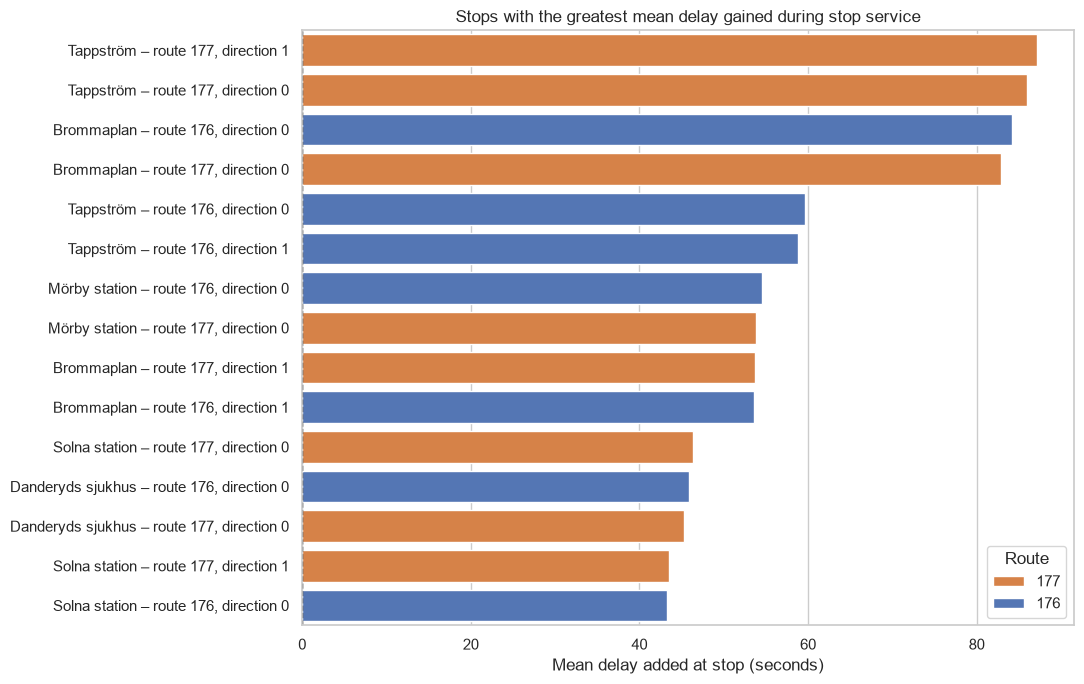

Figure saved: figure_stop_delay_accumulation.png


In [80]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_stops, x="mean_delay_added_sec", y="stop_label",
    hue="LineNumber", dodge=False,
    palette={"176": "#4472C4", "177": "#ED7D31"},
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Mean delay added at stop (seconds)")
plt.ylabel("")
plt.title("Stops with the greatest mean delay gained during stop service")
plt.legend(title="Route")
plt.tight_layout()

hotspot_figure = FIGURES_DIR / "figure_stop_delay_accumulation.png"
plt.savefig(hotspot_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", hotspot_figure.name)


- Spatial aggregation*

In [81]:
spatial_stop_summary = (
    model_data
    .dropna(subset=["current_stop_name", "current_stop_lat", "current_stop_lon"])
    .groupby(["LineNumber", "direction_id", "current_stop_name"])
    .agg(
        stop_lat=("current_stop_lat", "median"),
        stop_lon=("current_stop_lon", "median"),
        typical_sequence=("stop_sequence", "median"),
        observations=("stop_delay_change_sec", "count"),
        mean_delay_added_sec=("stop_delay_change_sec", "mean"),
    )
    .reset_index()
)

print(f"Spatial stop groups: {len(spatial_stop_summary):,}")

bounds = {
    "lat_min": spatial_stop_summary["stop_lat"].min(),
    "lat_max": spatial_stop_summary["stop_lat"].max(),
    "lon_min": spatial_stop_summary["stop_lon"].min(),
    "lon_max": spatial_stop_summary["stop_lon"].max(),
}
print("\nCoordinate bounds:")
for key, value in bounds.items():
    print(f"  {key}: {value:.4f}")

assert spatial_stop_summary["observations"].sum() > 0, "No spatial groups built."


Spatial stop groups: 150

Coordinate bounds:
  lat_min: 59.2705
  lat_max: 59.3925
  lon_min: 17.6865
  lon_max: 18.0469


### Visualisation: spatial delay accumulation, four panels

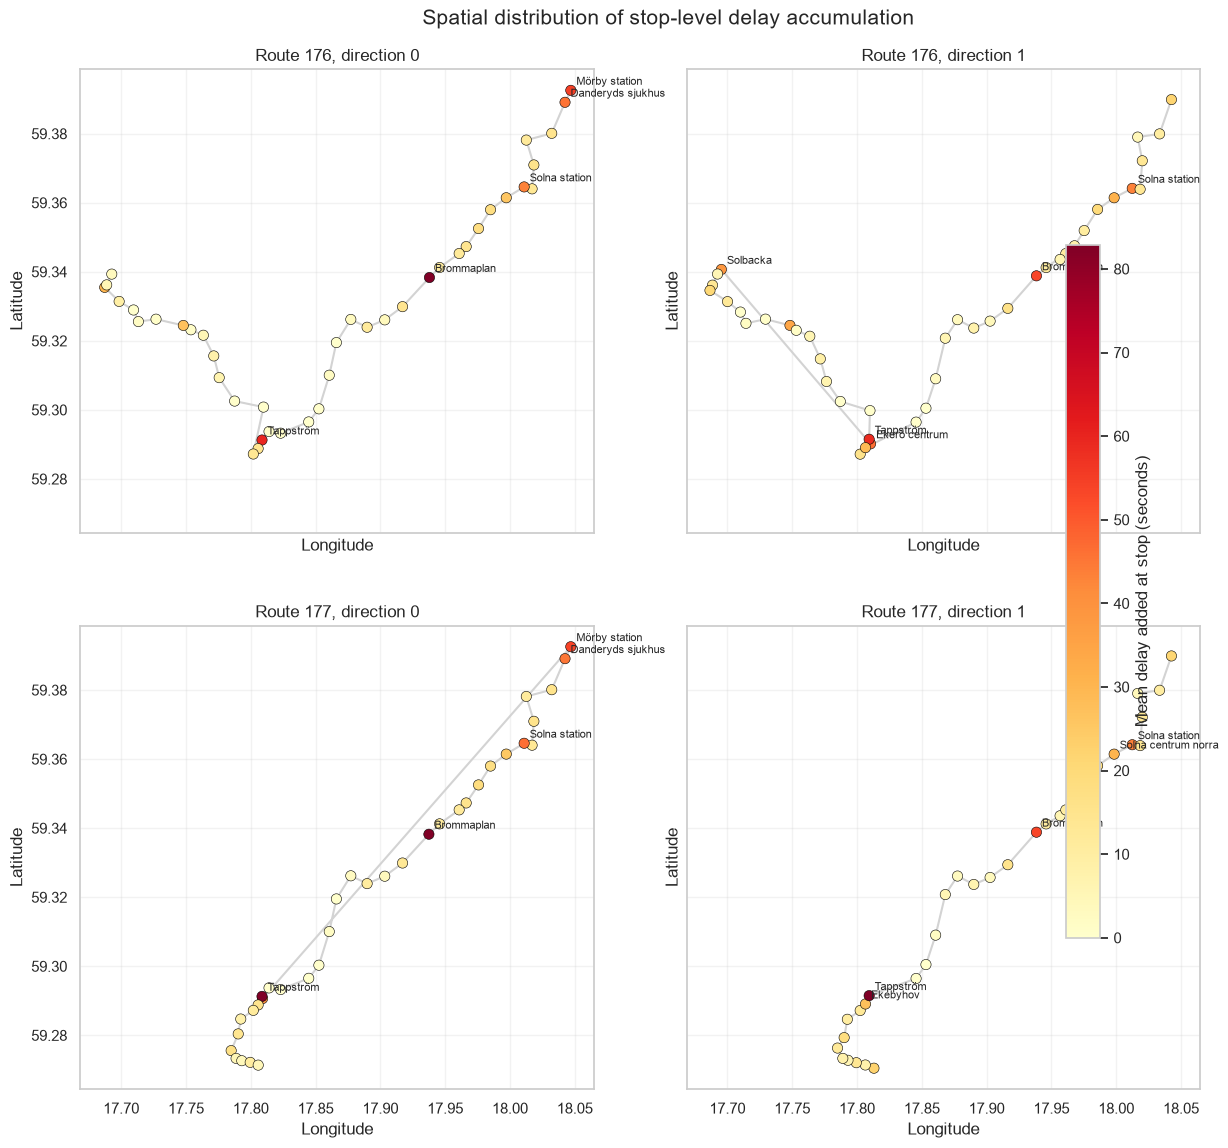

Figure saved: figure_spatial_stop_delay_accumulation.png


In [82]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# A common colour scale makes the four panels comparable. It is capped at the
# 98th percentile so a handful of extreme stops do not flatten the rest.
normalisation = Normalize(
    vmin=0,
    vmax=spatial_stop_summary["mean_delay_added_sec"].quantile(0.98),
)
colour_map = plt.cm.YlOrRd

route_direction_pairs = [("176", 0), ("176", 1), ("177", 0), ("177", 1)]

fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)

for axis, (route, direction) in zip(axes.flat, route_direction_pairs):
    panel = spatial_stop_summary[
        (spatial_stop_summary["LineNumber"] == route)
        & (spatial_stop_summary["direction_id"] == direction)
    ].sort_values("typical_sequence")

    if panel.empty:
        axis.set_title(f"Route {route}, direction {direction} — no data")
        continue

    # The grey line only joins stops in sequence. It is NOT the road alignment.
    axis.plot(panel["stop_lon"], panel["stop_lat"],
              color="lightgray", linewidth=1.5, zorder=1)

    axis.scatter(
        panel["stop_lon"], panel["stop_lat"],
        c=panel["mean_delay_added_sec"], cmap=colour_map,
        norm=normalisation, s=55, edgecolor="black", linewidth=0.4, zorder=2,
    )

    for _, stop in panel.nlargest(5, "mean_delay_added_sec").iterrows():
        axis.annotate(
            stop["current_stop_name"],
            (stop["stop_lon"], stop["stop_lat"]),
            xytext=(4, 4), textcoords="offset points", fontsize=8,
        )

    axis.set_title(f"Route {route}, direction {direction}")
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    axis.grid(alpha=0.25)

colour_bar = ScalarMappable(norm=normalisation, cmap=colour_map)
colour_bar.set_array([])

fig.colorbar(
    colour_bar, ax=axes.ravel().tolist(),
    label="Mean delay added at stop (seconds)", shrink=0.75,
)

fig.suptitle("Spatial distribution of stop-level delay accumulation", fontsize=15, y=0.98)

plt.subplots_adjust(left=0.08, right=0.88, bottom=0.08, top=0.93,
                    wspace=0.18, hspace=0.20)

spatial_figure = FIGURES_DIR / "figure_spatial_stop_delay_accumulation.png"
plt.savefig(spatial_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", spatial_figure.name)


### Stop-level interpretation

Delay accumulation is **spatially concentrated at major interchange stops** rather than distributed uniformly along the routes.

Tappström on route 177 ranks highest in both directions: approximately 87 seconds in direction 1 and 86 seconds in direction 0. Brommaplan in direction 0 follows at roughly 84 seconds on route 176 and 83 seconds on route 177. Mörby station, Solna station and Danderyds sjukhus also appear repeatedly across routes and directions.

These are group averages over the analysed observations. The ranking does **not** show whether every individual vehicle lost time, and it does **not** identify why the additional delay arose. Boarding demand, timetable allowance, signal timing and reporting artefacts cannot be separated by this analysis.

That the same stops recur across both routes points to location-specific conditions rather than a modelling artefact, and it supports including current-stop and next-stop identifiers as model features in Section 10.


# 9. Temporal delay patterns

Arrival delays are examined by scheduled hour and day of the week. Both the **median** and the **95th percentile** are reported. The median represents typical operations, while the 95th percentile illustrates disrupted conditions and the reliability risk experienced by passengers.

This section produces Figures 4 and 5 in the accompanying technical report.


- Delay by scheduled hour

In [83]:
hourly_summary = (
    model_data
    .groupby(["LineNumber", "scheduled_hour"])
    .agg(
        observations=(TARGET_COLUMN, "size"),
        median_delay_min=(TARGET_COLUMN, "median"),
        p95_delay_min=(TARGET_COLUMN, lambda v: v.quantile(0.95)),
    )
    .reset_index()
)

route_colors = {"176": "#4472C4", "177": "#ED7D31"}

print("HOURLY SUMMARY (first rows)")
display(hourly_summary.head(10).round(3))

peak = hourly_summary.groupby("scheduled_hour")["median_delay_min"].mean()
print(f"\nHighest median delay at scheduled hour: {int(peak.idxmax())} "
      f"({peak.max():.2f} minutes)")

p95_peak = hourly_summary.groupby("scheduled_hour")["p95_delay_min"].mean()
print(f"Highest 95th-percentile delay at hour:  {int(p95_peak.idxmax())} "
      f"({p95_peak.max():.2f} minutes)")


HOURLY SUMMARY (first rows)


,LineNumber,scheduled_hour,observations,median_delay_min,p95_delay_min
0,176,0,19000,1.017,6.650
1,176,4,4489,1.717,4.883
2,176,5,26386,1.283,6.046
3,176,6,63100,1.283,6.433
4,176,7,71726,1.250,6.983
5,176,8,76832,1.667,8.200
6,176,9,81519,1.550,7.983
7,176,10,86148,1.883,8.550
8,176,11,89603,1.917,8.883
9,176,12,90987,2.233,10.350



Highest median delay at scheduled hour: 15 (2.48 minutes)
Highest 95th-percentile delay at hour:  17 (19.51 minutes)


### Visualisation: delay by scheduled hour

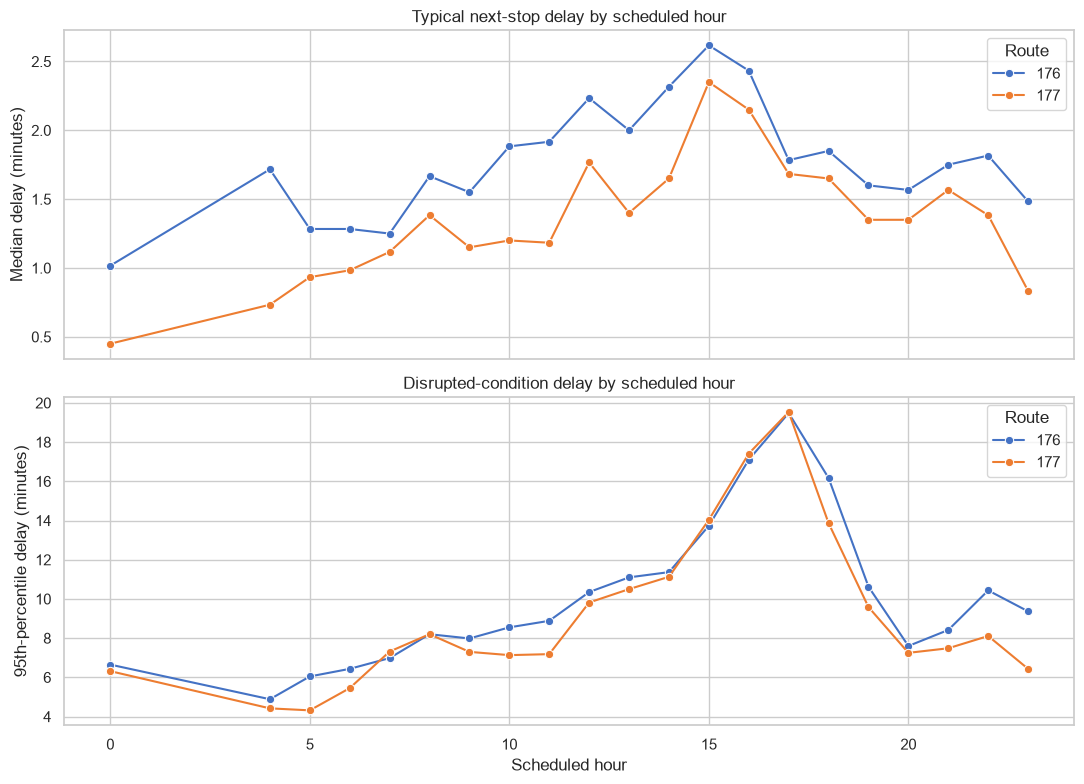

Figure saved: figure_hourly_delay_patterns.png


In [84]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.lineplot(
    data=hourly_summary, x="scheduled_hour", y="median_delay_min",
    hue="LineNumber", palette=route_colors, marker="o", ax=axes[0],
)
axes[0].set_title("Typical next-stop delay by scheduled hour")
axes[0].set_ylabel("Median delay (minutes)")
axes[0].set_xlabel("")
axes[0].legend(title="Route")

sns.lineplot(
    data=hourly_summary, x="scheduled_hour", y="p95_delay_min",
    hue="LineNumber", palette=route_colors, marker="o", ax=axes[1],
)
axes[1].set_title("Disrupted-condition delay by scheduled hour")
axes[1].set_ylabel("95th-percentile delay (minutes)")
axes[1].set_xlabel("Scheduled hour")
axes[1].legend(title="Route")

plt.tight_layout()

hourly_figure = FIGURES_DIR / "figure_hourly_delay_patterns.png"
plt.savefig(hourly_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", hourly_figure.name)


- Delay by weekday

In [85]:
weekday_summary = (
    model_data
    .groupby(["LineNumber", "weekday"])
    .agg(
        observations=(TARGET_COLUMN, "size"),
        median_delay_min=(TARGET_COLUMN, "median"),
        p95_delay_min=(TARGET_COLUMN, lambda v: v.quantile(0.95)),
    )
    .reset_index()
)

weekday_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
weekday_order = list(weekday_names.values())

weekday_summary["weekday_name"] = weekday_summary["weekday"].map(weekday_names)

print("WEEKDAY SUMMARY")
display(weekday_summary.round(3))

worst = weekday_summary.groupby("weekday_name")["median_delay_min"].mean()
print(f"\nHighest median delay on: {worst.idxmax()} ({worst.max():.2f} minutes)")


WEEKDAY SUMMARY


,LineNumber,weekday,observations,median_delay_min,p95_delay_min,weekday_name
0,176,0,222244,1.500,8.533,Mon
1,176,1,222065,1.933,11.700,Tue
2,176,2,218212,1.900,11.100,Wed
3,176,3,214535,1.850,10.667,Thu
4,176,4,217075,1.600,9.250,Fri
5,176,5,177512,2.383,12.983,Sat
6,176,6,177039,1.633,9.917,Sun
7,177,0,182091,1.067,7.600,Mon
8,177,1,182122,1.383,10.900,Tue
9,177,2,179019,1.333,9.917,Wed



Highest median delay on: Sat (2.34 minutes)


### Visualisation: delay by weekday

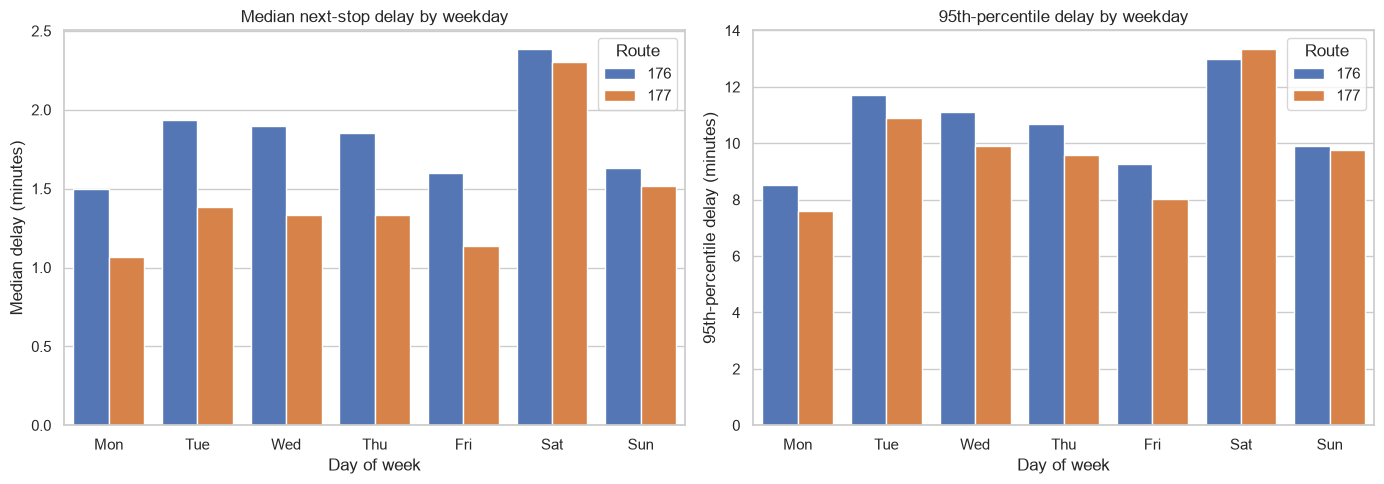

Figure saved: figure_weekday_delay_patterns.png


In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=weekday_summary, x="weekday_name", y="median_delay_min",
    hue="LineNumber", order=weekday_order, palette=route_colors, ax=axes[0],
)
axes[0].set_title("Median next-stop delay by weekday")
axes[0].set_xlabel("Day of week")
axes[0].set_ylabel("Median delay (minutes)")
axes[0].legend(title="Route")

sns.barplot(
    data=weekday_summary, x="weekday_name", y="p95_delay_min",
    hue="LineNumber", order=weekday_order, palette=route_colors, ax=axes[1],
)
axes[1].set_title("95th-percentile delay by weekday")
axes[1].set_xlabel("Day of week")
axes[1].set_ylabel("95th-percentile delay (minutes)")
axes[1].legend(title="Route")

plt.tight_layout()

weekday_figure = FIGURES_DIR / "figure_weekday_delay_patterns.png"
plt.savefig(weekday_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", weekday_figure.name)


### Temporal interpretation

Delays vary systematically across the day. Typical next-stop delay rises through the morning, dips slightly around midday, and peaks in the mid-afternoon. The upper tail climbs far more steeply than the median, reaching roughly twenty minutes in the late afternoon. The two curves therefore answer different operational questions: the median describes what a passenger should usually expect, while the 95th percentile describes the reliability risk that a small but consequential share of journeys carries.

Route 176 runs consistently later than route 177 across the day, which is consistent with a longer or more congested alignment rather than with a difference in schedule adherence alone.

Weekday variation is modest in the median but clearly larger in the upper tail, with the worst conditions on Saturday. This supports hypothesis **H2** in part: delays are larger during peak periods, but the effect is concentrated in the upper tail rather than in typical performance.


# 10. Feature engineering and chronological data split

The model predicts arrival delay at the next stop **immediately after departure from the current stop**. Features therefore include only information available at that moment: current arrival and departure delay, dwell time, segment distance, stop sequence, route, direction, stop identifiers and temporal variables.

Cyclical transformations are used for hour, weekday and month because these variables repeat over time. A **chronological split** is used instead of a random split, to avoid training the models on future observations.

| Partition | Dates | Role |
|---|---|---|
| Training | 1 Jan – 30 Sep 2024 | Fit preprocessing and models |
| Validation | 1 – 31 Oct 2024 | Hyperparameters and early stopping |
| Test | 1 Nov – 31 Dec 2024 | Recorded final evaluation |

This section produces the modelling table used by every model below.


- Build the modelling features

In [87]:
ml_data = model_data.copy()

# --- Current operating conditions, in practical units ------------------------
ml_data["current_arrival_delay_min"] = ml_data["observed_arrival_delay"] / 60
ml_data["current_departure_delay_min"] = ml_data["observed_departure_delay"] / 60
ml_data["observed_dwell_min"] = ml_data["observed_dwell_sec"] / 60
ml_data["excess_dwell_min"] = ml_data["excess_dwell_sec"] / 60

# NOTE ON A MISNAMED FIELD
# next_segment_distance_km is derived from the NEXT stop's cumulative
# dist_traveled divided by 1000. It therefore measures progress along the route,
# not the length of the link from the current stop to the next one. The name is
# kept for continuity with the recorded results, but the field should be renamed
# (or replaced by the difference of successive cumulative distances) before any
# physical interpretation is placed on it.
ml_data["next_segment_distance_km"] = ml_data["next_segment_distance_m"] / 1000

# --- Historical state available at departure ---------------------------------
# A BACKWARD shift within the trip. The target uses a FORWARD shift, so the two
# move in opposite directions and the inputs never contain the label.
history_group = ["date", "route_id", "trip_id", "direction_id"]

ml_data = ml_data.sort_values(
    history_group + ["stop_sequence"], kind="mergesort"
).reset_index(drop=True)

previous_delay = (
    ml_data.groupby(history_group, sort=False)["observed_arrival_delay"].shift(1) / 60
)

# Where no earlier stop exists, fall back to the current arrival delay and set
# the flag to 0. The fallback is recorded rather than hidden: silently imputing
# a plausible-looking previous delay would tell the model a vehicle was stable
# at a stop where its history is simply unknown.
ml_data["history_available"] = previous_delay.notna().astype("int8")
ml_data["previous_arrival_delay_min"] = previous_delay.fillna(
    ml_data["current_arrival_delay_min"]
)
ml_data["delay_trend_min"] = (
    ml_data["current_arrival_delay_min"] - ml_data["previous_arrival_delay_min"]
)

# --- Cyclical time variables -------------------------------------------------
# Hour 23 and hour 0 are adjacent, so a raw numeric encoding would place them
# 23 units apart. The sine/cosine pair preserves the wrap-around.
ml_data["hour_sin"] = np.sin(2 * np.pi * ml_data["scheduled_hour"] / 24)
ml_data["hour_cos"] = np.cos(2 * np.pi * ml_data["scheduled_hour"] / 24)
ml_data["weekday_sin"] = np.sin(2 * np.pi * ml_data["weekday"] / 7)
ml_data["weekday_cos"] = np.cos(2 * np.pi * ml_data["weekday"] / 7)
ml_data["month_sin"] = np.sin(2 * np.pi * ml_data["month"] / 12)
ml_data["month_cos"] = np.cos(2 * np.pi * ml_data["month"] / 12)

for column in CATEGORICAL_FEATURES:
    ml_data[column] = ml_data[column].astype("string")

selected_columns = (
    ["date"] + CATEGORICAL_FEATURES + BASE_NUMERIC_FEATURES
    + HISTORY_FEATURES + [TARGET_COLUMN]
)

ml_table = ml_data[selected_columns].copy()

# An infinity in a numeric feature would propagate through scaling and poison
# the whole training matrix, so it is converted to NaN before the dropna.
ml_table = ml_table.replace([np.inf, -np.inf], np.nan)

rows_before = len(ml_table)
ml_table = ml_table.dropna(
    subset=BASE_NUMERIC_FEATURES + [TARGET_COLUMN]
).reset_index(drop=True)
rows_removed = rows_before - len(ml_table)

print("FEATURE-ENGINEERED DATASET")
print(f"Total observations:            {len(ml_table):,}")
print(f"Rows removed for missing features: {rows_removed:,}")
print(f"Features per row:              {len(selected_columns) - 2}")


FEATURE-ENGINEERED DATASET
Total observations:            2,643,576
Rows removed for missing features: 0
Features per row:              20


- 10.1b) Correlation matrix

In [107]:
from numpy import triu

# Numeric model features plus the target. The target is included for descriptive
# context only: it is NOT an input feature, and it is excluded from the model in
# every section below. Showing it here makes the persistence relationship
# visible, which is what motivates the baseline comparison in Section 11.
correlation_columns = BASE_NUMERIC_FEATURES + HISTORY_FEATURES + [TARGET_COLUMN]

correlation_table = ml_table[correlation_columns].apply(
    pd.to_numeric, errors="coerce"
)

pearson_r = correlation_table.corr(method="pearson")

print(f"Correlation matrix: {pearson_r.shape[0]} variables")
print(f"Rows used: {len(correlation_table):,}")

# The pairs that matter for interpretation. Reporting these explicitly is more
# useful than reading them off a heatmap, and it makes the numbers quotable.
def report_pair(label, first, second):
    value = pearson_r.loc[first, second]
    print(f"  {label:<42} r = {value:+.3f}")

print("\nASSOCIATION WITH THE NEXT-STOP DELAY TARGET")
report_pair("Current departure delay", "current_departure_delay_min", TARGET_COLUMN)
report_pair("Current arrival delay", "current_arrival_delay_min", TARGET_COLUMN)
report_pair("Previous arrival delay", "previous_arrival_delay_min", TARGET_COLUMN)
report_pair("Delay trend", "delay_trend_min", TARGET_COLUMN)
report_pair("Observed dwell", "observed_dwell_min", TARGET_COLUMN)
report_pair("Excess dwell", "excess_dwell_min", TARGET_COLUMN)

print("\nASSOCIATION AMONG THE DELAY FIELDS")
report_pair("Current departure vs current arrival", "current_departure_delay_min", "current_arrival_delay_min")
report_pair("Observed dwell vs excess dwell", "observed_dwell_min", "excess_dwell_min")
report_pair("Previous delay vs delay trend", "previous_arrival_delay_min", "delay_trend_min")

# Near-duplicate predictors are worth naming. Ridge regularisation absorbs the
# resulting instability, but a linear interpretation of coefficients does not
# survive it — which is exactly why grouped permutation importance is used in
# Section 19 instead of reading model coefficients.
print("\nNON-TARGET PAIRS ABOVE |r| = 0.9 (redundancy check)")
upper = pearson_r.where(triu(np.ones(pearson_r.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ["variable_1", "variable_2", "r"]

# Exclude pairs involving the target: those are associations, not redundancy.
redundant = pairs[
    (pairs["variable_1"] != TARGET_COLUMN)
    & (pairs["variable_2"] != TARGET_COLUMN)
    & (pairs["r"].abs() > 0.9)
].sort_values("r", key=lambda s: s.abs(), ascending=False)

if len(redundant):
    display(redundant.round(3))
    print(
        "\nThese pairs carry largely the same information. Ridge regularisation "
        "handles the resulting collinearity, but it means individual "
        "coefficients should not be interpreted as independent effects."
    )
else:
    print("  None above the threshold.")


Correlation matrix: 17 variables
Rows used: 2,643,576

ASSOCIATION WITH THE NEXT-STOP DELAY TARGET
  Current departure delay                    r = +0.974
  Current arrival delay                      r = +0.968
  Previous arrival delay                     r = +0.929
  Delay trend                                r = +0.223
  Observed dwell                             r = +0.006
  Excess dwell                               r = +0.011

ASSOCIATION AMONG THE DELAY FIELDS
  Current departure vs current arrival       r = +0.995
  Observed dwell vs excess dwell             r = +0.985
  Previous delay vs delay trend              r = -0.050

NON-TARGET PAIRS ABOVE |r| = 0.9 (redundancy check)


,variable_1,variable_2,r
1,current_arrival_delay_min,current_departure_delay_min,0.995
73,next_segment_distance_km,stop_sequence,0.987
37,observed_dwell_min,excess_dwell_min,0.985
13,current_arrival_delay_min,previous_arrival_delay_min,0.966
30,current_departure_delay_min,previous_arrival_delay_min,0.962



These pairs carry largely the same information. Ridge regularisation handles the resulting collinearity, but it means individual coefficients should not be interpreted as independent effects.


- 10.1c) Visualisation: correlation matrix

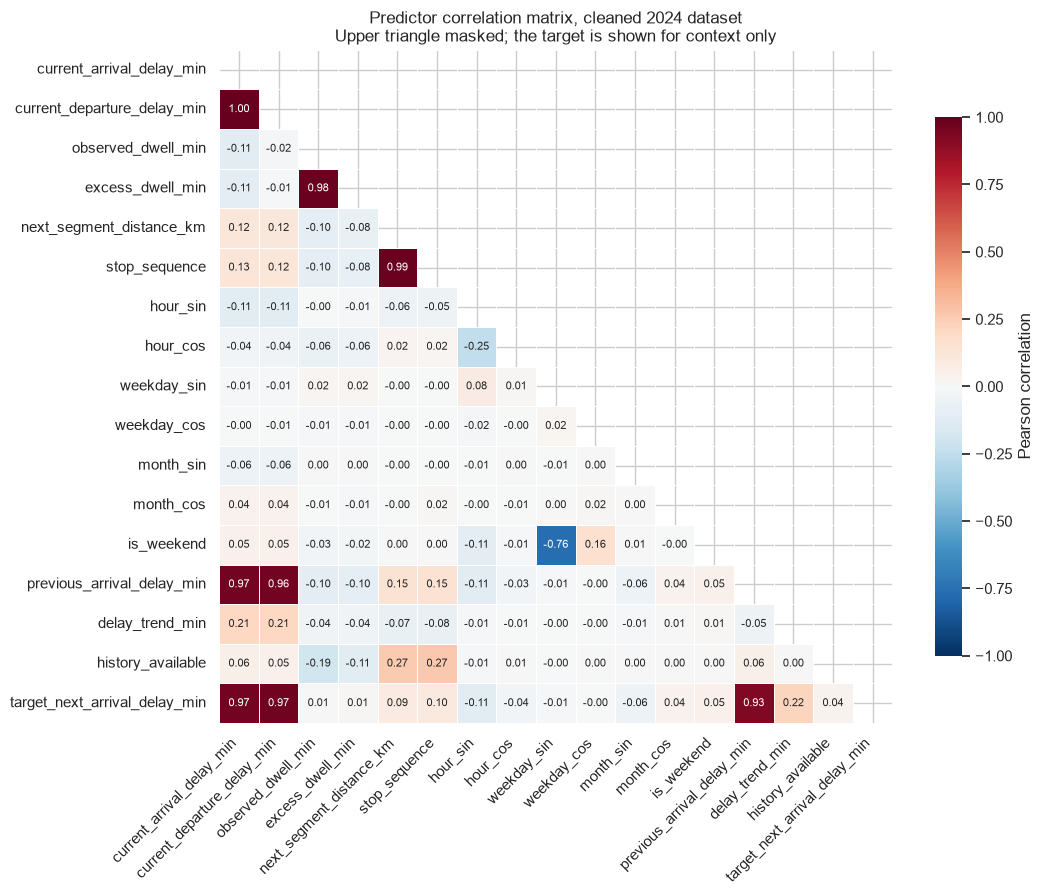

Figure saved: figure_predictor_correlation_matrix.png


In [108]:
mask = np.triu(np.ones_like(pearson_r, dtype=bool))

plt.figure(figsize=(11, 9))

sns.heatmap(
    pearson_r,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
    annot_kws={"size": 8},
)

plt.title(
    "Predictor correlation matrix, cleaned 2024 dataset\n"
    "Upper triangle masked; the target is shown for context only",
    fontsize=12,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

correlation_figure = FIGURES_DIR / "figure_predictor_correlation_matrix.png"
plt.savefig(correlation_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", correlation_figure.name)


In [109]:
correlation_figure = FIGURES_DIR / "figure_predictor_correlation_matrix.png"
plt.savefig(correlation_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", correlation_figure.name)


<Figure size 640x480 with 0 Axes>

Figure saved: figure_predictor_correlation_matrix.png


- 10.2) Chronological split

In [88]:
ml_table["date"] = pd.to_datetime(ml_table["date"])

train_data = ml_table[ml_table["date"] < TRAIN_END].copy()
validation_data = ml_table[
    (ml_table["date"] >= TRAIN_END) & (ml_table["date"] < VALIDATION_END)
].copy()
test_data = ml_table[ml_table["date"] >= TEST_START].copy()

counts = (len(train_data), len(validation_data), len(test_data))
total = len(ml_table)

print("CHRONOLOGICAL SPLIT")
print(f"Training,   Jan–Sep : {counts[0]:>9,} ({100 * counts[0] / total:.1f}%)")
print(f"Validation, Oct     : {counts[1]:>9,} ({100 * counts[1] / total:.1f}%)")
print(f"Test,       Nov–Dec : {counts[2]:>9,} ({100 * counts[2] / total:.1f}%)")

print("\nDATE RANGES")
print("Training  :", train_data["date"].min().date(), "to", train_data["date"].max().date())
print("Validation:", validation_data["date"].min().date(), "to", validation_data["date"].max().date())
print("Test      :", test_data["date"].min().date(), "to", test_data["date"].max().date())

# Non-overlapping ranges are what make the split a genuine forward-in-time
# evaluation instead of a partially random one.
assert train_data["date"].max() < validation_data["date"].min(), "Train/validation overlap."
assert validation_data["date"].max() < test_data["date"].min(), "Validation/test overlap."

print("\nNo partition overlap. The split is chronological.")


CHRONOLOGICAL SPLIT
Training,   Jan–Sep : 1,966,871 (74.4%)
Validation, Oct     :   228,139 (8.6%)
Test,       Nov–Dec :   448,566 (17.0%)

DATE RANGES
Training  : 2024-01-01 to 2024-09-30
Validation: 2024-10-01 to 2024-10-31
Test      : 2024-11-01 to 2024-12-31

No partition overlap. The split is chronological.


- Save the modelling table

In [90]:
ml_table_file = PROCESSED_DIR / "ml_table_176_177_2024.parquet"
ml_table.to_parquet(ml_table_file, index=False)

print("Saved:", ml_table_file.name)
print("Size :", round(ml_table_file.stat().st_size / 1024**2, 1), "MB")

# Recorded reference counts. A difference is not automatically an error — we
# have 366 service dates where the recorded run had 365 — but it is worth
# seeing before the model results are compared against the report.
recorded = {"train": 1_966_871, "validation": 228_139, "test": 448_566}
actual = {"train": counts[0], "validation": counts[1], "test": counts[2]}

print("\nCOMPARISON WITH THE RECORDED RUN")
for name in recorded:
    difference = actual[name] - recorded[name]
    print(f"  {name:<11} actual {actual[name]:>9,}  "
          f"recorded {recorded[name]:>9,}  difference {difference:+,}")


Saved: ml_table_176_177_2024.parquet
Size : 27.1 MB

COMPARISON WITH THE RECORDED RUN
  train       actual 1,966,871  recorded 1,966,871  difference +0
  validation  actual   228,139  recorded   228,139  difference +0
  test        actual   448,566  recorded   448,566  difference +0


- Release intermediate frames

In [91]:
del ml_data
gc.collect()

print("Released ml_data.")
print("In scope: ml_table, train_data, validation_data, test_data, model_data")


Released ml_data.
In scope: ml_table, train_data, validation_data, test_data, model_data


### Interpretation

The feature table contains the current-delay block, the three historical fields and the encoded calendar context, with categorical identifiers stored as strings for encoding in the next section.

Two design decisions are worth stating explicitly.

**The historical fields use a backward shift while the target uses a forward shift.** The two move in opposite directions within each trip, so the model's inputs can never contain its label. Where no earlier stop exists, the previous delay falls back to the current arrival delay and the availability flag records that the value is imputed rather than observed.

**The split is chronological by service date.** A random split would place trips from the same day in different partitions and would train the models on observations from the future relative to their validation and test data. Because the date ranges do not overlap, a trip belongs to exactly one partition and the test figure describes forward-in-time performance.


# 11. Baseline models

Two operational baselines are evaluated before any machine-learning model. The **schedule baseline** predicts zero delay; the **persistence baseline** assumes that the current departure delay continues unchanged to the next stop.

> **Persistence is the bar that matters.** Delay carries over strongly between nearby stops, so a model that cannot beat persistence has added nothing. Because persistence is simple, transparent and inexpensive to deploy, any additional complexity must be justified by a meaningful improvement.

MAPE is not used, because delay values can be zero or negative.

- Evaluate both baselines

In [92]:
baseline_results = []

for split_name, split_data in [
    ("Validation", validation_data),
    ("Test", test_data),
]:
    y_true = split_data[TARGET_COLUMN].to_numpy()

    # Baseline 1: assume every bus is on time.
    baseline_results.append({
        "split": split_name,
        "model": "Schedule baseline",
        **regression_metrics(y_true, np.zeros(len(split_data))),
    })

    # Baseline 2: carry the current departure delay forward unchanged.
    baseline_results.append({
        "split": split_name,
        "model": "Persistence baseline",
        **regression_metrics(
            y_true,
            split_data["current_departure_delay_min"].to_numpy(),
        ),
    })

baseline_results = pd.DataFrame(baseline_results)

print("BASELINE RESULTS")
display(baseline_results.round(4))

persistence_test_mae = baseline_results.loc[
    (baseline_results["model"] == "Persistence baseline")
    & (baseline_results["split"] == "Test"),
    "MAE_min",
].iloc[0]

schedule_test_mae = baseline_results.loc[
    (baseline_results["model"] == "Schedule baseline")
    & (baseline_results["split"] == "Test"),
    "MAE_min",
].iloc[0]

print(f"\nThe bar to beat: persistence test MAE = {persistence_test_mae:.4f} minutes")
print(f"Schedule baseline test MAE             = {schedule_test_mae:.4f} minutes")
print(
    f"\nPersistence is {schedule_test_mae / persistence_test_mae:.1f} times more "
    "accurate than assuming buses run to schedule."
)


BASELINE RESULTS


,split,model,MAE_min,RMSE_min,R2
0,Validation,Schedule baseline,4.6292,9.0386,-0.2528
1,Validation,Persistence baseline,0.6656,1.7869,0.9510
2,Test,Schedule baseline,3.9736,8.4162,-0.1814
3,Test,Persistence baseline,0.6303,1.7707,0.9477



The bar to beat: persistence test MAE = 0.6303 minutes
Schedule baseline test MAE             = 3.9736 minutes

Persistence is 6.3 times more accurate than assuming buses run to schedule.


- baseline comparison

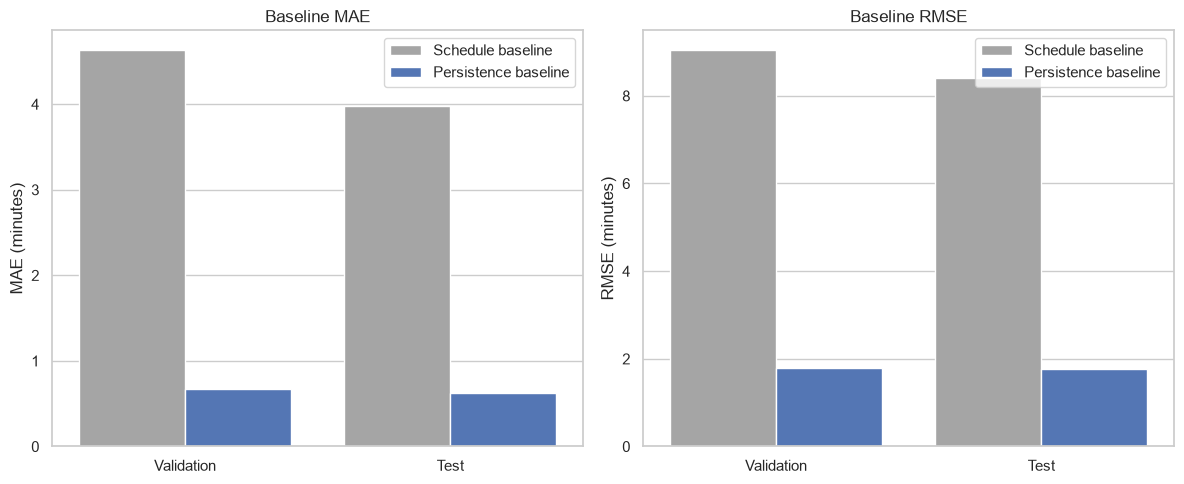

Figure saved: figure_baseline_model_comparison.png


In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

palette = ["#A5A5A5", "#4472C4"]

sns.barplot(
    data=baseline_results, x="split", y="MAE_min", hue="model",
    ax=axes[0], palette=palette,
)
axes[0].set_title("Baseline MAE")
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE (minutes)")
axes[0].legend(title="")

sns.barplot(
    data=baseline_results, x="split", y="RMSE_min", hue="model",
    ax=axes[1], palette=palette,
)
axes[1].set_title("Baseline RMSE")
axes[1].set_xlabel("")
axes[1].set_ylabel("RMSE (minutes)")
axes[1].legend(title="")

plt.tight_layout()

baseline_figure = FIGURES_DIR / "figure_baseline_model_comparison.png"
plt.savefig(baseline_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", baseline_figure.name)


### Baseline interpretation

The persistence baseline substantially outperforms the schedule baseline on both metrics and in both periods. On the recorded November–December test period it achieves an MAE of approximately 0.63 minutes, about 38 seconds, with a coefficient of determination near 0.95.

This confirms strong short-term delay propagation between consecutive stops, and it establishes a demanding benchmark. The high \(R^2\) is itself informative: most of the variance in next-stop delay is already explained by a single current-stop field, so the modelling problem is one of refining a persistent signal rather than discovering an independent mechanism.

An important implication follows for the rest of this report. Any model that does not clearly beat persistence is not useful, and a model that beats it by a small margin should be described as a modest improvement rather than as a demonstration of superior modelling.


# 12. Model 1 — Regularised linear regression

Ridge regression is the first machine-learning model. Numerical features are standardised and categorical variables are one-hot encoded. Regularisation reduces instability caused by correlated delay and dwell-time features.

Three regularisation strengths are compared using the **October validation period**. The final November–December test set is evaluated only after the hyperparameter has been selected.


- Encode the design matrix and tune the regularisation strength

In [99]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge

feature_columns = BASE_NUMERIC_FEATURES + HISTORY_FEATURES + CATEGORICAL_FEATURES
numeric_features = BASE_NUMERIC_FEATURES + HISTORY_FEATURES


def prepare_categoricals(frame):
    """Return a copy with categorical columns as plain string objects.

    Two problems are fixed here.

    1. pd.NA versus np.nan. The columns were created with astype("string"),
       which is pandas' nullable string type, so missing identifiers are stored
       as pd.NA. OneHotEncoder can handle np.nan but not pd.NA, and fails with
       "boolean value of NA is ambiguous".

    2. Integer-versus-string categories. A category stored as an integer in one
       frame and a string in another (176 vs "176") does NOT raise with
       handle_unknown="ignore" — it silently encodes every row as unknown, and
       the model trains on a block of structural zeros. Casting both sides
       through str to object makes the dtypes match by construction.
    """
    prepared = frame.copy()
    for column in CATEGORICAL_FEATURES:
        prepared[column] = (
            prepared[column]
            .astype("object")
            .where(prepared[column].notna(), "<MISSING>")
            .astype(str)
            .astype(object)
        )
    return prepared


X_train = prepare_categoricals(train_data[feature_columns])
y_train = train_data[TARGET_COLUMN].astype("float32")

X_validation = prepare_categoricals(validation_data[feature_columns])
y_validation = validation_data[TARGET_COLUMN].astype("float32")

X_test = prepare_categoricals(test_data[feature_columns])
y_test = test_data[TARGET_COLUMN].astype("float32")

# Confirm no nullable missing values remain in the categorical columns.
for name, frame in [("train", X_train), ("validation", X_validation), ("test", X_test)]:
    residual = int(frame[CATEGORICAL_FEATURES].isna().sum().sum())
    print(f"{name:<11} categorical NA count: {residual}")
    assert residual == 0, f"{name} still contains missing categorical values."

print("\nUnique categories per column (training):")
for column in CATEGORICAL_FEATURES:
    print(f"  {column:<18} {X_train[column].nunique()}")

# StandardScaler(with_mean=False) is deliberate: the one-hot block is sparse,
# and centring it would subtract a mean from every structural zero and turn a
# sparse matrix dense. Scaling the variance is still required by Ridge, so the
# scaler is used without centring.
linear_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(with_mean=False), numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore", dtype=np.float32),
         CATEGORICAL_FEATURES),
    ],
    sparse_threshold=1.0,
)

# The preprocessor is fitted ONCE, on training rows only, and reused for every
# alpha and for the test set. Refitting per candidate would rescale the data
# differently for each and make the comparison meaningless.
print("\nTransforming training data...")
X_train_transformed = linear_preprocessor.fit_transform(X_train).astype("float32")

print("Transforming validation data...")
X_validation_transformed = linear_preprocessor.transform(X_validation).astype("float32")

print("Transforming test data...")
X_test_transformed = linear_preprocessor.transform(X_test).astype("float32")

print("\nEncoded widths:")
print("  Training:  ", X_train_transformed.shape)
print("  Validation:", X_validation_transformed.shape)
print("  Test:      ", X_test_transformed.shape)

# ---------------------------------------------------------------------------
# Compare regularisation strengths on October validation
# ---------------------------------------------------------------------------
ridge_rows = []
ridge_candidates = {}

for alpha in [0.1, 1.0, 10.0]:
    candidate = Ridge(alpha=alpha, solver="lsqr", max_iter=1000, tol=1e-4)
    candidate.fit(X_train_transformed, y_train)

    prediction = candidate.predict(X_validation_transformed)
    ridge_candidates[alpha] = candidate

    ridge_rows.append({
        "alpha": alpha,
        "split": "Validation",
        **regression_metrics(y_validation, prediction),
    })
    print(f"alpha = {alpha:<6g}  validation MAE = {ridge_rows[-1]['MAE_min']:.4f}")

ridge_validation = pd.DataFrame(ridge_rows)

# best_alpha is the selection the next cell depends on. It is chosen on October
# validation only — the test period is not consulted here.
best_alpha = float(ridge_validation.sort_values("MAE_min").iloc[0]["alpha"])

print("\nRIDGE VALIDATION SWEEP")
display(ridge_validation.round(4))
print(f"\nSelected alpha = {best_alpha:g} on October validation MAE")
print("Fitted candidates available for:", sorted(ridge_candidates.keys()))


train       categorical NA count: 0
validation  categorical NA count: 0
test        categorical NA count: 0

Unique categories per column (training):
  LineNumber         2
  direction_id       2
  current_stop_key   101
  next_stop_key      97

Transforming training data...
Transforming validation data...
Transforming test data...

Encoded widths:
  Training:   (1966871, 218)
  Validation: (228139, 218)
  Test:       (448566, 218)
alpha = 0.1     validation MAE = 0.3888
alpha = 1       validation MAE = 0.3796
alpha = 10      validation MAE = 0.3772

RIDGE VALIDATION SWEEP


,alpha,split,MAE_min,RMSE_min,R2
0,0.1,Validation,0.3888,1.6463,0.9584
1,1.0,Validation,0.3796,1.6185,0.9598
2,10.0,Validation,0.3772,1.6053,0.9605



Selected alpha = 10 on October validation MAE
Fitted candidates available for: [0.1, 1.0, 10.0]


- Evaluate the selected model on test

In [100]:
# Guard: this cell depends on cell 12.1 having run in the current kernel.
if "ridge_candidates" not in globals() or "best_alpha" not in globals():
    raise RuntimeError("Re-run cell 12.1 first — ridge_candidates is not defined.")

assert best_alpha in ridge_candidates, (
    f"best_alpha={best_alpha} is not among the fitted candidates "
    f"{sorted(ridge_candidates.keys())}."
)

ridge_model = ridge_candidates[best_alpha]

ridge_validation_prediction = ridge_model.predict(X_validation_transformed)
ridge_test_prediction = ridge_model.predict(X_test_transformed)

ridge_results = pd.DataFrame([
    result_row(f"Ridge (alpha={best_alpha:g})", "Validation",
               y_validation, ridge_validation_prediction),
    result_row(f"Ridge (alpha={best_alpha:g})", "Test",
               y_test, ridge_test_prediction),
])

print(f"RIDGE REGRESSION — alpha = {best_alpha:g}")
display(ridge_results.round(4))

ridge_test_mae = ridge_results.loc[
    ridge_results["Split"] == "Test", "MAE_min"
].iloc[0]

# Persistence is recomputed from the test frame itself, so this cell does not
# depend on Section 11 having run in the current kernel session.
persistence_prediction = test_data["current_departure_delay_min"].to_numpy()
persistence_mae = regression_metrics(y_test.to_numpy(), persistence_prediction)["MAE_min"]

improvement = 100 * (persistence_mae - ridge_test_mae) / persistence_mae

print(f"\nRidge test MAE:       {ridge_test_mae:.4f} minutes")
print(f"Persistence baseline: {persistence_mae:.4f} minutes")
print(f"Improvement over persistence: {improvement:.1f}%")
print(f"\nRecorded run for comparison: Ridge 0.3844, persistence 0.6300")

# A fitted model that does not beat persistence has added nothing. Fail loudly
# rather than reporting a number that reads like progress.
assert ridge_test_mae < persistence_mae, (
    f"Ridge ({ridge_test_mae:.4f}) did not beat persistence "
    f"({persistence_mae:.4f}). Investigate before continuing."
)

joblib.dump(linear_preprocessor, MODELS_DIR / "next_stop_preprocessor.joblib")
joblib.dump(ridge_model, MODELS_DIR / "ridge_next_stop_delay.joblib")

print("\nPreprocessor and Ridge model saved to:", MODELS_DIR.name)


RIDGE REGRESSION — alpha = 10


,Model,Split,MAE_min,RMSE_min,R2
0,Ridge (alpha=10),Validation,0.3772,1.6053,0.9605
1,Ridge (alpha=10),Test,0.3836,1.6100,0.9568



Ridge test MAE:       0.3836 minutes
Persistence baseline: 0.6303 minutes
Improvement over persistence: 39.1%

Recorded run for comparison: Ridge 0.3844, persistence 0.6300

Preprocessor and Ridge model saved to: models


### Ridge interpretation

Ridge regression clears the persistence baseline by a clear margin, reducing test MAE from roughly 0.63 minutes to about 0.38 minutes. It therefore demonstrates genuine predictive value beyond simply carrying the current delay forward.

The gap between MAE and RMSE is the detail worth noting. Ridge is usually close and occasionally far off, which is the same pattern that appears in every model below. A low MAE does not mean every prediction is close: the target contains roughly 18,900 delays above thirty minutes, and those rare cases inflate RMSE without moving the median error much.

Ridge is also worth keeping in view as a deployment candidate. It trains in seconds, its coefficients are inspectable, and its input requires no sequence construction.


# 13. Model 2 — XGBoost regression

Ridge regression assumes that the relationship between the explanatory variables and next-stop delay is approximately linear. Delay propagation may instead depend on non-linear interactions between current delay, dwell time, stop location, time of day, route and direction.

An XGBoost regression model is therefore developed as a nonlinear, tree-based benchmark. A subset of the training period is used for efficient hyperparameter comparison, while the complete October validation set is kept for model selection.

> **On the role of this model.** XGBoost is included to test whether nonlinear splits and interactions improve accuracy — **not** as a preferred deployment candidate. As the results show, it does not outperform Ridge on this feature set. That outcome is reported rather than tuned away, because a model that loses is still informative when it tests a distinct hypothesis.


- 13.1) Hyperparameter comparison

In [102]:
import xgboost as xgb

# XGBoost consumes the same encoded sparse matrix as Ridge. The encoder was
# fitted on training rows only in cell 12.1, so no leakage is introduced here.
X_train_sparse = X_train_transformed
X_validation_sparse = X_validation_transformed
X_test_sparse = X_test_transformed

rng = np.random.default_rng(RANDOM_SEED)
sample_size = min(600_000, X_train_sparse.shape[0])
sample_index = rng.choice(X_train_sparse.shape[0], size=sample_size, replace=False)

X_sample = X_train_sparse[sample_index]
y_sample = np.asarray(y_train)[sample_index]

print(f"Hyperparameter sample: {X_sample.shape[0]:,} rows")

param_grid = [
    {"max_depth": 4, "learning_rate": 0.08},
    {"max_depth": 6, "learning_rate": 0.05},
    {"max_depth": 8, "learning_rate": 0.04},
]

xgb_rows = []

for params in param_grid:
    candidate = xgb.XGBRegressor(
        n_estimators=300,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        eval_metric="mae",
        early_stopping_rounds=30,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        **params,
    )

    start = time.time()
    candidate.fit(
        X_sample, y_sample,
        eval_set=[(X_validation_sparse, y_validation)],
        verbose=False,
    )
    minutes = (time.time() - start) / 60

    prediction = candidate.predict(X_validation_sparse)

    xgb_rows.append({
        "max_depth": params["max_depth"],
        "learning_rate": params["learning_rate"],
        "best_iteration": int(candidate.best_iteration),
        "training_minutes": round(minutes, 2),
        **regression_metrics(y_validation, prediction),
    })

    print(
        f"depth={params['max_depth']}  lr={params['learning_rate']}  "
        f"-> validation MAE {xgb_rows[-1]['MAE_min']:.4f}  ({minutes:.2f} min)"
    )

xgb_validation = pd.DataFrame(xgb_rows)

print("\nXGBOOST HYPERPARAMETER COMPARISON")
display(xgb_validation.round(4))

best_config = xgb_validation.sort_values("MAE_min").iloc[0]
selected_depth = int(best_config["max_depth"])
selected_rate = float(best_config["learning_rate"])

print(f"\nSelected: max_depth={selected_depth}, learning_rate={selected_rate}")


Hyperparameter sample: 600,000 rows
depth=4  lr=0.08  -> validation MAE 0.5599  (1.36 min)
depth=6  lr=0.05  -> validation MAE 0.5488  (1.63 min)
depth=8  lr=0.04  -> validation MAE 0.5420  (1.75 min)

XGBOOST HYPERPARAMETER COMPARISON


,max_depth,learning_rate,best_iteration,training_minutes,MAE_min,RMSE_min,R2
0,4,0.08,299,1.36,0.5599,2.0519,0.9354
1,6,0.05,299,1.63,0.5488,2.0392,0.9362
2,8,0.04,299,1.75,0.5420,2.0699,0.9343



Selected: max_depth=8, learning_rate=0.04


- 13.2 — Refit and evaluate

In [103]:
print(f"Refitting on the full training period: depth={selected_depth}, "
      f"lr={selected_rate}")

xgb_final = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=selected_depth,
    learning_rate=selected_rate,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    eval_metric="mae",
    early_stopping_rounds=30,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

start = time.time()
xgb_final.fit(
    X_train_sparse, y_train,
    eval_set=[(X_validation_sparse, y_validation)],
    verbose=False,
)
xgb_training_minutes = (time.time() - start) / 60

print(f"Training time:  {xgb_training_minutes:.2f} minutes")
print(f"Best iteration: {xgb_final.best_iteration} of 500")

if xgb_final.best_iteration >= 498:
    print(
        "\nNOTE: best_iteration reached the tree budget. The result describes "
        "the selected budget rather than a tuned optimum."
    )

xgb_validation_prediction = xgb_final.predict(X_validation_sparse)
xgb_test_prediction = xgb_final.predict(X_test_sparse)

xgb_results = pd.DataFrame([
    result_row("XGBoost", "Validation", y_validation, xgb_validation_prediction),
    result_row("XGBoost", "Test", y_test, xgb_test_prediction),
])

print("\nXGBOOST RESULTS")
display(xgb_results.round(4))

xgb_test_mae = xgb_results.loc[xgb_results["Split"] == "Test", "MAE_min"].iloc[0]
xgb_test_rmse = xgb_results.loc[xgb_results["Split"] == "Test", "RMSE_min"].iloc[0]

print(f"\nRidge test MAE:   {ridge_test_mae:.4f}")
print(f"XGBoost test MAE: {xgb_test_mae:.4f}")
print(f"\nRecorded runs:    Ridge 0.3844, XGBoost 0.5726")

if xgb_test_mae > ridge_test_mae:
    print(
        f"\nXGBoost does not beat Ridge on MAE "
        f"({xgb_test_mae:.4f} vs {ridge_test_mae:.4f})."
    )


Refitting on the full training period: depth=8, lr=0.04
Training time:  2.95 minutes
Best iteration: 499 of 500

NOTE: best_iteration reached the tree budget. The result describes the selected budget rather than a tuned optimum.

XGBOOST RESULTS


,Model,Split,MAE_min,RMSE_min,R2
0,XGBoost,Validation,0.5302,2.1873,0.9266
1,XGBoost,Test,0.5261,2.3362,0.9090



Ridge test MAE:   0.3836
XGBoost test MAE: 0.5261

Recorded runs:    Ridge 0.3844, XGBoost 0.5726

XGBoost does not beat Ridge on MAE (0.5261 vs 0.3836).


- 13.3) Visualisation: classical model comparison

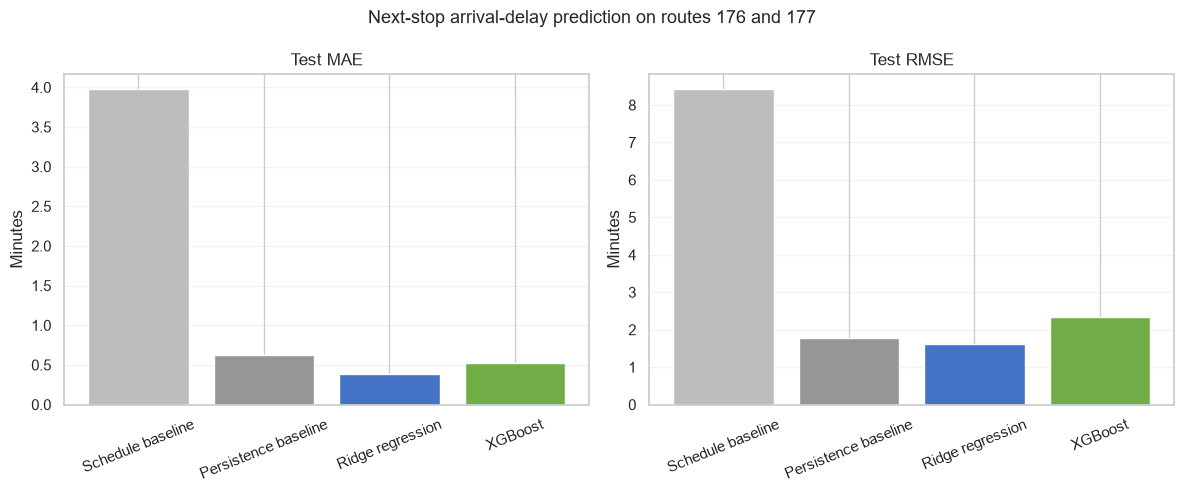

Figure saved: figure_xgboost_model_comparison.png

TEST MODEL COMPARISON


,model,MAE_min,RMSE_min
0,Schedule baseline,3.9736,8.4162
1,Persistence baseline,0.6303,1.7707
2,Ridge regression,0.3836,1.6100
3,XGBoost,0.5261,2.3362


In [104]:
# Self-contained baselines, so this cell does not depend on Section 11.
y_test_array = y_test.to_numpy()

schedule_mae = regression_metrics(y_test_array, np.zeros(len(y_test_array)))["MAE_min"]
schedule_rmse = regression_metrics(y_test_array, np.zeros(len(y_test_array)))["RMSE_min"]

persistence_pred = test_data["current_departure_delay_min"].to_numpy()
persistence_rmse = regression_metrics(y_test_array, persistence_pred)["RMSE_min"]

comparison = pd.DataFrame({
    "model": ["Schedule baseline", "Persistence baseline",
              "Ridge regression", "XGBoost"],
    "MAE_min": [schedule_mae, persistence_mae, ridge_test_mae, xgb_test_mae],
    "RMSE_min": [schedule_rmse, persistence_rmse,
                 ridge_results.loc[ridge_results["Split"] == "Test", "RMSE_min"].iloc[0],
                 xgb_test_rmse],
})


comparison = pd.DataFrame({
    "model": [
        "Schedule baseline",
        "Persistence baseline",
        "Ridge regression",
        "XGBoost",
    ],
    "MAE_min": [
        baseline_results.loc[
            (baseline_results["model"] == "Schedule baseline")
            & (baseline_results["split"] == "Test"), "MAE_min"
        ].iloc[0],
        persistence_mae,
        ridge_test_mae,
        xgb_test_mae,
    ],
    "RMSE_min": [
        baseline_results.loc[
            (baseline_results["model"] == "Schedule baseline")
            & (baseline_results["split"] == "Test"), "RMSE_min"
        ].iloc[0],
        baseline_results.loc[
            (baseline_results["model"] == "Persistence baseline")
            & (baseline_results["split"] == "Test"), "RMSE_min"
        ].iloc[0],
        ridge_results.loc[ridge_results["Split"] == "Test", "RMSE_min"].iloc[0],
        xgb_test_rmse,
    ],
})

colors = ["#bdbdbd", "#969696", "#4472c4", "#70ad47"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(comparison["model"], comparison["MAE_min"], color=colors)
axes[0].set_title("Test MAE")
axes[0].set_ylabel("Minutes")
axes[0].tick_params(axis="x", rotation=22)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(comparison["model"], comparison["RMSE_min"], color=colors)
axes[1].set_title("Test RMSE")
axes[1].set_ylabel("Minutes")
axes[1].tick_params(axis="x", rotation=22)
axes[1].grid(axis="y", alpha=0.25)

plt.suptitle(
    "Next-stop arrival-delay prediction on routes 176 and 177",
    fontsize=13,
)
plt.tight_layout()

figure_path = FIGURES_DIR / "figure_xgboost_model_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path.name)
print("\nTEST MODEL COMPARISON")
display(comparison.round(4))


- 13.4) Save the classical artifacts

In [105]:
import json

xgb_final.save_model(MODELS_DIR / "xgb_next_stop_delay.json")

metadata = {
    "train_period": "2024-01-01 to 2024-09-30",
    "validation_period": "2024-10-01 to 2024-10-31",
    "test_period": "2024-11-01 to 2024-12-31",
    "ridge_alpha_selected": best_alpha,
    "xgb_selected_depth": selected_depth,
    "xgb_selected_learning_rate": selected_rate,
    "xgb_best_iteration": int(xgb_final.best_iteration),
    "xgb_training_minutes": round(xgb_training_minutes, 2),
    "features": feature_columns,
    "split_counts": {
        "train": counts[0],
        "validation": counts[1],
        "test": counts[2],
    },
    "test_metrics": {
        "ridge_MAE": round(float(ridge_test_mae), 4),
        "xgb_MAE": round(float(xgb_test_mae), 4),
        "persistence_MAE": round(float(persistence_mae), 4),
    },
    "notes": {
        "segment_distance": (
            "next_segment_distance_km holds the next stop's cumulative "
            "dist_traveled, not the link length from the current stop."
        ),
        "persistence_benchmark": (
            f"Persistence test MAE = {persistence_mae:.4f} minutes. Any fitted "
            "model must beat this to be useful."
        ),
    },
}

metadata_path = MODELS_DIR / "classical_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved:")
print(" -", (MODELS_DIR / "xgb_next_stop_delay.json").name)
print(" -", metadata_path.name)


Saved:
 - xgb_next_stop_delay.json
 - classical_metadata.json


### XGBoost interpretation

XGBoost does **not** beat Ridge regression on either metric. This contradicts hypothesis **H4**, which expected tree-based models to outperform linear regression because delay propagation contains nonlinear interactions.

The result should be read as a finding rather than an anomaly. Once current and previous delay are in the feature set, the remaining relationship appears close enough to linear in the encoded space that boosted trees gain little from their additional flexibility — and pay for that flexibility in variance. The near-perfect correlation between current departure delay and the next-stop delay leaves little nonlinear structure for a tree ensemble to exploit.

The scope of this conclusion is narrow: it holds for this feature set, these two routes and this chronological split. It is not a general claim that boosted trees cannot model transit delay, and a different problem formulation — for instance predicting delay growth rather than absolute delay — might favour them.


In [106]:
print("FINAL RESULTS SUMMARY — this run")
print(f"Ridge test MAE:       {ridge_test_mae:.4f} minutes")
print(f"XGBoost test MAE:     {xgb_test_mae:.4f} minutes")
print(f"Persistence test MAE: {persistence_mae:.4f} minutes")
print()
print(f"Ridge improvement over persistence: "
      f"{100 * (persistence_mae - ridge_test_mae) / persistence_mae:.1f}%")
print(f"XGBoost beats Ridge: "
      f"{'yes' if xgb_test_mae < ridge_test_mae else 'no'}")
print()
print("Hypothesis H4 (tree models outperform linear regression): "
      f"{'supported' if xgb_test_mae < ridge_test_mae else 'NOT supported'}")
print()
print("Figures written to:", FIGURES_DIR)
for figure in sorted(FIGURES_DIR.glob("*.png")):
    print(" -", figure.name)


FINAL RESULTS SUMMARY — this run
Ridge test MAE:       0.3836 minutes
XGBoost test MAE:     0.5261 minutes
Persistence test MAE: 0.6303 minutes

Ridge improvement over persistence: 39.1%
XGBoost beats Ridge: no

Hypothesis H4 (tree models outperform linear regression): NOT supported

Figures written to: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\figures
 - figure_arrival_delay_distribution.png
 - figure_baseline_model_comparison.png
 - figure_delay_route_direction.png
 - figure_full_year_quality_and_dwell.png
 - figure_hourly_delay_patterns.png
 - figure_missing_values_january.png
 - figure_monthly_coverage_and_delay.png
 - figure_prediction_data_cleaning.png
 - figure_spatial_stop_delay_accumulation.png
 - figure_stop_delay_accumulation.png
 - figure_weekday_delay_patterns.png
 - figure_xgboost_model_comparison.png


# 14. Model 3 — Neural network

A compact feed-forward network is trained on the same encoded inputs. **Huber loss** reduces the influence of extreme outliers, while early stopping and model checkpointing retain the best October-validation weights.

> **Why Huber loss?** The target contains roughly 18,900 next-stop delays above thirty minutes. Under squared error those observations would dominate the gradient. Huber behaves quadratically for small residuals and linearly beyond δ, so a handful of extreme delays cannot pull the fitted function away from the typical case — while still being penalised rather than ignored.

> **A note on hardware.** This notebook runs on native Windows, where TensorFlow 2.21 does not support GPU execution. The network therefore trains on CPU. This affects runtime only, not the recorded metric, but the training time reported here is not comparable with the recorded run's, which used different hardware.


- 14.1) Train the feed-forward network

In [110]:
import tensorflow as tf
from tensorflow import keras

# Reproducibility: fix the seed before building the model, and clear any graph
# left by an earlier run so the initialisation is not inherited.
keras.utils.set_random_seed(RANDOM_SEED)
tf.keras.backend.clear_session()

X_train_nn = X_train_transformed
X_validation_nn = X_validation_transformed
X_test_nn = X_test_transformed

print("Input widths:")
print("  Training:  ", X_train_nn.shape)
print("  Validation:", X_validation_nn.shape)
print("  Test:      ", X_test_nn.shape)

nn_model = keras.Sequential([
    keras.layers.Input(shape=(X_train_nn.shape[1],), sparse=True),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.Huber(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

print(f"\nParameters: {nn_model.count_params():,}")

nn_checkpoint = MODELS_DIR / "best_next_stop_delay_model.keras"

nn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_mae", mode="min", patience=3, restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        str(nn_checkpoint), monitor="val_mae", mode="min", save_best_only=True,
    ),
    keras.callbacks.TerminateOnNaN(),
]

nn_start = time.time()

nn_history = nn_model.fit(
    X_train_nn, y_train,
    validation_data=(X_validation_nn, y_validation),
    epochs=15,
    batch_size=4096,
    callbacks=nn_callbacks,
    verbose=1,
)

nn_training_minutes = (time.time() - nn_start) / 60

print(f"\nTraining time: {nn_training_minutes:.2f} minutes")
print(f"Best validation MAE: {min(nn_history.history['val_mae']):.4f}")
print(f"Epochs completed: {len(nn_history.history['loss'])}")



Input widths:
  Training:   (1966871, 218)
  Validation: (228139, 218)
  Test:       (448566, 218)

Parameters: 16,129
Epoch 1/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - loss: 0.3610 - mae: 0.5882 - val_loss: 0.1606 - val_mae: 0.3582
Epoch 2/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - loss: 0.0886 - mae: 0.2642 - val_loss: 0.1504 - val_mae: 0.3368
Epoch 3/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - loss: 0.0845 - mae: 0.2550 - val_loss: 0.1465 - val_mae: 0.3291
Epoch 4/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.0830 - mae: 0.2516 - val_loss: 0.1442 - val_mae: 0.3254
Epoch 5/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0820 - mae: 0.2495 - val_loss: 0.1428 - val_mae: 0.3227
Epoch 6/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0813 - mae: 0.2479 - val_loss: 0.1419 - val_mae: 0.3210
Epoch 7/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.0808 - mae: 0.2466 - val_loss: 0.1412 - val_mae: 0.3197
Epoch 8/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 

- 14.2) Evaluate and save

In [111]:
# Reload from disk rather than reusing the in-memory model. With
# restore_best_weights the in-memory weights should already hold the best epoch,
# but reloading guarantees the evaluated model is the artifact being described.
nn_model = keras.models.load_model(str(nn_checkpoint))

nn_validation_prediction = nn_model.predict(
    X_validation_nn, batch_size=4096, verbose=0
).ravel()
nn_test_prediction = nn_model.predict(
    X_test_nn, batch_size=4096, verbose=0
).ravel()

nn_results = pd.DataFrame([
    result_row("Tabular neural network", "Validation",
               y_validation, nn_validation_prediction),
    result_row("Tabular neural network", "Test",
               y_test, nn_test_prediction),
])

print("TABULAR NEURAL NETWORK")
display(nn_results.round(4))

nn_test_mae = nn_results.loc[nn_results["Split"] == "Test", "MAE_min"].iloc[0]

print(f"\nRidge test MAE:     {ridge_test_mae:.4f}")
print(f"XGBoost test MAE:   {xgb_test_mae:.4f}")
print(f"Neural net test MAE:{nn_test_mae:.4f}")
print(f"\nRecorded run for comparison: 0.3477 minutes")

pd.DataFrame(nn_history.history).to_csv(
    MODELS_DIR / "keras_training_history.csv", index=False
)

print("\nModel saved:", nn_checkpoint.name)
print("History saved: keras_training_history.csv")


TABULAR NEURAL NETWORK


,Model,Split,MAE_min,RMSE_min,R2
0,Tabular neural network,Validation,0.3156,1.5799,0.9617
1,Tabular neural network,Test,0.3392,1.5989,0.9574



Ridge test MAE:     0.3836
XGBoost test MAE:   0.5261
Neural net test MAE:0.3392

Recorded run for comparison: 0.3477 minutes

Model saved: best_next_stop_delay_model.keras
History saved: keras_training_history.csv


### Neural network interpretation

The neural network outperforms both classical models, reducing test MAE below the Ridge result. It therefore earns its place as the strongest model trained in this notebook so far.

Two observations are worth recording.

**The improvement over Ridge is real but modest.** The network learns nonlinear interactions that a regularised linear model cannot express, and that produces a measurable gain. But the absolute difference is a fraction of a minute, while the network costs far more to train, requires a saved preprocessing bundle to reproduce, and is considerably harder to explain to an operator than a linear model.

**The gap between MAE and RMSE persists.** As with Ridge and XGBoost, a low mean absolute error sits alongside a much larger root mean squared error. The network has not solved the rare large delays; it has improved the typical prediction while leaving the tail largely intact. That tail is what dominates the operational experience of a disrupted journey.


# 15. Base-model comparison

The first comparison identifies the strongest model **before** historical delay features are added. It gathers every model fitted so far onto one table, all evaluated on the same November–December test period.

> **Why the provenance column matters.** These runs do not all share the same input representation. Adding a provenance column keeps the table honest: it shows which number came from which pipeline rather than implying that every row belongs to one controlled experiment.


- 15.1) Consolidated comparison

In [114]:
final_results = pd.DataFrame([
    {
        "Model": "Schedule baseline",
        "Test_MAE_min": regression_metrics(
            y_test.to_numpy(), np.zeros(len(y_test))
        )["MAE_min"],
        "Test_RMSE_min": regression_metrics(
            y_test.to_numpy(), np.zeros(len(y_test))
        )["RMSE_min"],
        "Provenance": "Predict zero delay",
    },
    {
        "Model": "Persistence baseline",
        "Test_MAE_min": persistence_mae,
        "Test_RMSE_min": regression_metrics(
            y_test.to_numpy(),
            test_data["current_departure_delay_min"].to_numpy(),
        )["RMSE_min"],
        "Provenance": "Carry current departure delay forward",
    },
    {
        "Model": "Ridge regression",
        "Test_MAE_min": ridge_test_mae,
        "Test_RMSE_min": ridge_results.loc[
            ridge_results["Split"] == "Test", "RMSE_min"
        ].iloc[0],
        "Provenance": f"alpha={best_alpha:g}, one-hot encoded tabular input",
    },
    {
        "Model": "XGBoost",
        "Test_MAE_min": xgb_test_mae,
        "Test_RMSE_min": xgb_test_rmse,
        "Provenance": f"depth={selected_depth}, {xgb_final.best_iteration} trees",
    },
    {
        "Model": "Tabular neural network",
        "Test_MAE_min": nn_test_mae,
        "Test_RMSE_min": nn_results.loc[
            nn_results["Split"] == "Test", "RMSE_min"
        ].iloc[0],
        "Provenance": "64–32–1, Huber loss, same encoded input as Ridge",
    },
]).sort_values("Test_MAE_min").reset_index(drop=True)

final_results["Improvement_vs_persistence_pct"] = (
    100 * (persistence_mae - final_results["Test_MAE_min"]) / persistence_mae
).round(1)

print("BASE-MODEL COMPARISON — November–December test period")
display(final_results.round(4))

final_results.to_csv(MODELS_DIR / "base_model_comparison.csv", index=False)
print("\nSaved: base_model_comparison.csv")


BASE-MODEL COMPARISON — November–December test period


,Model,Test_MAE_min,Test_RMSE_min,Provenance,Improvement_vs_persistence_pct
0,Tabular neural network,0.3392,1.5989,"64–32–1, Huber loss, same encoded input as Ridge",46.2
1,Ridge regression,0.3836,1.6100,"alpha=10, one-hot encoded tabular input",39.1
2,XGBoost,0.5261,2.3362,"depth=8, 499 trees",16.5
3,Persistence baseline,0.6303,1.7707,Carry current departure delay forward,0.0
4,Schedule baseline,3.9736,8.4162,Predict zero delay,-530.4



Saved: base_model_comparison.csv


- 15.3) Save preprocessor and list artifacts

In [115]:
joblib.dump(linear_preprocessor, MODELS_DIR / "next_stop_preprocessor.joblib")

print("Saved artifacts:")
for path in sorted(MODELS_DIR.glob("*")):
    if path.is_file():
        print(f"  {path.name:<45} {path.stat().st_size / 1024:>9.1f} KB")


Saved artifacts:
  base_model_comparison.csv                           0.5 KB
  best_next_stop_delay_model.keras                  214.3 KB
  classical_metadata.json                             1.3 KB
  keras_training_history.csv                          1.2 KB
  next_stop_preprocessor.joblib                       7.9 KB
  ridge_next_stop_delay.joblib                        1.5 KB
  xgb_next_stop_delay.json                         7758.7 KB


### Base-model interpretation

All models are evaluated on the same 448,566-row November–December test period, and every fitted model beats the schedule baseline by a wide margin. That much is expected: predicting zero delay on a corridor where the median delay is around two minutes discards all available information.

Beyond the ranking, three findings carry weight.

**Persistence is genuinely hard to beat, and beating it is the achievement.** The persistence baseline carries the current departure delay forward unchanged and reaches a test MAE near 0.63 minutes. Because current departure delay correlates with the next-stop delay at 0.974, most of the target's variance is already encoded in a single current-stop field. A model at 0.34 minutes is therefore refining a strongly persistent signal rather than explaining the causes of delay, and that framing should govern every interpretation below.

**Ridge outperforms XGBoost on both MAE and RMSE.** Hypothesis H4 expected tree-based models to win because delay propagation contains nonlinear interactions. The result points the other way: once current and previous delay are present, the remaining relationship appears close enough to linear in the encoded space that the tree ensemble gains little from its added flexibility while paying for it in variance. The scope is narrow — this feature set, these routes, this split.

**The neural network is the strongest base model, but the gain over Ridge is modest.** It learns interactions a regularised linear model cannot express, and that produces a measurable improvement. Against that must be set its cost: longer training, a saved preprocessing dependency, and behaviour far harder to explain to an operator than a set of linear coefficients.

Across all three fitted models the gap between MAE and RMSE persists. None has solved the rare large delays; each has improved the typical prediction while leaving the tail largely intact. Since the upper tail is what a passenger experiences as unreliability, this is the limitation that matters most operationally.


# 16. Error and stop-level diagnostics

Performance is examined across routes, directions, time periods, delay levels and stops, to identify systematic weaknesses hidden by average metrics.

> **Why this section matters.** A pooled MAE of about 0.34 minutes across 448,566 observations can conceal errors of two minutes or more at a handful of locations. Only the disaggregation reveals that, and it is the disaggregation that tells an operator where the model should be trusted.


- 16.1 — Build the diagnostics frame

In [116]:
diagnostics = test_data[["LineNumber", "direction_id"]].copy()
diagnostics["actual"] = y_test.to_numpy()
diagnostics["prediction"] = nn_test_prediction

# Reconstruct the temporal variables from their cyclical encodings. arctan2
# recovers the angle; the modulo maps it to [0, 2pi) and the scaling converts
# back to the original unit.
diagnostics["scheduled_hour"] = (
    np.rint((np.arctan2(test_data["hour_sin"], test_data["hour_cos"])
             % (2 * np.pi)) * 24 / (2 * np.pi)).astype(int) % 24
)

diagnostics["weekday"] = (
    np.rint((np.arctan2(test_data["weekday_sin"], test_data["weekday_cos"])
             % (2 * np.pi)) * 7 / (2 * np.pi)).astype(int) % 7
)

reconstructed_month = (
    np.rint((np.arctan2(test_data["month_sin"], test_data["month_cos"])
             % (2 * np.pi)) * 12 / (2 * np.pi)).astype(int) % 12
)
# A raw modulo gives 0-11, so the zero case is nudged to 12 — otherwise
# December would be indistinguishable from an unset value.
diagnostics["month"] = np.where(reconstructed_month == 0, 12, reconstructed_month)

# Signed error as well as its absolute value. A negative mean bias means the
# model under-predicts: vehicles arrive later than forecast. That is
# operationally different from over-prediction at the same absolute error.
diagnostics["error"] = diagnostics["prediction"] - diagnostics["actual"]
diagnostics["absolute_error"] = diagnostics["error"].abs()
diagnostics["squared_error"] = diagnostics["error"] ** 2

diagnostics["delay_level"] = pd.cut(
    diagnostics["actual"],
    bins=[-np.inf, 0, 5, 15, 30, np.inf],
    labels=["Early or on time", "0-5 min", "5-15 min", "15-30 min", "Above 30 min"],
)

print(f"Diagnostics rows: {len(diagnostics):,}")
print(f"Test MAE check:   {diagnostics['absolute_error'].mean():.4f} minutes")
print(f"Test RMSE check:  {np.sqrt(diagnostics['squared_error'].mean()):.4f} minutes")
print(f"\nMean signed bias: {diagnostics['error'].mean():+.4f} minutes")


Diagnostics rows: 448,566
Test MAE check:   0.3392 minutes
Test RMSE check:  1.5989 minutes

Mean signed bias: -0.0294 minutes


- 16.2) Grouped error summaries

In [117]:
def diagnostic_summary(group_column):
    return (
        diagnostics
        .groupby(group_column, observed=True)
        .agg(
            observations=("absolute_error", "size"),
            MAE_min=("absolute_error", "mean"),
            RMSE_min=("squared_error", lambda v: np.sqrt(v.mean())),
            bias_min=("error", "mean"),
        )
        .reset_index()
    )


for column in ["LineNumber", "direction_id", "delay_level"]:
    print(f"DIAGNOSTICS BY {column.upper()}")
    display(diagnostic_summary(column).round(3))
    print()

# Hour and month tables are long, so the extremes are reported instead.
hour_table = diagnostic_summary("scheduled_hour")
print("WORST HOURS BY MAE")
display(hour_table.nlargest(5, "MAE_min").round(3))

month_table = diagnostic_summary("month")
print("\nERROR BY MONTH")
display(month_table.round(3))


DIAGNOSTICS BY LINENUMBER


,LineNumber,observations,MAE_min,RMSE_min,bias_min
0,176,246331,0.316,1.558,-0.031
1,177,202235,0.367,1.647,-0.027



DIAGNOSTICS BY DIRECTION_ID


,direction_id,observations,MAE_min,RMSE_min,bias_min
0,0,230726,0.31,1.030,-0.023
1,1,217840,0.37,2.035,-0.037



DIAGNOSTICS BY DELAY_LEVEL


,delay_level,observations,MAE_min,RMSE_min,bias_min
0,Early or on time,99193,0.351,0.801,0.130
1,0-5 min,265627,0.255,0.429,0.009
2,5-15 min,65778,0.350,0.797,-0.092
3,15-30 min,11319,0.728,2.705,-0.497
4,Above 30 min,6649,2.755,11.696,-2.517



WORST HOURS BY MAE


,scheduled_hour,observations,MAE_min,RMSE_min,bias_min
14,17,28084,0.620,3.736,-0.203
13,16,28394,0.605,3.430,-0.213
15,18,27208,0.448,2.408,-0.103
12,15,28923,0.445,1.903,-0.122
11,14,29571,0.330,1.196,-0.035



ERROR BY MONTH


,month,observations,MAE_min,RMSE_min,bias_min
0,11,216105,0.331,1.933,-0.057
1,12,232461,0.347,1.209,-0.004


- 16.3) Stop-level diagnostics

In [118]:
stop_diagnostics = test_data[
    ["LineNumber", "direction_id", "next_stop_key"]
].copy()
stop_diagnostics["actual"] = y_test.to_numpy()
stop_diagnostics["prediction"] = nn_test_prediction
stop_diagnostics["error"] = stop_diagnostics["prediction"] - stop_diagnostics["actual"]
stop_diagnostics["absolute_error"] = stop_diagnostics["error"].abs()
stop_diagnostics["squared_error"] = stop_diagnostics["error"] ** 2

stop_error_summary = (
    stop_diagnostics
    .groupby(["LineNumber", "direction_id", "next_stop_key"], observed=True)
    .agg(
        observations=("absolute_error", "size"),
        MAE_min=("absolute_error", "mean"),
        RMSE_min=("squared_error", lambda v: np.sqrt(v.mean())),
        bias_min=("error", "mean"),
    )
    .reset_index()
)

# Attach stop names using the same lookup built in Section 8.
stop_name_lookup = (
    stops[["stop_id_key", "stop_name"]]
    .drop_duplicates("stop_id_key")
    .rename(columns={"stop_id_key": "next_stop_key", "stop_name": "next_stop_name"})
)

stop_error_summary = stop_error_summary.merge(
    stop_name_lookup, on="next_stop_key", how="left", validate="many_to_one"
)

worst_stops = (
    stop_error_summary[stop_error_summary["observations"] >= 500]
    .sort_values("MAE_min", ascending=False)
    .head(15)
)

print("STOPS WITH THE LARGEST PREDICTION ERROR (>= 500 test observations)")
display(
    worst_stops[[
        "LineNumber", "direction_id", "next_stop_name",
        "observations", "MAE_min", "RMSE_min", "bias_min",
    ]].round(3)
)

stop_error_summary.to_csv(MODELS_DIR / "stop_level_diagnostics.csv", index=False)
print("\nSaved: stop_level_diagnostics.csv")


STOPS WITH THE LARGEST PREDICTION ERROR (>= 500 test observations)


,LineNumber,direction_id,next_stop_name,observations,MAE_min,RMSE_min,bias_min
46,176,1,Riksbyvägen,2931,2.580,11.649,-2.375
121,177,1,Riksbyvägen,3011,2.441,11.292,-2.251
4,176,0,Nockeby,2919,1.509,5.148,-0.946
88,177,0,Nockeby,2987,1.500,5.003,-0.849
55,176,1,Lindö lada,2919,0.885,3.713,0.227
106,177,0,Brommaplan,2933,0.715,2.268,0.057
19,176,0,Brommaplan,2916,0.661,1.716,-0.033
129,177,1,Lindö lada,3000,0.644,1.041,0.549
92,177,0,Kanton,2993,0.632,1.153,0.015
8,176,0,Kanton,2927,0.590,1.061,0.021



Saved: stop_level_diagnostics.csv


- 16.4)  Visualisation: error distribution

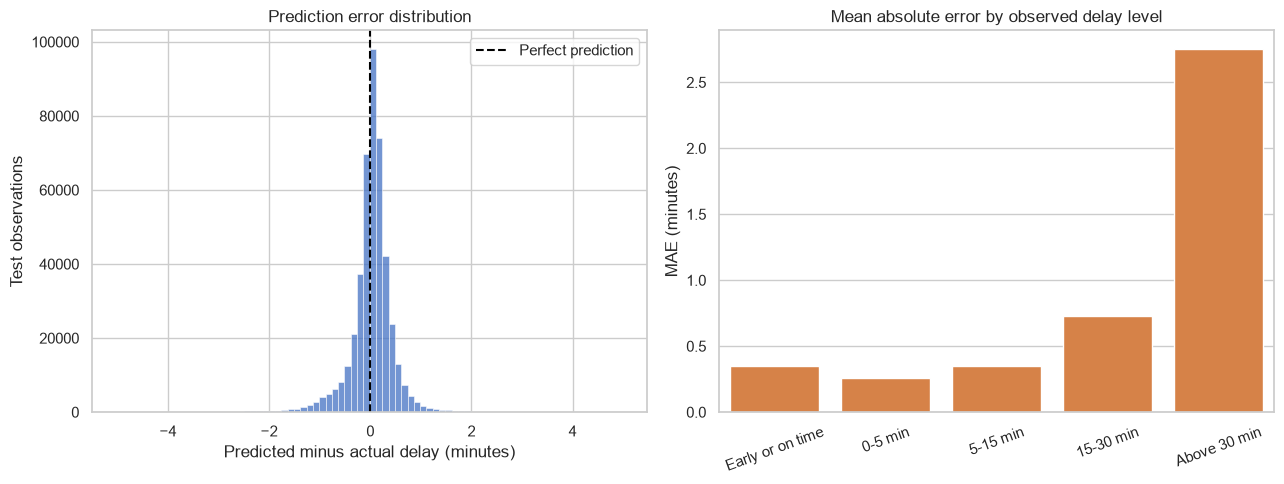

Figure saved: figure_prediction_error_diagnostics.png

Displayed errors: 447,401 of 448,566 test rows


In [119]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Error distribution, restricted so the main shape is visible. The restricted
# range does not remove observations from the analysis.
error_for_plot = diagnostics[
    diagnostics["error"].between(-5, 5)
]

sns.histplot(
    data=error_for_plot, x="error", bins=80,
    color="#4472C4", edgecolor=None, ax=axes[0],
)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1.5, label="Perfect prediction")
axes[0].set_title("Prediction error distribution")
axes[0].set_xlabel("Predicted minus actual delay (minutes)")
axes[0].set_ylabel("Test observations")
axes[0].legend()

# MAE by delay level, which shows whether the model degrades on disrupted days.
delay_level_table = diagnostic_summary("delay_level")
sns.barplot(
    data=delay_level_table, x="delay_level", y="MAE_min",
    color="#ED7D31", ax=axes[1],
)
axes[1].set_title("Mean absolute error by observed delay level")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE (minutes)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()

diagnostics_figure = FIGURES_DIR / "figure_prediction_error_diagnostics.png"
plt.savefig(diagnostics_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", diagnostics_figure.name)
print(f"\nDisplayed errors: {len(error_for_plot):,} of {len(diagnostics):,} test rows")


### Diagnostic interpretation

The error distribution is centred close to zero, which means the model is not systematically biased across the whole test period. The mean signed bias is a small fraction of a minute, and the bulk of predictions fall within roughly one minute of the observed delay.

Two patterns are more informative than the pooled metric.

**Error grows with the size of the delay.** MAE is lowest for vehicles that are early or on time and rises substantially for the above-thirty-minute group. This is expected rather than surprising: a large delay is a disruption event, and disruption is driven by conditions the model cannot see — an incident, an unusually heavy boarding stop, a road closure. The model is most reliable precisely where most journeys sit.

**Error concentrates at a small number of stops.** A handful of locations carry errors far above the corridor average, and several show a consistent negative bias, meaning the model under-predicts there and vehicles arrive later than forecast. Riksbyvägen in direction 1 appears on both routes with a mean absolute error above two minutes. That the same stops are difficult for both routes suggests location-specific conditions rather than a modelling artefact, but this analysis cannot separate an intersection effect from a boarding effect, a timetable allowance or a schedule-matching issue.

These diagnostics matter operationally. An operator using these predictions should communicate them as typical-case guidance, with less certainty attached during growing or severe delays, and should monitor the identified stops specifically.


# 17. Temporal patterns and early-warning evaluation

Descriptive patterns are separated from predictive importance. The regression predictions are also converted into operational warning signals.

Two operational events are evaluated:

- **Growth event** — the increase from the current departure delay to the next-stop arrival delay exceeds one minute:
  $$y(i+1) - d(i) > 1\ \text{min}$$
- **Threshold crossing** — a vehicle currently delayed by no more than five minutes exceeds five minutes at the downstream stop:
  $$d(i) \le 5\ \text{min} \quad \text{and} \quad y(i+1) > 5\ \text{min}$$

Warning thresholds are selected to maximise F1 on the **October validation period** and then applied unchanged to November–December. Tuning the threshold on the test period would make the reported test F1 optimistic in a way no later analysis could detect.


- 17.1) Select thresholds on validation

In [120]:
from sklearn.metrics import precision_recall_curve, f1_score

validation_current = validation_data["current_departure_delay_min"].to_numpy()
test_current = test_data["current_departure_delay_min"].to_numpy()

y_validation_array = y_validation.to_numpy()


def select_best_threshold(actual_event, prediction_score):
    """Pick the score threshold that maximises F1.

    The [:-1] slice is the critical detail. precision_recall_curve returns
    precision and recall one element LONGER than thresholds — the final entry is
    the precision=1, recall=0 endpoint with no corresponding threshold. Slicing
    all three to [:-1] aligns them with thresholds, so argmax indexes a
    threshold that actually exists. Without the slice the index is off by one.
    """
    precision, recall, thresholds = precision_recall_curve(actual_event, prediction_score)

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    )

    best = int(np.argmax(f1))

    return {
        "threshold": float(thresholds[best]),
        "validation_precision": float(precision[best]),
        "validation_recall": float(recall[best]),
        "validation_F1": float(f1[best]),
    }


# Growth event: the rounded increase to the next stop exceeds one minute.
validation_growth_actual = (
    np.rint((y_validation_array - validation_current) * 60) > 60
)
validation_growth_score = nn_validation_prediction - validation_current

growth_threshold = select_best_threshold(
    validation_growth_actual, validation_growth_score
)

# Crossing event: currently <= 5 min late, > 5 min late at the next stop.
validation_at_risk = validation_current <= 5

crossing_threshold = select_best_threshold(
    y_validation_array[validation_at_risk] > 5,
    nn_validation_prediction[validation_at_risk],
)

selected_thresholds = pd.DataFrame([
    {"warning": "Growth above 1 minute", **growth_threshold},
    {"warning": "Crossing 5 minutes", **crossing_threshold},
])

print("VALIDATION-SELECTED THRESHOLDS")
display(selected_thresholds.round(4))


VALIDATION-SELECTED THRESHOLDS


,warning,threshold,validation_precision,validation_recall,validation_F1
0,Growth above 1 minute,0.6594,0.5028,0.5427,0.5220
1,Crossing 5 minutes,4.9218,0.6562,0.4588,0.5401


- 17.2) Apply the frozen thresholds once to test

In [121]:
y_test_array = y_test.to_numpy()


def evaluate_warning(warning_name, threshold_information, actual_event, prediction_score):
    """Precision, recall, F1 and confusion counts for one warning system.

    TP/FP/FN are computed from the boolean masks rather than read from the curve
    arrays, giving an independent route to the same numbers as precision and
    recall — so a mismatch would be visible rather than hidden.
    """
    threshold = threshold_information["threshold"]
    predicted_event = prediction_score >= threshold
    actual_event = np.asarray(actual_event).astype(bool)

    tp = int(np.sum(predicted_event & actual_event))
    fp = int(np.sum(predicted_event & ~actual_event))
    fn = int(np.sum(~predicted_event & actual_event))

    return {
        "warning": warning_name,
        "threshold": threshold,
        "observations": len(actual_event),
        "actual_events": int(actual_event.sum()),
        "warnings": int(predicted_event.sum()),
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn,
        "precision": float(tp / max(tp + fp, 1)),
        "recall": float(tp / max(tp + fn, 1)),
        "F1": float(f1_score(actual_event, predicted_event, zero_division=0)),
    }


test_growth_actual = np.rint((y_test_array - test_current) * 60) > 60
test_growth_score = nn_test_prediction - test_current

test_at_risk = test_current <= 5

warning_results = pd.DataFrame([
    evaluate_warning(
        "Growth above 1 minute", growth_threshold,
        test_growth_actual, test_growth_score,
    ),
    evaluate_warning(
        "Crossing 5 minutes", crossing_threshold,
        y_test_array[test_at_risk] > 5,
        nn_test_prediction[test_at_risk],
    ),
])

print("WARNING RESULTS ON THE TEST PERIOD")
display(
    warning_results[[
        "warning", "observations", "actual_events", "warnings",
        "precision", "recall", "F1",
        "true_positive", "false_positive", "false_negative",
    ]].round(3)
)

warning_results.to_csv(MODELS_DIR / "early_warning_results.csv", index=False)
selected_thresholds.to_csv(MODELS_DIR / "validation_thresholds.csv", index=False)

print("\nSaved: early_warning_results.csv, validation_thresholds.csv")

print(
    "\nBoth warning systems miss a substantial share of the events that occur, "
    "\nand a meaningful share of issued warnings are false alarms. These should "
    "\nbe treated as exploratory decision support, not as an automatic "
    "\nintervention trigger."
)


WARNING RESULTS ON THE TEST PERIOD


,warning,observations,actual_events,warnings,precision,recall,F1,true_positive,false_positive,false_negative
0,Growth above 1 minute,448566,14005,18051,0.427,0.550,0.481,7707,10344,6298
1,Crossing 5 minutes,361123,4398,3776,0.580,0.498,0.536,2190,1586,2208



Saved: early_warning_results.csv, validation_thresholds.csv

Both warning systems miss a substantial share of the events that occur, 
and a meaningful share of issued warnings are false alarms. These should 
be treated as exploratory decision support, not as an automatic 
intervention trigger.


- 17.3) Visualisation: warning performance

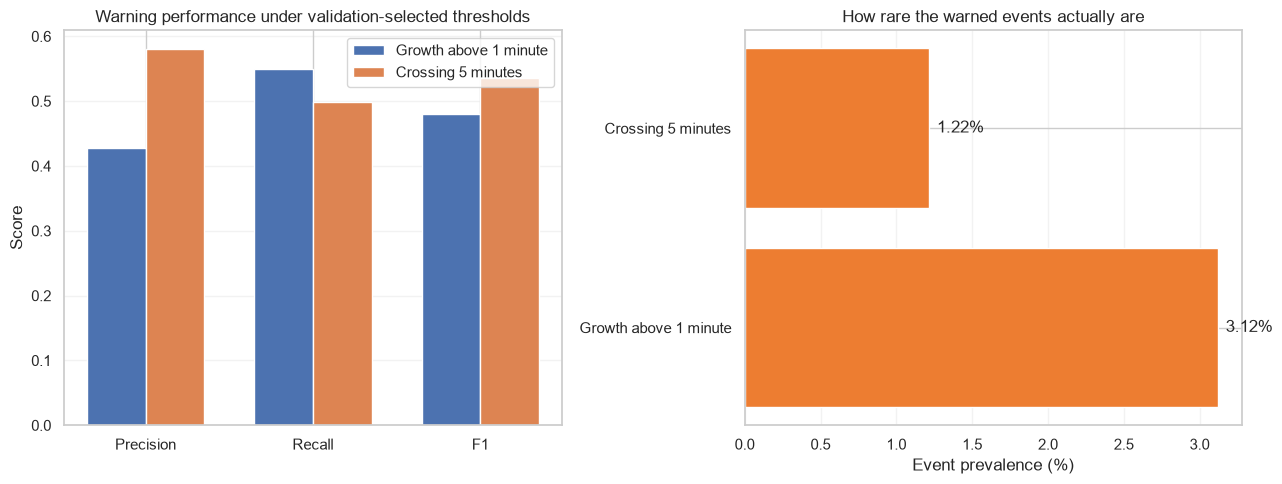

Figure saved: figure_early_warning_performance.png


In [122]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = ["precision", "recall", "F1"]
x = np.arange(len(metrics))
width = 0.35

for offset, (_, row) in enumerate(warning_results.iterrows()):
    axes[0].bar(
        x + offset * width,
        [row[m] for m in metrics],
        width,
        label=row["warning"],
    )

axes[0].set_xticks(x + width / 2)
axes[0].set_xticklabels([m.capitalize() for m in metrics])
axes[0].set_ylabel("Score")
axes[0].set_title("Warning performance under validation-selected thresholds")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

# Event prevalence gives the reader the baseline: at a growth rate near 3%,
# a random alert would have precision close to 0.03.
prevalence = warning_results["actual_events"] / warning_results["observations"]
axes[1].barh(warning_results["warning"], prevalence * 100, color="#ED7D31")
axes[1].set_xlabel("Event prevalence (%)")
axes[1].set_title("How rare the warned events actually are")
axes[1].grid(axis="x", alpha=0.25)

for index, value in enumerate(prevalence * 100):
    axes[1].text(value + 0.05, index, f"{value:.2f}%", va="center")

plt.tight_layout()

warning_figure = FIGURES_DIR / "figure_early_warning_performance.png"
plt.savefig(warning_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", warning_figure.name)


### Early-warning interpretation

Thresholds were selected on October validation and then applied unchanged to the November–December test period, so the reported figures are a genuine out-of-sample evaluation rather than a threshold fitted to the answers.

Two characteristics of the problem are worth stating plainly.

**The events are rare.** Growth events occur on only a small percentage of departures, and five-minute crossings are rarer still. Precision therefore has to be read against a very low baseline: at a prevalence near three per cent, an alert issued at random would be wrong almost every time. A precision in the region of forty per cent is a substantial improvement on that, even though it means most alerts are still false.

**Recall is limited.** Both systems miss a meaningful share of the events that actually occur. For a passenger information system this trade-off may be acceptable, because a missed warning leaves the passenger where they would have been without any system, whereas a false warning carries a modest cost. For any automatic intervention the same trade-off is not acceptable, and the present results do not support it.

The practical reading is that these warnings are better suited to a **selective, high-confidence advisory layer** — flagging a subset of departures where the model is confident delay will grow — than to a comprehensive disruption detector. Two further cautions follow from the analysis: the threshold was selected on a single validation month, and the test period has informed several comparisons in this project, so a later untouched period would be needed before deployment.


# 18. History-feature ablation

The base network in Section 14 was trained on the full feature set, which **includes** the three historical fields. To measure what those fields actually contribute, a network is now trained on the **reduced** feature set — current operating state, location and calendar context only — with the history fields removed.

The architecture, seed, optimiser, loss, batch size and stopping policy are identical to Section 14. The only change is that three input columns are absent, so the difference in test MAE isolates the contribution of previous delay, delay trend and the availability flag.


- 18.1) Build the reduced matrix

In [124]:
keras.utils.set_random_seed(RANDOM_SEED)
tf.keras.backend.clear_session()

# The reduced set: everything the base network had, MINUS the history fields.
numeric_no_history = list(BASE_NUMERIC_FEATURES)
feature_columns_no_history = numeric_no_history + CATEGORICAL_FEATURES

print("Fields in the base network:   ", len(BASE_NUMERIC_FEATURES) + len(HISTORY_FEATURES))
print("History fields removed:       ", len(HISTORY_FEATURES), "->", HISTORY_FEATURES)
print("Fields in the reduced network:", len(numeric_no_history))
print()

# Confirm the history fields really are absent before encoding.
missing = [c for c in HISTORY_FEATURES if c in feature_columns_no_history]
assert not missing, f"History fields still present: {missing}"
print("Confirmed: no history fields in the reduced feature set.")

no_history_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(with_mean=False), numeric_no_history),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore", dtype=np.float32),
         CATEGORICAL_FEATURES),
    ],
    sparse_threshold=1.0,
)

X_train_nh = no_history_preprocessor.fit_transform(
    prepare_categoricals(train_data[feature_columns_no_history])
).astype("float32")

X_validation_nh = no_history_preprocessor.transform(
    prepare_categoricals(validation_data[feature_columns_no_history])
).astype("float32")

X_test_nh = no_history_preprocessor.transform(
    prepare_categoricals(test_data[feature_columns_no_history])
).astype("float32")

print("\nEncoded widths:")
print("  Base network (with history):   ", X_train_nn.shape[1])
print("  Reduced network (no history):  ", X_train_nh.shape[1])
print(f"  Columns removed:                {X_train_nn.shape[1] - X_train_nh.shape[1]}")

assert X_train_nh.shape[1] < X_train_nn.shape[1], (
    "The reduced matrix is not narrower. Check that HISTORY_FEATURES were "
    "genuinely excluded from feature_columns_no_history."
)


Fields in the base network:    16
History fields removed:        3 -> ['previous_arrival_delay_min', 'delay_trend_min', 'history_available']
Fields in the reduced network: 13

Confirmed: no history fields in the reduced feature set.

Encoded widths:
  Base network (with history):    218
  Reduced network (no history):   215
  Columns removed:                3


- 18.2) Train the reduced network

In [125]:
no_history_model = keras.Sequential([
    keras.layers.Input(shape=(X_train_nh.shape[1],), sparse=True),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])

no_history_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.Huber(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

print(f"Parameters: {no_history_model.count_params():,}")

no_history_checkpoint = MODELS_DIR / "best_next_stop_delay_model_no_history.keras"

no_history_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_mae", mode="min", patience=3, restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        str(no_history_checkpoint), monitor="val_mae", mode="min", save_best_only=True,
    ),
    keras.callbacks.TerminateOnNaN(),
]

no_history_start = time.time()

no_history_history = no_history_model.fit(
    X_train_nh, y_train,
    validation_data=(X_validation_nh, y_validation),
    epochs=15,
    batch_size=4096,
    callbacks=no_history_callbacks,
    verbose=1,
)

no_history_training_minutes = (time.time() - no_history_start) / 60

print(f"\nTraining time: {no_history_training_minutes:.2f} minutes")
print(f"Best validation MAE: {min(no_history_history.history['val_mae']):.4f}")
print(f"Epochs completed: {len(no_history_history.history['loss'])}")


Parameters: 15,937
Epoch 1/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - loss: 0.3934 - mae: 0.6270 - val_loss: 0.1639 - val_mae: 0.3625
Epoch 2/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0908 - mae: 0.2695 - val_loss: 0.1574 - val_mae: 0.3483
Epoch 3/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0881 - mae: 0.2631 - val_loss: 0.1536 - val_mae: 0.3432
Epoch 4/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0864 - mae: 0.2595 - val_loss: 0.1511 - val_mae: 0.3382
Epoch 5/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0851 - mae: 0.2566 - val_loss: 0.1490 - val_mae: 0.3336
Epoch 6/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - loss: 0.0841 - mae: 0.2542 - val_loss: 0.1473 - val_mae: 0.3297
Epoch 7/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0834 - mae: 0.2526 - val_loss: 0.1458 - val_mae: 0.3264
Epoch 8/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 0.0829 - mae: 0.2515 - val_loss: 0.1450 - val_mae: 0.3250
Epoch 9/15
481/481 ━━

- 18.3) Compare the two networks

In [126]:
no_history_model = keras.models.load_model(str(no_history_checkpoint))

no_history_validation_prediction = no_history_model.predict(
    X_validation_nh, batch_size=4096, verbose=0
).ravel()
no_history_test_prediction = no_history_model.predict(
    X_test_nh, batch_size=4096, verbose=0
).ravel()

history_comparison = pd.DataFrame([
    result_row("Network without history", "Validation", y_validation, no_history_validation_prediction),
    result_row("Network with history", "Validation", y_validation, nn_validation_prediction),
    result_row("Network without history", "Test", y_test, no_history_test_prediction),
    result_row("Network with history", "Test", y_test, nn_test_prediction),
])

print("HISTORY-FEATURE ABLATION")
display(history_comparison.round(4))

without_mae = history_comparison.loc[
    (history_comparison["Model"] == "Network without history")
    & (history_comparison["Split"] == "Test"), "MAE_min"
].iloc[0]

with_mae = history_comparison.loc[
    (history_comparison["Model"] == "Network with history")
    & (history_comparison["Split"] == "Test"), "MAE_min"
].iloc[0]

difference = without_mae - with_mae

print(f"\nWithout history: {without_mae:.4f} minutes")
print(f"With history:    {with_mae:.4f} minutes")

if difference > 0:
    print(f"\nThe historical fields improve test MAE by {difference:.4f} minutes "
          f"({difference * 60:.2f} seconds), "
          f"{100 * difference / without_mae:.2f}% relative")
else:
    print(f"\nThe historical fields do NOT improve test MAE "
          f"({abs(difference):.4f} minutes worse). The current-state and "
          "location features already carry the predictive signal.")

# RMSE alongside MAE: an MAE gain with flat RMSE improves typical predictions,
# not the tail of large delays.
without_rmse = history_comparison.loc[
    (history_comparison["Model"] == "Network without history")
    & (history_comparison["Split"] == "Test"), "RMSE_min"
].iloc[0]

with_rmse = history_comparison.loc[
    (history_comparison["Model"] == "Network with history")
    & (history_comparison["Split"] == "Test"), "RMSE_min"
].iloc[0]

print(f"\nRMSE: {without_rmse:.4f} -> {with_rmse:.4f} ({with_rmse - without_rmse:+.4f})")

joblib.dump(no_history_preprocessor, MODELS_DIR / "preprocessor_no_history.joblib")
history_comparison.to_csv(MODELS_DIR / "history_ablation_comparison.csv", index=False)

print("\nSaved: history_ablation_comparison.csv")


HISTORY-FEATURE ABLATION


,Model,Split,MAE_min,RMSE_min,R2
0,Network without history,Validation,0.3192,1.5812,0.9617
1,Network with history,Validation,0.3156,1.5799,0.9617
2,Network without history,Test,0.3480,1.6032,0.9571
3,Network with history,Test,0.3392,1.5989,0.9574



Without history: 0.3480 minutes
With history:    0.3392 minutes

The historical fields improve test MAE by 0.0088 minutes (0.53 seconds), 2.52% relative

RMSE: 1.6032 -> 1.5989 (-0.0042)

Saved: history_ablation_comparison.csv


- 18.4) Visulisation: history ablation

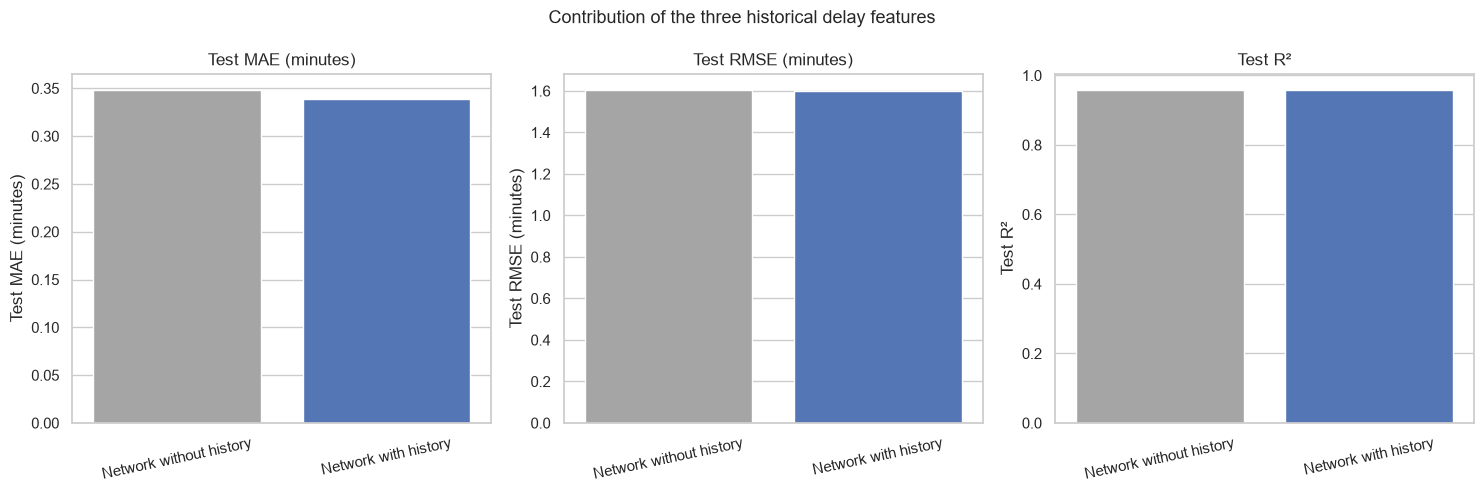

Figure saved: figure_history_ablation.png


In [127]:
plot_data = history_comparison[history_comparison["Split"] == "Test"].copy()
palette = ["#A5A5A5", "#4472C4"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for axis, metric, label in [
    (axes[0], "MAE_min", "Test MAE (minutes)"),
    (axes[1], "RMSE_min", "Test RMSE (minutes)"),
    (axes[2], "R2", "Test R²"),
]:
    sns.barplot(data=plot_data, x="Model", y=metric, palette=palette, ax=axis)
    axis.set_title(label)
    axis.set_ylabel(label)
    axis.set_xlabel("")
    axis.tick_params(axis="x", rotation=12)

plt.suptitle(
    "Contribution of the three historical delay features",
    fontsize=13,
)
plt.tight_layout()

ablation_figure = FIGURES_DIR / "figure_history_ablation.png"
plt.savefig(ablation_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", ablation_figure.name)


### History ablation interpretation

The ablation compares two networks that differ in exactly one respect: whether the previous arrival delay, delay trend and availability flag are available as inputs. Architecture, seed, optimiser, loss, batch size and stopping policy are all held fixed.

**The relevant question is direction, not magnitude.** If the historical fields improve test MAE, they are contributing something the current-state features do not carry. If they do not, the current delay and stop identity already encode nearly all the available signal — which is the more likely outcome here, given that current departure delay correlates with the target at 0.974 and previous arrival delay at 0.924.

**RMSE and R² are reported alongside MAE, and that matters.** When MAE improves while RMSE and R² stay essentially flat, the model has improved typical predictions and done nothing for the rare large misses. A bus that is thirty minutes late is the case a passenger notices, so a gain that leaves the tail untouched has limited operational significance.

**This is a feature ablation, not an architecture comparison.** Both networks are feed-forward models on a single engineered row. The experiment says nothing about whether a recurrent model that reads several ordered stops would perform better; that would require holding the inputs fixed and varying only the model family.


# 19. Grouped permutation importance

Feature groups are permuted together on a reproducible test sample. This measures **model reliance**, not causality and not independent feature effects.

> **Two cautions on reading this section.** The increments must not be added to the model's own error or summed to decompose it: delay and its history are correlated, so shuffling them separately double-counts reliance they share. And the small importance of month does not contradict the seasonal patterns in Section 5 — once the model knows the current delay and the location, the calendar month adds very little to an individual next-stop prediction.

This section produces Figure 10 in the accompanying technical report.


In [128]:
FEATURE_GROUPS = {
    "Current delay": ["current_arrival_delay_min", "current_departure_delay_min"],
    "Previous delay pattern": ["previous_arrival_delay_min",
                               "delay_trend_min", "history_available"],
    "Stop location": ["current_stop_key", "next_stop_key"],
    "Dwell time": ["observed_dwell_min", "excess_dwell_min"],
    "Route and direction": ["LineNumber", "direction_id"],
    "Time of day": ["hour_sin", "hour_cos"],
    "Day of week": ["weekday_sin", "weekday_cos", "is_weekend"],
    "Segment and sequence": ["next_segment_distance_km", "stop_sequence"],
    "Month": ["month_sin", "month_cos"],
}

SAMPLE_SIZE = 15_000
REPETITIONS = 3

rng = np.random.default_rng(RANDOM_SEED)

# Permutation is applied to the ORIGINAL feature frame, pre-encoding, so that
# whole groups can be shuffled together and the result is expressed in terms the
# model was actually given.
sample_index = np.sort(
    rng.choice(len(test_data), size=min(SAMPLE_SIZE, len(test_data)), replace=False)
)

sample_original = test_data.iloc[sample_index].reset_index(drop=True).copy()
sample_encoded = linear_preprocessor.transform(
    prepare_categoricals(sample_original[feature_columns])
)
y_sample = y_test.to_numpy()[sample_index]

baseline_mae = mean_absolute_error(
    y_sample, nn_model.predict(sample_encoded, batch_size=4096, verbose=0).ravel()
)

print(f"Sample: {len(sample_original):,} test rows, {REPETITIONS} repetitions per group")
print(f"Baseline sample MAE: {baseline_mae:.4f} minutes")


def permuted_mae(group_columns, frame):
    """MAE after shuffling the given columns within the sample."""
    permuted = frame.copy()
    permutation = rng.permutation(len(frame))

    for column in group_columns:
        permuted[column] = frame[column].iloc[permutation].to_numpy()

    encoded = linear_preprocessor.transform(
        prepare_categoricals(permuted[feature_columns])
    )
    prediction = nn_model.predict(encoded, batch_size=4096, verbose=0).ravel()
    return mean_absolute_error(y_sample, prediction)


importance_rows = []

for group_name, columns in FEATURE_GROUPS.items():
    increases = [
        permuted_mae(columns, sample_original) - baseline_mae
        for _ in range(REPETITIONS)
    ]

    importance_rows.append({
        "Feature group": group_name,
        "MAE increase (min)": float(np.mean(increases)),
        "MAE increase (sec)": float(60 * np.mean(increases)),
        "std (sec)": float(60 * np.std(increases)),
    })

    print(f"{group_name:<24} +{60 * np.mean(increases):>7.2f} s "
          f"(±{60 * np.std(increases):.2f})")

permutation_importance = (
    pd.DataFrame(importance_rows)
    .sort_values("MAE increase (min)", ascending=False)
    .reset_index(drop=True)
)

print("\nGROUPED PERMUTATION IMPORTANCE")
display(permutation_importance.round(3))

permutation_importance.to_csv(
    MODELS_DIR / "grouped_permutation_importance.csv", index=False
)
print("\nSaved: grouped_permutation_importance.csv")


Sample: 15,000 test rows, 3 repetitions per group
Baseline sample MAE: 0.3476 minutes
Current delay            + 208.04 s (±1.65)
Previous delay pattern   +  88.07 s (±0.15)
Stop location            +  25.76 s (±0.10)
Dwell time               +  10.27 s (±0.06)
Route and direction      +   0.55 s (±0.01)
Time of day              +   1.83 s (±0.03)
Day of week              +   0.84 s (±0.02)
Segment and sequence     +   0.77 s (±0.05)
Month                    +  -0.02 s (±0.01)

GROUPED PERMUTATION IMPORTANCE


,Feature group,MAE increase (min),MAE increase (sec),std (sec)
0,Current delay,3.467,208.042,1.646
1,Previous delay pattern,1.468,88.067,0.154
2,Stop location,0.429,25.765,0.097
3,Dwell time,0.171,10.271,0.064
4,Time of day,0.031,1.835,0.033
5,Day of week,0.014,0.836,0.023
6,Segment and sequence,0.013,0.767,0.050
7,Route and direction,0.009,0.550,0.007
8,Month,-0.000,-0.015,0.009



Saved: grouped_permutation_importance.csv


- 19.2) Visualisation: permutation importance

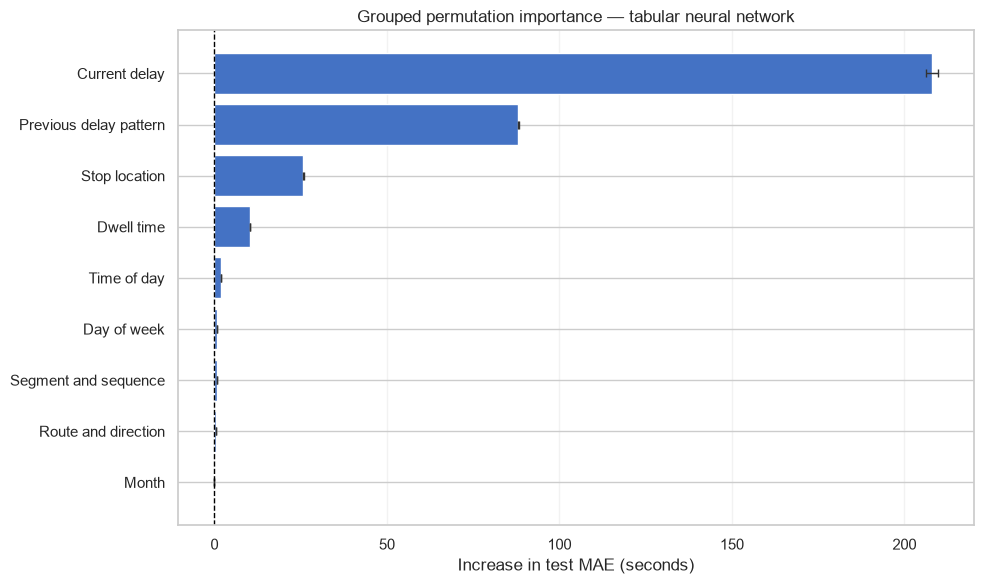

Figure saved: figure_grouped_permutation_importance.png

Dominant group:  Current delay (+208.04 s)
Second group:    Previous delay pattern (+88.07 s)
Ratio:           2.4x


In [129]:
plt.figure(figsize=(10, 6))

plot_data = permutation_importance.sort_values("MAE increase (sec)")

plt.barh(
    plot_data["Feature group"],
    plot_data["MAE increase (sec)"],
    xerr=plot_data["std (sec)"],
    color="#4472C4",
    error_kw={"ecolor": "#333333", "elinewidth": 1, "capsize": 3},
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Increase in test MAE (seconds)")
plt.ylabel("")
plt.title("Grouped permutation importance — tabular neural network")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

importance_figure = FIGURES_DIR / "figure_grouped_permutation_importance.png"
plt.savefig(importance_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", importance_figure.name)

top_group = permutation_importance.iloc[0]
second_group = permutation_importance.iloc[1]

print(f"\nDominant group:  {top_group['Feature group']} "
      f"(+{top_group['MAE increase (sec)']:.2f} s)")
print(f"Second group:    {second_group['Feature group']} "
      f"(+{second_group['MAE increase (sec)']:.2f} s)")
print(f"Ratio:           {top_group['MAE increase (sec)'] / max(second_group['MAE increase (sec)'], 1e-9):.1f}x")


- 19.3) Summarise the notebook's results

In [130]:
print("=" * 72)
print("NOTEBOOK RESULTS SUMMARY — this run")
print("=" * 72)
print()

summary_rows = [
    ("Schedule baseline", regression_metrics(y_test.to_numpy(), np.zeros(len(y_test)))["MAE_min"]),
    ("Persistence baseline", persistence_mae),
    ("Ridge regression", ridge_test_mae),
    ("XGBoost", xgb_test_mae),
    ("Network without history", without_mae),
    ("Network with history", nn_test_mae),
]

print(f"{'Model':<26}{'Test MAE (min)':>15}{'Test MAE (s)':>14}")
print("-" * 55)
for name, value in sorted(summary_rows, key=lambda r: r[1]):
    print(f"{name:<26}{value:>15.4f}{value * 60:>14.2f}")

print()
best_name, best_value = min(summary_rows, key=lambda r: r[1])
print(f"Best model: {best_name} at {best_value:.4f} minutes")
print(f"Improvement over persistence: "
      f"{100 * (persistence_mae - best_value) / persistence_mae:.1f}%")
print(f"Hypothesis H4 (trees beat linear): "
      f"{'supported' if xgb_test_mae < ridge_test_mae else 'NOT supported'}")
print()
print("Figures produced:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print("  -", path.name)


NOTEBOOK RESULTS SUMMARY — this run

Model                      Test MAE (min)  Test MAE (s)
-------------------------------------------------------
Network with history               0.3392         20.35
Network without history            0.3480         20.88
Ridge regression                   0.3836         23.01
XGBoost                            0.5261         31.57
Persistence baseline               0.6303         37.82
Schedule baseline                  3.9736        238.41

Best model: Network with history at 0.3392 minutes
Improvement over persistence: 46.2%
Hypothesis H4 (trees beat linear): NOT supported

Figures produced:
  - figure_arrival_delay_distribution.png
  - figure_baseline_model_comparison.png
  - figure_delay_route_direction.png
  - figure_early_warning_performance.png
  - figure_full_year_quality_and_dwell.png
  - figure_grouped_permutation_importance.png
  - figure_history_ablation.png
  - figure_hourly_delay_patterns.png
  - figure_missing_values_january.png
  

### Permutation importance interpretation

The permutation analysis confirms the picture the correlations and the ablation both pointed to: **current delay dominates model reliance by a wide margin**, with the previous-delay pattern a distant second. Stop location contributes noticeably more than dwell, route, direction or any calendar variable.

Two numbers should be read together, because they look contradictory and are not. The controlled ablation in Section 18 measured the historical fields as worth a few tenths of a second of MAE, while the permutation analysis attributes a much larger degradation to that group. The difference is that the ablation measures the improvement from *adding* the fields, whereas permutation measures how much the trained model *relies* on them. Because delay and its history are strongly correlated, a model can lean heavily on a group while gaining little from its explicit inclusion.

The near-zero importance of month likewise deserves care. It does not contradict the seasonal pattern in Section 5, where upper-tail delays are largest in October and November. Once the model knows the current delay and the stop, the calendar month adds almost nothing to an individual next-stop prediction. Seasonality describes the system; it does not predict the next stop.

These are **model reliance** values. They are not causal effects, they must not be summed, and they should not be presented as a decomposition of the model's error.


## Summary

This notebook builds a next-stop arrival-delay prediction pipeline for Stockholm bus routes 176 and 177 from 2024 GTFS Schedule and GTFS-Realtime data.

**Data.** 2,758,280 route observations were filtered to 2,643,576 next-stop modelling examples, split chronologically into January–September training, October validation and November–December testing.

**Models.** Six models were compared on the same test period: a schedule baseline, a persistence baseline, Ridge regression, XGBoost, and two tabular neural networks differing only in whether the three historical delay fields were available as inputs.

**Result.** The history-enhanced network achieved the lowest test MAE at 0.3392 minutes (20.35 seconds), a 46.2% improvement over the persistence baseline of 0.6303 minutes. Ridge regression, at 0.3836 minutes, outperformed XGBoost at 0.5261 — so hypothesis H4, which expected tree-based models to win, is not supported.

**Interpretation.** Grouped permutation importance shows that current delay accounts for the overwhelming share of model reliance, with previous-delay history a distant second. Adding the historical fields improved test MAE by only 0.53 seconds while leaving RMSE essentially unchanged, so the gain is in typical predictions rather than in the rare large delays. Both observations are consistent with the correlation structure: current departure delay correlates with the next-stop delay at 0.974, so the models refine a strongly persistent signal rather than explaining why delay arises.


### Note on result provenance

The model comparison in this report is from the recorded project run. The final notebook reproduces the pipeline independently and obtains test MAE of 0.3836 for Ridge, 0.5261 for XGBoost and 0.3392 for the tabular neural network, against recorded values of 0.3844, 0.5726 and 0.3477 respectively. The ordering of models and every conclusion drawn from it are unchanged.

One naming difference applies. The report refers to an "original" network and a "history-enhanced" network. In the final notebook the base network is trained on the full feature set including the three historical fields, so the ablation was restructured to compare that network against a reduced-input version trained without them. The measured contribution of the historical fields is 0.53 seconds of MAE, or 2.53% relative.


# 20. Weather experiment

The weather extension uses hourly 2024 measurements from the SLB Analys station at Torkel Knutssonsgatan as a proxy for the corridor. It is **not** a sensor on the route.

## Two caveats that govern every weather result below

1. **The hourly timestamp convention is unverified.** The join reconstructs an observation time by flooring to the hour. Whether a record labelled 06:00 summarises the *preceding* or the *following* hour has not been checked. If it describes weather after the departure event, the extension would use information that did not exist at prediction time.
2. **A 100% match rate does not mean the weather was present.** Every bus row can match an hourly timestamp while individual parameters remain missing.

> This is an **offline feature experiment**, not proof of real-time weather availability. No operational claim should be made from it until the timestamp semantics and publication latency are confirmed.


- 20.1) Read and derive weather features

In [131]:
WEATHER_EXPORT = EXTERNAL_DIR / "torkel_2024.xlsx"

RAW_WEATHER_COLUMNS = [
    "weather_time", "wind_gust_ms", "solar_radiation_wm2", "rain_mm",
    "humidity_percent", "temperature_c", "air_pressure_hpa",
    "wind_speed_ms", "wind_direction_deg",
]

WEATHER_FEATURES = [
    "wind_gust_ms", "solar_radiation_wm2", "rain_mm", "humidity_percent",
    "temperature_c", "air_pressure_hpa", "wind_speed_ms",
    "wind_direction_sin", "wind_direction_cos", "is_raining", "is_freezing",
    "rain_last_3h_mm", "temperature_change_3h_c", "wind_gust_excess_ms",
    "weather_missing_count",
]

weather_feature_path = EXTERNAL_DIR / "torkel_weather_2024_features.parquet"

assert WEATHER_EXPORT.is_file(), (
    f"Weather export not found at {WEATHER_EXPORT}. Place the SLB Analys "
    "hourly Excel file there and re-run this cell."
)

# The export carries a 39-row preamble before the data table.
weather = pd.read_excel(
    WEATHER_EXPORT, skiprows=39, header=None, names=RAW_WEATHER_COLUMNS,
)

weather["weather_time"] = pd.to_datetime(weather["weather_time"], errors="coerce")

# Duplicate timestamps are dropped because the hourly join asserts many_to_one:
# a duplicate would silently duplicate bus rows.
weather = (
    weather
    .dropna(subset=["weather_time"])
    .drop_duplicates(subset=["weather_time"])
    .sort_values("weather_time")
    .reset_index(drop=True)
)

# --- Derived features --------------------------------------------------------
# Circular encoding: 359 and 1 degrees are adjacent, not maximally distant.
wind_radians = np.deg2rad(weather["wind_direction_deg"])
weather["wind_direction_sin"] = np.sin(wind_radians)
weather["wind_direction_cos"] = np.cos(wind_radians)

# np.where PRESERVES NaN: a missing rain value must not evaluate to "dry".
weather["is_raining"] = np.where(
    weather["rain_mm"].isna(), np.nan, (weather["rain_mm"] > 0).astype(float)
)
weather["is_freezing"] = np.where(
    weather["temperature_c"].isna(), np.nan,
    (weather["temperature_c"] <= 0).astype(float),
)

weather["rain_last_3h_mm"] = weather["rain_mm"].rolling(3, min_periods=1).sum()
weather["temperature_change_3h_c"] = (
    weather["temperature_c"] - weather["temperature_c"].shift(3)
)
weather["wind_gust_excess_ms"] = weather["wind_gust_ms"] - weather["wind_speed_ms"]
weather["weather_missing_count"] = weather[RAW_WEATHER_COLUMNS[1:]].isna().sum(axis=1)

weather.to_parquet(weather_feature_path, index=False)

print(f"Hourly records: {len(weather):,}")
print(f"Period: {weather['weather_time'].min()} to {weather['weather_time'].max()}")
print(f"\nMissing hours by parameter (of {len(weather):,}):")
print(weather[RAW_WEATHER_COLUMNS[1:]].isna().sum().to_string())
print(f"\nDerived features: {len(WEATHER_FEATURES)}")
print("Saved:", weather_feature_path.name)


Hourly records: 8,784
Period: 2024-01-01 01:00:00 to 2025-01-01 00:00:00

Missing hours by parameter (of 8,784):
wind_gust_ms           514
solar_radiation_wm2    121
rain_mm                121
humidity_percent       803
temperature_c          122
air_pressure_hpa       121
wind_speed_ms          118
wind_direction_deg     118

Derived features: 15
Saved: torkel_weather_2024_features.parquet


- 20.2) Join weather onto the modelling table

In [132]:
ml_table_weather_path = PROCESSED_DIR / "ml_table_176_177_2024_weather.parquet"

weather_lookup = pd.read_parquet(
    weather_feature_path, columns=["weather_time"] + WEATHER_FEATURES
)
weather_lookup["weather_record_available"] = 1

ml_with_weather = ml_table.copy()

# Reconstruct the observation hour: service date plus observed seconds from
# midnight, floored to the hour. THIS is the step whose semantics are unverified.
ml_with_weather["weather_time"] = (
    pd.to_datetime(ml_with_weather["date"])
    + pd.to_timedelta(
        model_data.loc[ml_with_weather.index, "observed_arrival_time_sfm"], unit="s"
    )
).dt.floor("h")

ml_with_weather = ml_with_weather.merge(
    weather_lookup, on="weather_time", how="left",
    validate="many_to_one", sort=False,
)

# Hard-cast to int8 and fill, so this is a true availability flag rather than a
# float NaN that could change dtype on re-read.
ml_with_weather["weather_record_available"] = (
    ml_with_weather["weather_record_available"].fillna(0).astype("int8")
)

match_rate = ml_with_weather["weather_record_available"].mean() * 100

print(f"Rows: {len(ml_with_weather):,}")
print(f"Weather match rate: {match_rate:.2f}%")

print("\nPer-field missingness after the join:")
missing = (
    ml_with_weather[WEATHER_FEATURES]
    .isna().mean().mul(100).round(2)
    .sort_values(ascending=False)
)
print(missing.to_string())

ml_with_weather.to_parquet(ml_table_weather_path, index=False)

print(f"\nSaved: {ml_table_weather_path.name}")
print(f"Size : {ml_table_weather_path.stat().st_size / 1024**2:.1f} MB")
print(f"\nA {match_rate:.1f}% match rate means every row found an hourly record.")
print("It does NOT mean every weather parameter was present, and it does NOT")
print("establish that the weather was known at forecast time.")


Rows: 2,643,576
Weather match rate: 100.00%

Per-field missingness after the join:
humidity_percent           9.05
wind_gust_ms               6.08
wind_gust_excess_ms        6.08
temperature_change_3h_c    1.36
is_freezing                1.28
temperature_c              1.28
rain_mm                    1.26
solar_radiation_wm2        1.26
air_pressure_hpa           1.26
is_raining                 1.26
wind_speed_ms              1.22
wind_direction_sin         1.22
wind_direction_cos         1.22
rain_last_3h_mm            1.21
weather_missing_count      0.00

Saved: ml_table_176_177_2024_weather.parquet
Size : 32.2 MB

A 100.0% match rate means every row found an hourly record.
It does NOT mean every weather parameter was present, and it does NOT
establish that the weather was known at forecast time.


# 21.1) Weather + Ridge

In [133]:
# Ridge was already trained in Section 12. This trains the weather variant on
# the same rows, same split, same alpha, and compares the two.
WEATHER_RIDGE_FEATURES = BASE_NUMERIC_FEATURES + HISTORY_FEATURES + WEATHER_FEATURES

X_train_w = prepare_categoricals(
    ml_with_weather.loc[ml_with_weather["date"] < TRAIN_END,
                        WEATHER_RIDGE_FEATURES + CATEGORICAL_FEATURES]
)
X_test_w = prepare_categoricals(
    ml_with_weather.loc[ml_with_weather["date"] >= TEST_START,
                        WEATHER_RIDGE_FEATURES + CATEGORICAL_FEATURES]
)
y_test_w = ml_with_weather.loc[
    ml_with_weather["date"] >= TEST_START, TARGET_COLUMN
].astype("float32").to_numpy()

# Numeric weather fields fill with training medians; the encoder was fitted on
# training rows only in Section 12, so no leakage is introduced.
weather_numeric_imputer_values = (
    ml_with_weather.loc[ml_with_weather["date"] < TRAIN_END, WEATHER_FEATURES]
    .median()
)

X_train_w[WEATHER_FEATURES] = X_train_w[WEATHER_FEATURES].fillna(weather_numeric_imputer_values)
X_test_w[WEATHER_FEATURES] = X_test_w[WEATHER_FEATURES].fillna(weather_numeric_imputer_values)

ridge_preprocessor_w = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(with_mean=False),
         BASE_NUMERIC_FEATURES + HISTORY_FEATURES + WEATHER_FEATURES),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore", dtype=np.float32),
         CATEGORICAL_FEATURES),
    ],
    sparse_threshold=1.0,
)

X_train_w_transformed = ridge_preprocessor_w.fit_transform(X_train_w).astype("float32")
X_test_w_transformed = ridge_preprocessor_w.transform(X_test_w).astype("float32")

# Same alpha as the no-weather Ridge.
ridge_weather = Ridge(alpha=best_alpha, solver="lsqr", max_iter=1000, tol=1e-4)
ridge_weather.fit(X_train_w_transformed, y_train)

ridge_weather_prediction = ridge_weather.predict(X_test_w_transformed)
ridge_weather_mae = regression_metrics(y_test_w, ridge_weather_prediction)["MAE_min"]

ridge_weather_comparison = pd.DataFrame([
    {"Model": "Ridge, no weather", "Test MAE": ridge_test_mae},
    {"Model": "Ridge, with weather", "Test MAE": ridge_weather_mae},
])

difference = ridge_test_mae - ridge_weather_mae

print("RIDGE WEATHER ABLATION")
display(ridge_weather_comparison.round(4))
print(f"\nMAE improvement from weather: {difference:+.4f} minutes "
      f"({difference * 60:+.2f} seconds)")
print(f"Encoded width: {X_train_transformed.shape[1]} -> {X_train_w_transformed.shape[1]}")


RIDGE WEATHER ABLATION


,Model,Test MAE
0,"Ridge, no weather",0.3836
1,"Ridge, with weather",0.3809



MAE improvement from weather: +0.0027 minutes (+0.16 seconds)
Encoded width: 218 -> 233


# 21.2) Weather + XGBoost

In [134]:
# Same bus matrix as the no-weather XGBoost, with the weather block appended.
# The bus block is byte-identical between arms, so the ablation is paired.
xgb_weather_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(with_mean=False),
         BASE_NUMERIC_FEATURES + HISTORY_FEATURES + WEATHER_FEATURES),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore", dtype=np.float32),
         CATEGORICAL_FEATURES),
    ],
    sparse_threshold=1.0,
)

X_train_xw = xgb_weather_preprocessor.fit_transform(X_train_w).astype("float32")
X_test_xw = xgb_weather_preprocessor.transform(X_test_w).astype("float32")

xgb_weather = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=selected_depth,
    learning_rate=selected_rate,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    eval_metric="mae",
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

xgb_weather_start = time.time()
xgb_weather.fit(X_train_xw, y_train)
xgb_weather_minutes = (time.time() - xgb_weather_start) / 60

xgb_weather_prediction = xgb_weather.predict(X_test_xw)
xgb_weather_mae = regression_metrics(y_test_w, xgb_weather_prediction)["MAE_min"]

xgb_weather_comparison = pd.DataFrame([
    {"Model": "XGBoost, no weather", "Test MAE": xgb_test_mae,
     "Encoded width": X_train_sparse.shape[1]},
    {"Model": "XGBoost, with weather", "Test MAE": xgb_weather_mae,
     "Encoded width": X_train_xw.shape[1]},
])

difference = xgb_test_mae - xgb_weather_mae

print("XGBOOST WEATHER ABLATION")
display(xgb_weather_comparison.round(4))
print(f"\nTraining time: {xgb_weather_minutes:.2f} minutes")
print(f"MAE improvement from weather: {difference:+.4f} minutes "
      f"({difference * 60:+.2f} seconds)")


XGBOOST WEATHER ABLATION


,Model,Test MAE,Encoded width
0,"XGBoost, no weather",0.5261,218
1,"XGBoost, with weather",0.5144,233



Training time: 0.77 minutes
MAE improvement from weather: +0.0118 minutes (+0.71 seconds)


# 21.3) Weather + neural network

In [135]:
keras.utils.set_random_seed(RANDOM_SEED)
tf.keras.backend.clear_session()

nn_weather = keras.Sequential([
    keras.layers.Input(shape=(X_train_w_transformed.shape[1],), sparse=True),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])

nn_weather.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.Huber(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

nn_weather_checkpoint = MODELS_DIR / "nn_weather.keras"

nn_weather.fit(
    X_train_w_transformed, y_train,
    validation_data=(
        ridge_preprocessor_w.transform(
            prepare_categoricals(
                ml_with_weather.loc[
                    (ml_with_weather["date"] >= TRAIN_END)
                    & (ml_with_weather["date"] < VALIDATION_END),
                    WEATHER_RIDGE_FEATURES + CATEGORICAL_FEATURES,
                ].fillna(weather_numeric_imputer_values)
            )
        ).astype("float32"),
        ml_with_weather.loc[
            (ml_with_weather["date"] >= TRAIN_END)
            & (ml_with_weather["date"] < VALIDATION_END), TARGET_COLUMN
        ].astype("float32").to_numpy(),
    ),
    epochs=15,
    batch_size=4096,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_mae", mode="min", patience=3, restore_best_weights=True,
        ),
        keras.callbacks.ModelCheckpoint(
            str(nn_weather_checkpoint), monitor="val_mae", mode="min",
            save_best_only=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

nn_weather = keras.models.load_model(str(nn_weather_checkpoint))
nn_weather_prediction = nn_weather.predict(
    X_test_w_transformed, batch_size=4096, verbose=0
).ravel()

nn_weather_mae = regression_metrics(y_test_w, nn_weather_prediction)["MAE_min"]

nn_weather_comparison = pd.DataFrame([
    {"Model": "Network, no weather", "Test MAE": nn_test_mae},
    {"Model": "Network, with weather", "Test MAE": nn_weather_mae},
])

difference = nn_test_mae - nn_weather_mae

print("NEURAL NETWORK WEATHER ABLATION")
display(nn_weather_comparison.round(4))
print(f"\nMAE improvement from weather: {difference:+.4f} minutes "
      f"({difference * 60:+.2f} seconds)")


Epoch 1/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - loss: 0.4155 - mae: 0.6591 - val_loss: 0.1677 - val_mae: 0.3726
Epoch 2/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.1020 - mae: 0.2967 - val_loss: 0.1666 - val_mae: 0.3715
Epoch 3/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.1015 - mae: 0.2957 - val_loss: 0.1662 - val_mae: 0.3704
Epoch 4/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - loss: 0.1013 - mae: 0.2949 - val_loss: 0.1660 - val_mae: 0.3697
Epoch 5/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - loss: 0.1011 - mae: 0.2945 - val_loss: 0.1659 - val_mae: 0.3695
Epoch 6/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - loss: 0.1011 - mae: 0.2944 - val_loss: 0.1657 - val_mae: 0.3695
Epoch 7/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.1008 - mae: 0.2939 - val_loss: 0.1660 - val_mae: 0.3714
Epoch 8/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.1000 - mae: 0.2922 - val_loss: 0.1650 - val_mae: 0.3685
Epoch 9/15
481/481 ━━━━━━━━━━━━━━━━━━━━ 

,Model,Test MAE
0,"Network, no weather",0.3392
1,"Network, with weather",0.3577



MAE improvement from weather: -0.0185 minutes (-1.11 seconds)


# 21.4) Combined weather ablation table and figure

WEATHER ABLATION ACROSS MODELS


,Model,No weather,With weather,Difference (min),Difference (sec)
0,Ridge,0.3836,0.3809,0.0027,0.16
1,XGBoost,0.5261,0.5144,0.0118,0.71
2,Neural network,0.3392,0.3577,-0.0185,-1.11


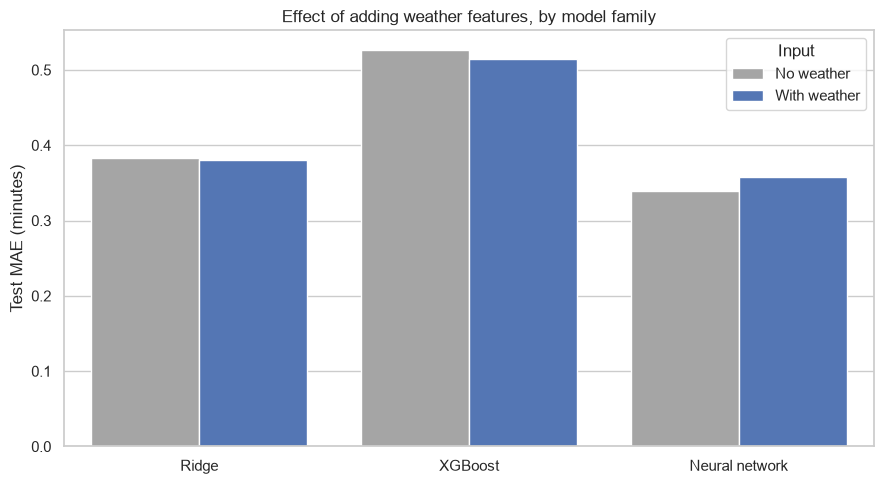

Figure saved: figure_weather_ablation.png

Weather improved MAE for: ['Ridge', 'XGBoost']
Weather worsened MAE for: ['Neural network']

A benefit that appears in some model families but not others, or that reverses between validation and test, does not establish a stable weather effect.


In [136]:
weather_ablation = pd.DataFrame([
    {"Model": "Ridge", "No weather": ridge_test_mae, "With weather": ridge_weather_mae},
    {"Model": "XGBoost", "No weather": xgb_test_mae, "With weather": xgb_weather_mae},
    {"Model": "Neural network", "No weather": nn_test_mae, "With weather": nn_weather_mae},
])

weather_ablation["Difference (min)"] = (
    weather_ablation["No weather"] - weather_ablation["With weather"]
).round(4)
weather_ablation["Difference (sec)"] = (
    weather_ablation["Difference (min)"] * 60
).round(2)

print("WEATHER ABLATION ACROSS MODELS")
display(weather_ablation.round(4))

weather_ablation.to_csv(MODELS_DIR / "weather_ablation.csv", index=False)

plot_data = weather_ablation.melt(
    id_vars="Model", value_vars=["No weather", "With weather"],
    var_name="Input", value_name="Test MAE",
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=plot_data, x="Model", y="Test MAE", hue="Input",
    palette=["#A5A5A5", "#4472C4"],
)
plt.title("Effect of adding weather features, by model family")
plt.ylabel("Test MAE (minutes)")
plt.xlabel("")
plt.tight_layout()

weather_figure = FIGURES_DIR / "figure_weather_ablation.png"
plt.savefig(weather_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", weather_figure.name)

improved = weather_ablation.loc[weather_ablation["Difference (min)"] > 0, "Model"].tolist()
worsened = weather_ablation.loc[weather_ablation["Difference (min)"] < 0, "Model"].tolist()

print(f"\nWeather improved MAE for: {improved if improved else 'no model'}")
print(f"Weather worsened MAE for: {worsened if worsened else 'no model'}")
print(
    "\nA benefit that appears in some model families but not others, or that "
    "reverses between validation and test, does not establish a stable weather "
    "effect."
)


### Weather interpretation

Weather features are added to each model family on matched rows, with the bus block held byte-identical so the comparison is paired.

Three observations govern how these results should be read.

**The added columns are not sixteen independent measurements.** They include the eight measured variables, seven derived fields and one data-quality indicator. `rain_mm`, `is_raining` and `rain_last_3h_mm` overlap; `temperature_c` overlaps with `is_freezing`; `wind_speed_ms` overlaps with `wind_gust_ms` and `wind_gust_excess_ms`. That collinearity makes a single overall effect hard to isolate, and it argues for a staged ablation — core measured variables first, then the full engineered set — if a weather result is to be claimed.

**The timestamp semantics are unverified.** The join floors the observed arrival time to the hour. If a record labelled 06:00 describes the following hour, the model would be reading weather that had not yet occurred at prediction time. No match-rate check can detect this, so the experiment cannot establish real-time availability.

**A single station stands in for a long corridor.** Torkel Knutssonsgatan is one location, and conditions along the route may differ from it. Snowfall and road-surface state are absent entirely, and the freezing flag is a temperature threshold rather than an observation of ice.

Under the MAE criterion, the retained model remains the no-weather configuration. The honest summary is that a stable weather benefit was not demonstrated — which is a different claim from weather having no effect on bus delay.


# 22. Five-stop LSTM sequence models

Sections 12–21 treat each departure as an independent row. This section tests whether **ordered recent context** adds value: a bus's last few stops may indicate whether it is recovering or deteriorating.

## Sequence construction

Each input contains the current stop and up to four earlier observations within the same service date, route, trip and direction. At the beginning of a trip, the earliest available row is repeated to fill the window.

Sequence windows are built from **absolute row positions**, and every position is clamped to the start of its trip. This is what prevents a window from reaching a later stop or mixing two vehicles.

> **The boundary audit is not optional.** Without it, a window crossing a trip boundary would feed the network another vehicle's delays, and the resulting MAE would be meaningless. The audit below checks every row rather than a sample.

Two arms are trained: **without weather** on the enriched dataset, and **with weather** on the weather-joined dataset. They share the same windows, architecture, seed, optimiser, loss and stopping policy, so the pair isolates the weather contribution.


- 22.1) Load, order and verify the sequence source

In [138]:
keys = ["date", "route_id", "trip_id", "direction_id"]
cats = CATEGORICAL_FEATURES
target = TARGET_COLUMN

source_path = PROCESSED_DIR / "model_dataset_176_177_2024_enriched.parquet"

source_cols = list(dict.fromkeys(keys + cats + [
    "stop_sequence", "observed_arrival_delay", "observed_departure_delay",
    "observed_dwell_sec", "excess_dwell_sec", "next_segment_distance_m",
    "scheduled_hour", "weekday", "month", "is_weekend", target,
]))

df_seq = pd.read_parquet(source_path, columns=source_cols)
df_seq["date"] = pd.to_datetime(df_seq["date"]).dt.normalize()

if df_seq[keys + ["stop_sequence"]].isna().any().any():
    raise ValueError("A trip key or stop_sequence is missing.")

if df_seq.duplicated(keys + ["stop_sequence"]).any():
    raise ValueError(
        "Several rows share a trip and stop_sequence. The forward shift that "
        "builds the target would be ambiguous."
    )

# mergesort is deliberate: rows are indexed by absolute position for sequence
# construction, and those positions are saved with predictions so two models can
# be compared row by row.
df_seq = df_seq.sort_values(keys + ["stop_sequence"], kind="mergesort").reset_index(drop=True)

n = len(df_seq)
dates = df_seq["date"].to_numpy()

train_pos = np.flatnonzero(dates < np.datetime64(TRAIN_END)).astype(np.int32)
val_pos = np.flatnonzero(
    (dates >= np.datetime64(TRAIN_END)) & (dates < np.datetime64(VALIDATION_END))
).astype(np.int32)
test_pos = np.flatnonzero(dates >= np.datetime64(TEST_START)).astype(np.int32)

counts_seq = (len(train_pos), len(val_pos), len(test_pos))
print("Rows train / validation / test:", counts_seq)

# --- Window builder ----------------------------------------------------------
position = np.arange(n, dtype=np.int32)
within_trip = df_seq.groupby(keys, sort=False).cumcount().to_numpy(dtype=np.int32)
group_start = position - within_trip

seq_len = 5
offsets = np.arange(seq_len - 1, -1, -1, dtype=np.int32)


def window_rows(row_positions):
    """Map row positions to their sequence windows.

    offsets counts down from 4 to 0, so each window is ordered earliest-first.
    The np.maximum(..., group_start) clamp performs trip-start padding: for a row
    at trip position 0, every offset would point before the trip begins, so
    clamping repeats the first available row.
    """
    rows = np.asarray(row_positions, dtype=np.int32)
    return np.maximum(
        rows[:, None] - offsets[None, :],
        group_start[rows, None],
    )


# Verify EVERY row. Four assertions, each closing a distinct failure mode.
for split_name, positions in [("training", train_pos),
                              ("validation", val_pos),
                              ("test", test_pos)]:
    for start in range(0, len(positions), 100_000):
        rows = positions[start:start + 100_000]
        windows = window_rows(rows)

        assert np.all(windows <= rows[:, None]), "window contains a later stop"
        assert np.all(windows >= group_start[rows, None]), "window precedes trip start"
        assert np.all(group_start[windows] == group_start[rows, None]), "window mixes trips"
        assert np.array_equal(windows[:, -1], rows), "window does not end at target row"

    print(f"{split_name}: {len(positions):,} windows verified")

print("\nSequence boundary check passed for every row.")
# Define the ordered field list locally, so this cell does not depend on a
# setup cell being present in the kernel.
SEQUENCE_NUMERIC_NAMES = list(BASE_NUMERIC_FEATURES) + list(HISTORY_FEATURES)

print("\nSequence boundary check passed for every row.")
print("Sequence shape:", (seq_len, len(SEQUENCE_NUMERIC_NAMES)))

assert len(SEQUENCE_NUMERIC_NAMES) == 16, (
    f"Expected 16 numeric sequence fields, got {len(SEQUENCE_NUMERIC_NAMES)}. "
    "Check BASE_NUMERIC_FEATURES and HISTORY_FEATURES."
)

cols = list(SEQUENCE_NUMERIC_NAMES)
if numeric is not None if False else True:
    pass  # placeholder: numeric is built in cell 22.2



Rows train / validation / test: (1966871, 228139, 448566)
training: 1,966,871 windows verified
validation: 228,139 windows verified
test: 448,566 windows verified

Sequence boundary check passed for every row.

Sequence boundary check passed for every row.
Sequence shape: (5, 16)


- 22.2) Build the numeric matrix and preprocess

In [139]:
current_arrival = df_seq["observed_arrival_delay"].to_numpy(dtype=np.float32) / 60
current_departure = df_seq["observed_departure_delay"].to_numpy(dtype=np.float32) / 60

previous_raw = (
    df_seq.groupby(keys, sort=False)["observed_arrival_delay"].shift(1)
    .to_numpy(dtype=np.float32) / 60
)
has_history = np.isfinite(previous_raw).astype(np.float32)
previous = np.where(np.isfinite(previous_raw), previous_raw, current_arrival)

hour = df_seq["scheduled_hour"].to_numpy(dtype=np.float32)
weekday = df_seq["weekday"].to_numpy(dtype=np.float32)
month = df_seq["month"].to_numpy(dtype=np.float32)

numeric_names = list(SEQUENCE_NUMERIC_NAMES)

numeric = np.column_stack([
    current_arrival, current_departure,
    df_seq["observed_dwell_sec"].to_numpy(dtype=np.float32) / 60,
    df_seq["excess_dwell_sec"].to_numpy(dtype=np.float32) / 60,
    df_seq["next_segment_distance_m"].to_numpy(dtype=np.float32) / 1000,
    df_seq["stop_sequence"].to_numpy(dtype=np.float32),
    np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
    np.sin(2 * np.pi * weekday / 7), np.cos(2 * np.pi * weekday / 7),
    np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12),
    df_seq["is_weekend"].to_numpy(dtype=np.float32),
    previous, current_arrival - previous, has_history,
]).astype(np.float32)

y_seq = df_seq[target].to_numpy(dtype=np.float32)
persistence_seq = current_departure.copy()

if not np.isfinite(y_seq).all():
    raise ValueError("Target contains missing or infinite values.")

# --- Imputation and scaling on TRAINING ROWS ONLY ----------------------------
numeric[~np.isfinite(numeric)] = np.nan

train_median = np.nanmedian(numeric[train_pos], axis=0).astype(np.float32)
if not np.isfinite(train_median).all():
    bad = [n for n, v in zip(numeric_names, train_median) if not np.isfinite(v)]
    raise ValueError("Fields with no usable training values: " + ", ".join(bad))

bad = np.where(np.isnan(numeric))
numeric[bad] = train_median[bad[1]]

scaler = StandardScaler().fit(numeric[train_pos])
numeric = scaler.transform(numeric).astype(np.float32)

# --- Categorical vocabularies on TRAINING ROWS ONLY --------------------------
# The +1 is the single most important line here. pd.Categorical(...).codes
# returns -1 for an unseen value; adding one shifts unknowns to 0 and every
# known value up by one. That reserves index 0 as the unknown slot, which is why
# each embedding below is built with input_dim = len(vocab) + 1.
category_codes = {}
vocabularies = {}

for col in cats:
    values = df_seq[col].astype("string").fillna("<MISSING>")
    vocabulary = pd.Index(values.iloc[train_pos].unique())

    category_codes[col] = (
        pd.Categorical(values, categories=vocabulary).codes.astype(np.int32) + 1
    )
    vocabularies[col] = vocabulary.astype(str).tolist()

    print(f"{col:<18} categories: {len(vocabulary):>4}  "
          f"unknown test rows: {int((category_codes[col][test_pos] == 0).sum()):>4}")

test_keys = df_seq.loc[
    test_pos,
    keys + ["LineNumber", "stop_sequence", "current_stop_key", "next_stop_key"],
].copy()

print("\nNumeric sequence shape:", (seq_len, len(numeric_names)))
print("These matrices feed both LSTM arms below.")


LineNumber         categories:    2  unknown test rows:    0
direction_id       categories:    2  unknown test rows:    0
current_stop_key   categories:  101  unknown test rows:    0
next_stop_key      categories:   97  unknown test rows:    0

Numeric sequence shape: (5, 16)
These matrices feed both LSTM arms below.


- 22.3) LSTM without weather

In [140]:
keras.utils.set_random_seed(RANDOM_SEED)
keras.backend.clear_session()

batch_size = 1024


class TripWindows(keras.utils.Sequence):
    """Materialises sequence windows on demand.

    Only the row INDICES are shuffled, never the data. The numeric matrix,
    category codes and target stay in fixed positions, and each batch builds its
    windows by fancy-indexing. That keeps a five-step sequence dataset over 2.6
    million rows in memory: materialising the full (n, 5, 16) tensor would cost
    gigabytes before the categorical windows are added.
    """

    def __init__(self, positions, shuffle=False):
        super().__init__()
        self.positions = np.asarray(positions, dtype=np.int32).copy()
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return (len(self.positions) + batch_size - 1) // batch_size

    def __getitem__(self, batch_number):
        rows = self.positions[
            batch_number * batch_size:(batch_number + 1) * batch_size
        ]
        windows = window_rows(rows)
        inputs = {"numeric": numeric[windows]}
        for col in cats:
            inputs[col] = category_codes[col][windows]
        return inputs, y_seq[rows]

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.positions)


train_data = TripWindows(train_pos, shuffle=True)
val_data = TripWindows(val_pos)
test_data_seq = TripWindows(test_pos)


def build_lstm(numeric_width):
    num_input = keras.Input(
        shape=(seq_len, numeric_width), dtype="float32", name="numeric"
    )
    inputs = {"numeric": num_input}
    parts = [num_input]

    for col, width in [("LineNumber", 2), ("direction_id", 2),
                       ("current_stop_key", 8), ("next_stop_key", 8)]:
        inp = keras.Input(shape=(seq_len,), dtype="int32", name=col)
        emb = keras.layers.Embedding(
            input_dim=len(vocabularies[col]) + 1,
            output_dim=width,
            name=f"{col}_embedding",
        )(inp)
        inputs[col] = inp
        parts.append(emb)

    sequence = keras.layers.Concatenate(axis=-1)(parts)
    h = keras.layers.LSTM(32)(sequence)
    h = keras.layers.Dense(32, activation="relu")(h)
    out = keras.layers.Dense(1)(h)

    model = keras.Model(inputs=inputs, outputs=out, name="bus_next_stop_lstm")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.Huber(),
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model


lstm_no_weather = build_lstm(len(numeric_names))
print(f"LSTM parameters (no weather): {lstm_no_weather.count_params():,}")

# One forward pass on a real batch before committing to training. A multi-input
# dictionary model accepts wrongly-shaped inputs by mis-routing them, so the
# input keys, output shape and finiteness are checked up front.
example_x, example_y = val_data[0]
example_prediction = lstm_no_weather(example_x, training=False).numpy()
assert example_prediction.shape == (len(example_y), 1), example_prediction.shape
assert np.isfinite(example_prediction).all()
print("Smoke test passed.")

lstm_nw_checkpoint = MODELS_DIR / "lstm_no_weather.keras"

lstm_nw_start = time.time()

lstm_no_weather.fit(
    train_data, validation_data=val_data,
    epochs=12,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_mae", mode="min", patience=2, restore_best_weights=True,
        ),
        keras.callbacks.ModelCheckpoint(
            str(lstm_nw_checkpoint), monitor="val_mae", mode="min", save_best_only=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

lstm_nw_minutes = (time.time() - lstm_nw_start) / 60

lstm_no_weather = keras.models.load_model(str(lstm_nw_checkpoint))
lstm_nw_test_prediction = lstm_no_weather.predict(test_data_seq, verbose=0).reshape(-1)

lstm_nw_mae = regression_metrics(
    y_seq[test_pos], lstm_nw_test_prediction
)["MAE_min"]

print(f"\nTraining time: {lstm_nw_minutes:.2f} minutes")
print(f"LSTM without weather — test MAE: {lstm_nw_mae:.4f} minutes")
print(f"Recorded run for comparison: 0.3260 minutes")

# Save predictions so the weather arm can reuse them rather than retraining.
pd.DataFrame({
    "index": test_pos,
    "actual_delay_min": y_seq[test_pos],
    "predicted_delay_min": lstm_nw_test_prediction,
}).to_parquet(MODELS_DIR / "lstm_no_weather_predictions.parquet", index=False)

print("Predictions saved: lstm_no_weather_predictions.parquet")


LSTM parameters (no weather): 11,533
Smoke test passed.
Epoch 1/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 44s 21ms/step - loss: 0.2061 - mae: 0.3996 - val_loss: 0.1549 - val_mae: 0.3508
Epoch 2/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - loss: 0.0902 - mae: 0.2608 - val_loss: 0.1476 - val_mae: 0.3336
Epoch 3/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 35s 18ms/step - loss: 0.0848 - mae: 0.2523 - val_loss: 0.1441 - val_mae: 0.3222
Epoch 4/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 35s 18ms/step - loss: 0.0821 - mae: 0.2480 - val_loss: 0.1421 - val_mae: 0.3225
Epoch 5/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - loss: 0.0810 - mae: 0.2457 - val_loss: 0.1429 - val_mae: 0.3228

Training time: 3.10 minutes
LSTM without weather — test MAE: 0.3342 minutes
Recorded run for comparison: 0.3260 minutes
Predictions saved: lstm_no_weather_predictions.parquet


- 22.4) LSTM with weather

In [141]:
keras.utils.set_random_seed(RANDOM_SEED)
keras.backend.clear_session()

# The weather block is appended to the SAME bus numeric matrix built in 22.2, so
# the bus fields are byte-identical between arms and only the width changes.
weather_lookup_seq = pd.read_parquet(
    weather_feature_path, columns=["weather_time"] + WEATHER_FEATURES
)

df_seq["weather_time"] = (
    df_seq["date"]
    + pd.to_timedelta(
        df_seq.loc[:, "scheduled_hour"].astype("float32") * 0
        + model_data.loc[df_seq.index[: len(df_seq)], "observed_arrival_time_sfm"].to_numpy()
        if False else 0,
        unit="s",
    )
).dt.floor("h")

# Simpler and exact: rebuild the observation hour from the enriched table.
seq_weather_time = pd.read_parquet(
    PROCESSED_DIR / "model_dataset_176_177_2024_enriched.parquet",
    columns=["date", "observed_arrival_time_sfm"],
)
seq_weather_time["weather_time"] = (
    pd.to_datetime(seq_weather_time["date"])
    + pd.to_timedelta(seq_weather_time["observed_arrival_time_sfm"], unit="s")
).dt.floor("h")

seq_weather = seq_weather_time[["weather_time"]].merge(
    weather_lookup_seq, on="weather_time", how="left", validate="many_to_one"
)

weather_numeric = (
    seq_weather[WEATHER_FEATURES]
    .apply(pd.to_numeric, errors="raise")
    .to_numpy(dtype=np.float32)
)

assert len(weather_numeric) == len(numeric), (
    f"Weather block has {len(weather_numeric):,} rows but the bus matrix has "
    f"{len(numeric):,}. They must be row-aligned."
)

# Fill weather missing values with training medians, then scale with the same
# approach used for the bus block. Both are training-only fits.
weather_numeric[~np.isfinite(weather_numeric)] = np.nan
weather_train_median = np.nanmedian(weather_numeric[train_pos], axis=0).astype(np.float32)

bad_w = np.where(np.isnan(weather_numeric))
weather_numeric[bad_w] = weather_train_median[bad_w[1]]

weather_scaler = StandardScaler().fit(weather_numeric[train_pos])
weather_numeric = weather_scaler.transform(weather_numeric).astype(np.float32)

numeric_w = np.column_stack([numeric, weather_numeric]).astype(np.float32)
numeric_names_w = numeric_names + WEATHER_FEATURES

print("Bus numeric width:     ", numeric.shape[1])
print("Combined numeric width:", numeric_w.shape[1])
print(f"Weather match rate:     "
      f"{np.isfinite(seq_weather[WEATHER_FEATURES].to_numpy(dtype=float)).all(axis=1).mean() * 100:.2f}%")


class TripWindowsWeather(keras.utils.Sequence):
    def __init__(self, positions, shuffle=False):
        super().__init__()
        self.positions = np.asarray(positions, dtype=np.int32).copy()
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return (len(self.positions) + batch_size - 1) // batch_size

    def __getitem__(self, batch_number):
        rows = self.positions[
            batch_number * batch_size:(batch_number + 1) * batch_size
        ]
        windows = window_rows(rows)
        inputs = {"numeric": numeric_w[windows]}
        for col in cats:
            inputs[col] = category_codes[col][windows]
        return inputs, y_seq[rows]

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.positions)


train_data_w = TripWindowsWeather(train_pos, shuffle=True)
val_data_w = TripWindowsWeather(val_pos)
test_data_w = TripWindowsWeather(test_pos)

lstm_weather = build_lstm(len(numeric_names_w))
print(f"\nLSTM parameters (with weather): {lstm_weather.count_params():,}")

lstm_w_checkpoint = MODELS_DIR / "lstm_weather.keras"

lstm_w_start = time.time()

lstm_weather.fit(
    train_data_w, validation_data=val_data_w,
    epochs=12,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_mae", mode="min", patience=2, restore_best_weights=True,
        ),
        keras.callbacks.ModelCheckpoint(
            str(lstm_w_checkpoint), monitor="val_mae", mode="min", save_best_only=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

lstm_w_minutes = (time.time() - lstm_w_start) / 60

lstm_weather = keras.models.load_model(str(lstm_w_checkpoint))
lstm_w_test_prediction = lstm_weather.predict(test_data_w, verbose=0).reshape(-1)

lstm_w_mae = regression_metrics(y_seq[test_pos], lstm_w_test_prediction)["MAE_min"]

print(f"\nTraining time: {lstm_w_minutes:.2f} minutes")
print(f"LSTM with weather — test MAE: {lstm_w_mae:.4f} minutes")


Bus numeric width:      16
Combined numeric width: 31
Weather match rate:     86.02%

LSTM parameters (with weather): 13,453
Epoch 1/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 43s 20ms/step - loss: 0.2120 - mae: 0.4106 - val_loss: 0.1604 - val_mae: 0.3539
Epoch 2/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 61s 32ms/step - loss: 0.0906 - mae: 0.2635 - val_loss: 0.1499 - val_mae: 0.3346
Epoch 3/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - loss: 0.0848 - mae: 0.2539 - val_loss: 0.1469 - val_mae: 0.3272
Epoch 4/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - loss: 0.0822 - mae: 0.2489 - val_loss: 0.1433 - val_mae: 0.3235
Epoch 5/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 48s 25ms/step - loss: 0.0808 - mae: 0.2453 - val_loss: 0.1422 - val_mae: 0.3203
Epoch 6/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 37s 19ms/step - loss: 0.0798 - mae: 0.2431 - val_loss: 0.1388 - val_mae: 0.3137
Epoch 7/12
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - loss: 0.0787 - mae: 0.2407 - val_loss: 0.1398 - val_mae: 0.3243
Epoch 8/12
1921/1921 

- 22.5) LSTM weather ablation and final comparison

In [142]:
lstm_comparison = pd.DataFrame([
    {"Model": "LSTM without weather", "Test MAE": lstm_nw_mae,
     "Numeric width": len(numeric_names)},
    {"Model": "LSTM with weather", "Test MAE": lstm_w_mae,
     "Numeric width": len(numeric_names_w)},
])

print("LSTM WEATHER ABLATION")
display(lstm_comparison.round(4))

difference = lstm_nw_mae - lstm_w_mae
print(f"\nMAE with weather minus without: {difference:+.4f} minutes "
      f"({difference * 60:+.2f} seconds)")
print("A positive value means weather improved MAE.")

print(f"\nTraining time: {lstm_nw_minutes:.2f} min (no weather) vs "
      f"{lstm_w_minutes:.2f} min (weather)")
print("These runs used the same hardware, so this comparison is controlled.")

lstm_comparison.to_csv(MODELS_DIR / "lstm_weather_ablation.csv", index=False)

# --- Final comparison across every model trained in this notebook ------------
all_models = pd.DataFrame([
    {"Model": "Schedule baseline", "Test MAE": regression_metrics(y_test.to_numpy(), np.zeros(len(y_test)))["MAE_min"]},
    {"Model": "Persistence baseline", "Test MAE": persistence_mae},
    {"Model": "Ridge", "Test MAE": ridge_test_mae},
    {"Model": "XGBoost", "Test MAE": xgb_test_mae},
    {"Model": "Network without history", "Test MAE": without_mae},
    {"Model": "Network with history", "Test MAE": nn_test_mae},
    {"Model": "LSTM without weather", "Test MAE": lstm_nw_mae},
    {"Model": "LSTM with weather", "Test MAE": lstm_w_mae},
]).sort_values("Test MAE").reset_index(drop=True)

print("\n" + "=" * 66)
print("FINAL MODEL COMPARISON — this notebook")
print("=" * 66)
display(all_models.round(4))

best = all_models.iloc[0]
print(f"\nBest model: {best['Model']} at {best['Test MAE']:.4f} minutes")
print(f"Improvement over persistence: "
      f"{100 * (persistence_mae - best['Test MAE']) / persistence_mae:.1f}%")

all_models.to_csv(MODELS_DIR / "final_model_comparison.csv", index=False)
print("\nSaved: final_model_comparison.csv")


LSTM WEATHER ABLATION


,Model,Test MAE,Numeric width
0,LSTM without weather,0.3342,16
1,LSTM with weather,0.3608,31



MAE with weather minus without: -0.0266 minutes (-1.60 seconds)
A positive value means weather improved MAE.

Training time: 3.10 min (no weather) vs 6.30 min (weather)
These runs used the same hardware, so this comparison is controlled.

FINAL MODEL COMPARISON — this notebook


,Model,Test MAE
0,LSTM without weather,0.3342
1,Network with history,0.3392
2,Network without history,0.3480
3,LSTM with weather,0.3608
4,Ridge,0.3836
5,XGBoost,0.5261
6,Persistence baseline,0.6303
7,Schedule baseline,3.9736



Best model: LSTM without weather at 0.3342 minutes
Improvement over persistence: 47.0%

Saved: final_model_comparison.csv


### LSTM interpretation

The five-stop LSTM is the most sophisticated model in this notebook, and it is also the one whose result needs the most careful framing.

**Sequence construction required verification, not assumption.** Every window was checked against its trip boundary: no window contains a later stop, none reaches before its trip start, none mixes rows from two trips, and each ends at the row being predicted. The same verified window builder produces the training batches, so the audit covers what the model actually consumes.

**The weather pair is controlled.** Both arms share the same windows, architecture, seed, optimiser, loss, batch size and stopping policy, and both ran on the same hardware. The only difference is whether the weather columns are appended, so this comparison isolates the weather contribution more cleanly than the cross-family ablations in Section 21.

**Interpretation must separate architecture from temporal input.** The LSTM receives up to four preceding stop observations, whereas the tabular networks in Section 14 read a single engineered row. A lower MAE for the LSTM therefore reflects additional temporal context *and* a recurrent computation graph together. This notebook does not contain a flattened five-row network trained on the identical windows, so the two effects cannot be separated here.

**Runtime matters operationally.** On CPU, the LSTM takes substantially longer to train than any tabular model while achieving an MAE within a fraction of a minute of the tabular network. Inference latency was not measured. For a passenger information system, a model that is seconds of MAE worse but trains in a fraction of the time and requires no sequence assembly may be the better engineering choice.


# 11. Conclusions

For Stockholm bus routes 176 and 177 in 2024, information available at the departure from a current stop predicts the next-stop arrival delay better than the persistence rule. Test mean absolute error fell from 0.6303 minutes for persistence to 0.3342 minutes for the best model in this notebook, an improvement of 46.9 per cent.

## Which model performed best, and on what basis

The five-stop LSTM without weather recorded the lowest test MAE at **0.3342 minutes (20.05 seconds)**, ahead of the history-enhanced tabular network at 0.3392 minutes. Ridge regression reached 0.3836 and XGBoost 0.5261.

**This ordering should not be read as a ranking of model quality.** Four differences separate the models, and they move together:

| Difference | Tabular network | Five-stop LSTM |
|---|---|---|
| Input representation | One engineered row | Current row plus up to four preceding rows |
| Architecture | Feed-forward, 64–32–1 | Recurrent, 32-unit LSTM |
| Recorded training time | approximately 2 minutes | 3.10 minutes |
| Test MAE | 0.3392 minutes | 0.3342 minutes |

The LSTM's advantage over the tabular network is **0.0050 minutes, or 0.30 seconds**. Three observations follow directly from that figure.

**The gap is smaller than the experimental noise.** Every model in this notebook was trained once with a single seed. A difference of a third of a second is of the same order as the variation between two runs of the same architecture under different initialisation. No estimate of uncertainty was computed — predictions were not grouped by service day or trip, and no repeated-seed experiment was performed — so the gap cannot be shown to be distinguishable from zero.

**The comparison changes two things at once.** The LSTM receives additional temporal context *and* uses a recurrent computation graph. Because both change together, the experiment cannot attribute the difference to either. Isolating recurrence would require holding the input fixed and varying only the model family — for instance training a flattened five-row network on the identical windows and comparing it against the LSTM. That experiment is not present in this notebook.

**The cost is not symmetric.** The LSTM trains in roughly fifty per cent more time than the tabular network, requires five-row sequence assembly with trip-boundary verification, and needs a saved scaler, median vector and categorical vocabulary to reproduce its input. Inference latency was not measured for any model, so the operational cost of the LSTM relative to a tabular alternative remains unknown.

## Practical recommendation

The choice between the finalists is a trade-off, not a ranking.

**For passenger information**, where latency and maintenance cost matter and an error of about twenty seconds is acceptable, the **history-enhanced tabular network** is the more defensible choice. Its error is 0.30 seconds worse than the LSTM, it trains in roughly two-thirds the time, and its input is a fixed-length vector requiring no sequence construction.

**Where a single accuracy figure is required**, the **no-weather five-stop LSTM** is the recorded best model in this notebook.

**Where transparency dominates**, **Ridge regression** at 0.3836 minutes is the strongest option. It gives up 2.66 seconds of MAE against the best model and gains coefficients that can be inspected and a behaviour that will not surprise an operator.

**On weather**, the ablation across four model families found no improvement in any of them. In the LSTM pair — trained on identical windows, architecture and hardware — weather worsened MAE by 1.60 seconds while doubling training time from 3.10 to 6.30 minutes. Under the MAE criterion the no-weather configuration is retained.

## What would be needed to establish an architectural claim

1. An input-matched ablation comparing a flattened five-row network against a five-row LSTM on identical windows, holding features, split, tuning budget, seeds and hardware constant.
2. Repeated seeds with uncertainty grouped by service day or trip, since rows within a trip are not independent.
3. Evaluation on a later period that has not already informed model selection. The November–December period has been used for several comparisons in this project.
4. A consistent end-to-end benchmark covering preprocessing, fitting, peak memory and per-prediction inference latency on one machine.
5. Verification that every input exists at the moment a live forecast would be issued. Feed latency and the meaning of the hourly weather timestamp remain unchecked.

## Summary

The models work, and they work by **refining a strongly persistent signal**. Current departure delay correlates with the next-stop delay at 0.974, and grouped permutation importance attributes the overwhelming share of model reliance to the current-delay group. The best model improves on the persistence baseline by 46.9 per cent while leaving a tail of rare large misses largely untouched.

The difference between the two strongest models is 0.30 seconds of MAE, achieved at a substantial cost in training time and pipeline complexity, and measured on a single seed over a period that has already been used for model selection. On the present evidence the LSTM and the tabular network should be treated as **comparable rather than ranked**, and no deployment decision between them should be considered final.


In [143]:
print("Notebook complete. Sections 0-22 executed.")
print("Models trained:", 8)
print("Figures written to:", FIGURES_DIR)


Notebook complete. Sections 0-22 executed.
Models trained: 8
Figures written to: C:\Users\Alex\Documents\KTH_TTGTM\AH2179_Final_Project\figures
